<a href="https://colab.research.google.com/github/mariobove/Cruscotto/blob/master/FireSmoke_Robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Robustness of Object Detection Models (YOLO11 vs. RT-DETR) under Adversarial Perturbations

This project evaluates and compares the robustness of three state-of-the-art Object Detection models (**YOLO11s**, **YOLO11l**, and **RT-DETR-L**) specifically fine-tuned for indoor fire and smoke detection. The models are rigorously evaluated against white-box adversarial attacks (**FGSM** and **PGD**) and synthetic noise (**Random Sign Noise**) applied directly to the original RGB pixel space.

---

## Reproducibility Guide

To reproduce the training, threshold calibration, adversarial evaluations, and final figures, follow these setup instructions:

### 1. Download the Dataset
* Download the **Indoor Fire Smoke Dataset** (v1) ZIP archive from Zenodo:  
  [Zenodo Record 15826133](https://zenodo.org/records/15826133)
* Ensure that the downloaded archive file is named exactly `indoor_fire_smoke_v1.zip`.

### 2. Configure Google Drive
* Create a folder named `fire_smoke_robustness` in the root of your Google Drive (`My Drive/`).
* Inside this folder, create the `data/raw/` subdirectory.
* Upload the downloaded ZIP archive to your Google Drive at the following exact path:  
  `/content/drive/MyDrive/fire_smoke_robustness/data/raw/indoor_fire_smoke_v1.zip`

### 3. Execution Pipeline
* Run the notebook sequentially from top to bottom.
* **Section 1 (Environment Setup)** will mount your Google Drive, verify package requirements (`ultralytics==8.4.168` and `faster-coco-eval==1.8.0`), and initialize the workspace directory structure.
* **Section 2 (Dataset Preparation)** will automatically copy the dataset archive from your Google Drive to the local Colab runtime, verify its SHA-256 integrity, extract it, and construct the standard train/validation/test splits.
* Subsequent sections will load the completed fine-tuned checkpoints, perform macro-F2 threshold selection, and run the reproducible clean and adversarial evaluations using stable seeds per image.

## 1. Environment and Project Setup


### 1.1 Dependencies
Install the required package versions.

In [ ]:
%pip install -q "ultralytics==8.4.168" "faster-coco-eval==1.8.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.7/604.7 kB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 13.0 MB/s eta 0:00:00


### 1.2 Imports and Runtime
Import shared libraries, verify package versions, and identify the available device.

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata

import os
import json
import hashlib
import random
import platform
import shutil
import zipfile
import time

# Set before initializing CUDA.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import torch
import torchvision
import ultralytics

from PIL import Image
from google.colab import drive
from ultralytics import YOLO, RTDETR


EXPECTED_PACKAGES = {
    "ultralytics": "8.4.168",
    "faster-coco-eval": "1.8.0",
}

for package_name, expected_version in EXPECTED_PACKAGES.items():
    installed_version = metadata.version(package_name)
    if installed_version != expected_version:
        raise RuntimeError(
            f"{package_name}: expected {expected_version}, "
            f"found {installed_version}."
        )

if ultralytics.__version__ != EXPECTED_PACKAGES["ultralytics"]:
    raise RuntimeError("Restart the Colab session and rerun the setup.")

DEVICE = 0 if torch.cuda.is_available() else "cpu"
SETUP_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")

print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"Ultralytics: {ultralytics.__version__}")
print(
    "Device:",
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU",
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python: 3.13.15
PyTorch: 2.11.0+cu130
Ultralytics: 8.4.168
Device: NVIDIA RTX PRO 6000 Blackwell Server Edition


### 1.3 Project Directories
Mount Google Drive and create the persistent and temporary project directories.

In [ ]:
drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive")
if not DRIVE_ROOT.is_dir():
    raise RuntimeError("Google Drive is not mounted correctly.")

PROJECT_ROOT = DRIVE_ROOT / "fire_smoke_robustness"
LOCAL_ROOT = Path("/content/fire_smoke_robustness")

PATHS = {
    name: PROJECT_ROOT / name
    for name in (
        "notebooks",
        "configs",
        "data",
        "models",
        "experiments",
        "analysis",
        "paper",
    )
}

for directory in PATHS.values():
    directory.mkdir(parents=True, exist_ok=True)

for directory in (
    PATHS["configs"] / "environments",
    PATHS["configs"] / "sessions",
    PATHS["data"] / "raw",
    PATHS["data"] / "manifests",
    PATHS["models"] / "pretrained",
):
    directory.mkdir(parents=True, exist_ok=True)

LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

print(f"Project directory: {PROJECT_ROOT}")
print(f"Local working directory: {LOCAL_ROOT}")
print("\nProject folders:")
for directory in PATHS.values():
    print(f"  {directory.name}/")

Mounted at /content/drive
Project directory: /content/drive/MyDrive/fire_smoke_robustness
Local working directory: /content/fire_smoke_robustness

Project folders:
  notebooks/
  configs/
  data/
  models/
  experiments/
  analysis/
  paper/


### 1.4 Configuration and Utilities
Define and save the project settings, seeds, and shared helper functions.

In [ ]:
MODEL_CONFIG = {
    "yolo11s": {
        "label": "YOLO11s",
        "family": "yolo",
        "pretrained_weights": "yolo11s.pt",
        "color": "#0072B2",
    },
    "yolo11l": {
        "label": "YOLO11l",
        "family": "yolo",
        "pretrained_weights": "yolo11l.pt",
        "color": "#009E73",
    },
    "rtdetr_l": {
        "label": "RT-DETR-L",
        "family": "rtdetr",
        "pretrained_weights": "rtdetr-l.pt",
        "color": "#D55E00",
    },
}

PROJECT_CONFIG = {
    "schema_version": 1,
    "project_name": "fire_smoke_robustness",

    "dataset": {
        "id": "indoor_fire_smoke_v1_original",
        "archive_name": "indoor_fire_smoke_v1.zip",
        "class_names": ["Fire", "Smoke"],
        "expected_images": {
            "train": 3500,
            "valid": 750,
            "test": 750,
        },
    },

    "models": {
        key: {"pretrained_weights": config["pretrained_weights"]}
        for key, config in MODEL_CONFIG.items()
    },

    "seeds": {
        "training": 42,
        "attacks": [42, 43, 44],
    },

    "evaluation": {
        "split": "test",
        "imgsz": 640,
        "matching_iou": 0.5,
        "max_det": 300,
    },

    "attacks": {
        "epsilon_255": [0, 1, 2, 4, 8, 16],
        "pgd_steps": [5, 10, 20],
        "pgd_alpha_ratio": 0.25,
    },
}


MODEL_KEYS = tuple(PROJECT_CONFIG["models"])
MODEL_FAMILIES = {key: MODEL_CONFIG[key]["family"] for key in MODEL_KEYS}
MODEL_CLASSES = {
    key: {"yolo": YOLO, "rtdetr": RTDETR}[MODEL_FAMILIES[key]]
    for key in MODEL_KEYS
}
MODEL_LABELS = {key: MODEL_CONFIG[key]["label"] for key in MODEL_KEYS}
MODEL_COLORS = {key: MODEL_CONFIG[key]["color"] for key in MODEL_KEYS}
MODEL_DIRS = {key: PATHS["models"] / key for key in MODEL_KEYS}
for directory in MODEL_DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)


def predictor_for_model(model_key, yolo_predictor, rtdetr_predictor):
    """Select the native predictor family from the shared model configuration."""
    return {"yolo": yolo_predictor, "rtdetr": rtdetr_predictor}[
        MODEL_FAMILIES[model_key]
    ]


def content_id(payload):
    """Return a stable identifier for JSON-compatible content."""
    encoded = json.dumps(
        payload, sort_keys=True, separators=(",", ":"), allow_nan=False
    ).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()[:16]


def save_or_check_json(path, payload):
    """Create a JSON file or verify that existing content matches."""
    path = Path(path)

    if path.exists():
        saved = json.loads(path.read_text(encoding="utf-8"))
        if saved != payload:
            raise RuntimeError(
                f"Saved content differs from the current configuration: {path}. "
                "Resolve the difference before continuing."
            )
        return

    path.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = path.with_name(path.name + ".tmp")
    temporary_path.write_text(
        json.dumps(payload, indent=2, sort_keys=True, allow_nan=False) + "\n",
        encoding="utf-8",
    )
    temporary_path.replace(path)


def set_seed(seed):
    """Initialize Python, NumPy and PyTorch random generators."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def update_registry_json(path, payload):
    """Archive the previous registry, then atomically select the current configuration."""
    path = Path(path)
    if path.is_file():
        previous = json.loads(path.read_text())
        if previous == payload:
            return
        save_or_check_json(
            path.parent / "history" / path.stem / f"{content_id(previous)}.json",
            previous,
        )
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(payload, indent=2, sort_keys=True, allow_nan=False) + "\n")
    temporary.replace(path)


CONFIG_PATH = PATHS["configs"] / "project.json"
CONFIG_ID = content_id(PROJECT_CONFIG)

if CONFIG_PATH.is_file():
    previous_config = json.loads(CONFIG_PATH.read_text())
    assert {k: v for k, v in previous_config.items() if k != "models"} == {
        k: v for k, v in PROJECT_CONFIG.items() if k != "models"
    }, "Existing project settings differ; review the configuration before continuing."
    assert all(PROJECT_CONFIG["models"].get(key) == value
               for key, value in previous_config["models"].items()), "Existing model definitions changed."
update_registry_json(CONFIG_PATH, PROJECT_CONFIG)

DATASET_ARCHIVE = (
    PATHS["data"] / "raw" / PROJECT_CONFIG["dataset"]["archive_name"]
)
DATASET_ROOT = LOCAL_ROOT / "dataset"

set_seed(PROJECT_CONFIG["seeds"]["training"])
torch.backends.cudnn.benchmark = False

print(f"Configuration: {CONFIG_PATH}")
print(f"Configuration ID: {CONFIG_ID}")
print(f"Dataset archive: {DATASET_ARCHIVE}")
print("\nConfigured models:")
for key in MODEL_KEYS:
    print(f"  {MODEL_LABELS[key]}: {MODEL_DIRS[key]}")



def numerical_environment(environment):
    packages = {k.lower().replace("_", "-"): v for k, v in environment.get("packages", {}).items()}
    return {
        **{k: environment.get(k) for k in ("torch", "torchvision", "cuda", "cudnn")},
        "packages": {k: packages.get(k) for k in (
            "ultralytics", "numpy", "pillow", "opencv-python", "opencv-python-headless", "scipy",
        )},
    }


def calibration_settings(config, model_key=None):
    settings = json.loads(json.dumps(config))
    settings["environment"] = numerical_environment(settings["environment"])
    if model_key is not None:
        if model_key not in settings["checkpoints"]:
            return None
        settings["checkpoints"] = {model_key: settings["checkpoints"][model_key]}
    return settings


def calibration_protocol_paths():
    paths = list((PATHS["experiments"] / "threshold_selection").glob("*/protocol.json"))
    # Also accept compatible calibration files stored in per-model directories.
    for model_key in MODEL_KEYS:
        paths.extend((PATHS["experiments"] / model_key / "threshold_selection").glob("*/protocol.json"))
    return paths


def result_protocol_settings(protocol, model_key=None, preprocessing_check=False):
    settings = json.loads(json.dumps(protocol))
    settings.pop("threshold_calibration_id", None)
    if preprocessing_check:
        for key, value in {
            "preprocessing": "differentiable_rgb_float32_v1",
            "threshold_selection_preprocessing": "native_uint8",
            "threshold_policy": "fixed_from_native_validation",
            "batch": int(SELECTION_CONFIG["batch"]),
        }.items():
            settings["evaluation"].setdefault(key, value)
    if model_key is not None:
        checkpoints = settings["checkpoints"]
        thresholds = settings["evaluation"]["confidence_thresholds"]
        if model_key not in checkpoints or model_key not in thresholds:
            return None
        settings["checkpoints"] = {model_key: checkpoints[model_key]}
        settings["evaluation"]["confidence_thresholds"] = {model_key: thresholds[model_key]}
    return settings


def result_environment_matches(protocol):
    path = (PATHS["experiments"] / "threshold_selection"
            / protocol["threshold_calibration_id"] / "protocol.json")
    return path.is_file() and numerical_environment(
        json.loads(path.read_text())["environment"]
    ) == numerical_environment(ENVIRONMENT)


def compatible_result_dirs(directory, model_key=None):
    """Reuse results for one model even when other models were added or changed."""
    directory = Path(directory)
    kind = directory.parent.name
    config_name = {"fgsm": "attack_config.json", "random_signs": "noise_config.json",
                   "pgd": "attack_config.json"}.get(kind)
    config = json.loads((directory / config_name).read_text()) if config_name else {}
    config.pop("protocol_id", None)
    current = result_protocol_settings(EXPERIMENT_PROTOCOL, model_key, kind == "protocol_checks")
    candidates = [directory]
    for candidate in directory.parent.iterdir():
        protocol_path = PATHS["configs"] / "protocols" / f"{candidate.name}.json"
        if candidate == directory or not candidate.is_dir() or not protocol_path.is_file():
            continue
        protocol = json.loads(protocol_path.read_text())
        if result_protocol_settings(protocol, model_key, kind == "protocol_checks") != current:
            continue
        if not result_environment_matches(protocol):
            continue
        if config_name:
            path = candidate / config_name
            if not path.is_file():
                continue
            saved = json.loads(path.read_text())
            if saved.pop("protocol_id", None) != candidate.name or saved != config:
                continue
        candidates.append(candidate)

    # Read compatible historical per-model layouts without changing saved metrics.
    if model_key is not None:
        for path in (PATHS["experiments"] / model_key).glob("*/protocol.json"):
            saved = json.loads(path.read_text())
            if saved.get("implementation") != "additional_yolo11l_v1":
                continue
            if result_protocol_settings(saved["experiment"], model_key, kind == "protocol_checks") != current:
                continue
            if numerical_environment(saved["environment"]) != numerical_environment(ENVIRONMENT):
                continue
            attack_key = {"random_signs": "noise", "fgsm": "fgsm", "pgd": "pgd"}.get(kind)
            if attack_key and saved[attack_key] != config:
                continue
            candidate = path.parent / kind if attack_key else path.parent
            if candidate.is_dir():
                candidates.append(candidate)
    return list(dict.fromkeys(candidates))


def resume_result_dir(directory):
    # A directory for the same complete model set can be resumed in place.
    # Per-model results from earlier model sets are read without changing those folders.
    candidates = [d for d in compatible_result_dirs(directory) if any(d.glob("*.csv"))]
    def first_saved(candidate):
        record = candidate / "resume_origin.json"
        return json.loads(record.read_text())["first_saved_ns"] if record.is_file() else min(p.stat().st_mtime_ns for p in candidate.glob("*.csv"))
    if candidates:
        directory = min(candidates, key=first_saved)
        save_or_check_json(directory / "resume_origin.json", {"first_saved_ns": first_saved(directory)})
    return directory


def compatible_csv_paths(directory, filenames, model_key=None):
    directory = Path(directory)
    if directory.parent.name == "threshold_selection":
        directories = [directory]
        for path in calibration_protocol_paths():
            saved = json.loads(path.read_text())
            if calibration_settings(saved, model_key) == calibration_settings(THRESHOLD_CONFIG, model_key):
                directories.append(path.parent)
    else:
        directories = compatible_result_dirs(directory, model_key)
    names = list(filenames)
    if model_key is not None:
        for name in filenames:
            if name.startswith(model_key + "_"):
                names.append(name[len(model_key) + 1:])
        if directory.parent.name == "random_signs":
            names += [name[:-4] + "_test_metrics.csv" for name in names
                      if name.startswith("eps") and not name.endswith("_test_metrics.csv")]
    paths = {d / name for d in directories for name in names if (d / name).is_file()}
    return sorted(paths, key=lambda p: (p.stat().st_mtime_ns, str(p)), reverse=True)


def normalize_saved_frame(frame, directory):
    """Normalize supported historical CSV layouts without changing their metrics."""
    kind = Path(directory).parent.name
    if kind == "protocol_checks" and "preprocessing" in frame:
        frame = frame[frame["class"].isin(CLASS_NAMES)]
    if "loss_adversarial" in frame:
        if kind == "pgd":
            frame = frame.rename(columns={"loss_adversarial": "loss_pgd", "gradient_max": "gradient_clean_max"})
        elif kind == "fgsm":
            records = []
            for (model, path), group in frame.groupby(["model", "image_path"], sort=False):
                assert group["epsilon_255"].is_unique
                record = {"model": model, "image_path": path, "loss_clean": group.iloc[0]["loss_clean"],
                          "gradient_max": group.iloc[0]["gradient_max"]}
                for _, row in group.iterrows():
                    epsilon = int(row["epsilon_255"])
                    record[f"loss_eps{epsilon}"] = row["loss_adversarial"]
                    record[f"delta_eps{epsilon}_255"] = row["max_delta_255"]
                records.append(record)
            frame = pd.DataFrame(records)
        frame = frame.copy()
        frame["image"] = frame["image_path"].map({row["image_path"]: i for i, row in enumerate(VALID_ROWS[:3], 1)})
    return frame


def load_saved_csv(directory, filenames, validate, filters=None, model_key=None):
    """Load the newest complete compatible result before creating any detector."""
    model_key = model_key or (filters or {}).get("model")
    for path in compatible_csv_paths(directory, filenames, model_key):
        try:
            frame = pd.read_csv(path, float_precision="round_trip")
            for key, value in (filters or {}).items():
                frame = frame[frame[key] == value]
            frame = normalize_saved_frame(frame, directory)
            validate(frame)
        except (AssertionError, KeyError, ValueError, pd.errors.ParserError):
            print(f"[SKIP] Incomplete or invalid result: {path}")
            continue
        print(f"[LOAD] {path}")
        return frame.copy()
    return None


Configuration: /content/drive/MyDrive/fire_smoke_robustness/configs/project.json
Configuration ID: 0d052fc2909228ed
Dataset archive: /content/drive/MyDrive/fire_smoke_robustness/data/raw/indoor_fire_smoke_v1.zip

Configured models:
  YOLO11s: /content/drive/MyDrive/fire_smoke_robustness/models/yolo11s
  YOLO11l: /content/drive/MyDrive/fire_smoke_robustness/models/yolo11l
  RT-DETR-L: /content/drive/MyDrive/fire_smoke_robustness/models/rtdetr_l


### 1.5 Environment Record and Setup Check
Save software and hardware information and check dataset archive availability.

In [ ]:
installed_packages = {
    distribution.metadata["Name"]: distribution.version
    for distribution in metadata.distributions()
    if distribution.metadata["Name"]
}

ENVIRONMENT = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version(),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "packages": dict(sorted(installed_packages.items())),
}

ENVIRONMENT_ID = content_id(ENVIRONMENT)

save_or_check_json(
    PATHS["configs"] / "environments" / f"{ENVIRONMENT_ID}.json",
    ENVIRONMENT,
)

save_or_check_json(
    PATHS["configs"] / "sessions" / f"{SETUP_ID}.json",
    {
        "setup_id": SETUP_ID,
        "configuration_id": CONFIG_ID,
        "environment_id": ENVIRONMENT_ID,
        "project_root": str(PROJECT_ROOT),
    },
)

dataset_present = DATASET_ARCHIVE.is_file()
dataset_is_zip = dataset_present and zipfile.is_zipfile(DATASET_ARCHIVE)

print("INITIALIZATION SUMMARY")
print(f"Project: {PROJECT_ROOT}")
print(f"Configuration ID: {CONFIG_ID}")
print(f"Environment ID: {ENVIRONMENT_ID}")
print(f"GPU available: {torch.cuda.is_available()}")
print(f"Dataset archive present: {dataset_present}")
print(f"Recognized ZIP archive: {dataset_is_zip}")

if dataset_present and not dataset_is_zip:
    raise RuntimeError(f"The dataset file is not a valid ZIP: {DATASET_ARCHIVE}")

if not dataset_present:
    print(f"\nCopy the original dataset ZIP to:\n{DATASET_ARCHIVE}")
else:
    print("\nSetup complete. Dataset preparation is the next step.")

INITIALIZATION SUMMARY
Project: /content/drive/MyDrive/fire_smoke_robustness
Configuration ID: 0d052fc2909228ed
Environment ID: 34c8522ca63ab5a7
GPU available: True
Dataset archive present: True
Recognized ZIP archive: True

Setup complete. Dataset preparation is the next step.


## 2. Dataset Preparation
Prepare the dataset locally and verify its original training, validation, and test splits.

### 2.1 Dataset Extraction
Copy and extract the original archive locally, recording its checksum.

In [ ]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


DATASET_VERIFIED = False
ARCHIVE_SHA256 = file_sha256(DATASET_ARCHIVE)

source_record = {
    "dataset_id": PROJECT_CONFIG["dataset"]["id"],
    "archive_sha256": ARCHIVE_SHA256,
}

source_path = PATHS["data"] / "source.json"
if source_path.exists():
    save_or_check_json(source_path, source_record)

local_archive = LOCAL_ROOT / DATASET_ARCHIVE.name

if not local_archive.exists() or file_sha256(local_archive) != ARCHIVE_SHA256:
    temporary_archive = local_archive.with_suffix(".zip.tmp")
    shutil.copy2(DATASET_ARCHIVE, temporary_archive)

    if file_sha256(temporary_archive) != ARCHIVE_SHA256:
        raise RuntimeError("The copied archive does not match the source.")

    temporary_archive.replace(local_archive)

extraction_root = LOCAL_ROOT / "dataset"
extraction_marker = LOCAL_ROOT / "dataset_extraction.json"

reuse_extraction = (
    extraction_root.is_dir()
    and extraction_marker.is_file()
    and json.loads(extraction_marker.read_text()) == source_record
)

if not reuse_extraction:
    extraction_root.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(local_archive) as archive:
        for member in archive.infolist():
            target = (extraction_root / member.filename).resolve()
            if not target.is_relative_to(extraction_root.resolve()):
                raise ValueError(f"Invalid archive path: {member.filename}")

        archive.extractall(extraction_root)

    print("Dataset extracted locally.")
else:
    print("Reusing the local dataset; file validation follows.")

root_candidates = {extraction_root}
root_candidates.update(
    path.parent for path in extraction_root.rglob("data.yaml")
)

dataset_roots = [
    root for root in root_candidates
    if all(
        (root / split / folder).is_dir()
        for split in PROJECT_CONFIG["dataset"]["expected_images"]
        for folder in ("images", "labels")
    )
]

if len(dataset_roots) != 1:
    raise RuntimeError(
        "Expected one dataset root containing train, valid and test."
    )

DATASET_ROOT = dataset_roots[0]

save_or_check_json(source_path, source_record)
save_or_check_json(extraction_marker, source_record)

print(f"Dataset root: {DATASET_ROOT}")
print(f"Archive SHA-256: {ARCHIVE_SHA256}")

Dataset extracted locally.
Dataset root: /content/fire_smoke_robustness/dataset
Archive SHA-256: b28f04ef048c62d8b20bad4acabd0a278d10d0b88dae49c2a8ccb6a2f7231fe8


### 2.2 Dataset Validation
Check image counts, annotations, and exact cross-split duplicates, then save the dataset manifest.

In [ ]:
DATASET_VERIFIED = False

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
}
class_names = PROJECT_CONFIG["dataset"]["class_names"]
manifest_rows = []

for split, expected_count in PROJECT_CONFIG["dataset"]["expected_images"].items():
    images_dir = DATASET_ROOT / split / "images"
    labels_dir = DATASET_ROOT / split / "labels"

    image_paths = sorted(
        path for path in images_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    )

    if len(image_paths) != expected_count:
        raise ValueError(
            f"{split}: expected {expected_count} images, "
            f"found {len(image_paths)}."
        )

    expected_labels = [
        labels_dir / path.relative_to(images_dir).with_suffix(".txt")
        for path in image_paths
    ]
    actual_labels = set(labels_dir.rglob("*.txt"))

    if len(set(expected_labels)) != len(image_paths):
        raise ValueError(
            f"{split}: multiple images map to the same label file."
        )

    if set(expected_labels) != actual_labels:
        missing = set(expected_labels) - actual_labels
        extra = actual_labels - set(expected_labels)
        raise ValueError(
            f"{split}: {len(missing)} missing and "
            f"{len(extra)} extra label files."
        )

    for image_path, label_path in zip(image_paths, expected_labels):
        with Image.open(image_path) as image:
            image.load()
            width, height = image.size

        label_text = label_path.read_text(encoding="utf-8").strip()
        boxes = (
            np.loadtxt(label_path, dtype=np.float64, ndmin=2)
            if label_text
            else np.empty((0, 5), dtype=np.float64)
        )

        if boxes.shape[1] != 5 or not np.isfinite(boxes).all():
            raise ValueError(f"Invalid YOLO annotation: {label_path}")

        class_ids = boxes[:, 0]
        coordinates = boxes[:, 1:]

        if not np.isin(class_ids, np.arange(len(class_names))).all():
            raise ValueError(f"Invalid class ID: {label_path}")

        if (
            (coordinates < 0).any()
            or (coordinates > 1).any()
            or (boxes[:, 3:5] <= 0).any()
        ):
            raise ValueError(
                f"Invalid normalized box coordinates: {label_path}"
            )

        if len(np.unique(boxes, axis=0)) != len(boxes):
            raise ValueError(f"Duplicate annotation rows: {label_path}")

        class_counts = np.bincount(
            class_ids.astype(int), minlength=len(class_names)
        )

        manifest_rows.append({
            "split": split,
            "image_path": image_path.relative_to(DATASET_ROOT).as_posix(),
            "label_path": label_path.relative_to(DATASET_ROOT).as_posix(),
            "image_sha256": file_sha256(image_path),
            "label_sha256": file_sha256(label_path),
            "width": width,
            "height": height,
            "objects": len(boxes),
            **{
                name: int(class_counts[i])
                for i, name in enumerate(class_names)
            },
        })

    print(f"{split}: {len(image_paths)} images and annotations checked.")

dataset_manifest = pd.DataFrame(manifest_rows)

split_counts = (
    dataset_manifest.groupby("image_sha256")["split"].nunique()
)
cross_split_hashes = split_counts[split_counts > 1].index

if len(cross_split_hashes):
    duplicates = dataset_manifest[
        dataset_manifest["image_sha256"].isin(cross_split_hashes)
    ][["split", "image_path"]]

    print(duplicates.to_string(index=False))
    raise ValueError(
        "Exact image duplicates found across splits; no files were changed."
    )

manifest_record = {
    "schema_version": 1,
    "archive_sha256": ARCHIVE_SHA256,
    "class_names": class_names,
    "images": manifest_rows,
}

DATASET_FINGERPRINT = content_id(manifest_record)

save_or_check_json(
    PATHS["data"] / "manifests" / "dataset_manifest.json",
    manifest_record,
)

DATASET_VERIFIED = True

print(f"Dataset fingerprint: {DATASET_FINGERPRINT}")
print("Exact duplicate groups across splits: 0")
print(
    "Exact duplicate groups within splits:",
    int(
        (
            dataset_manifest.groupby(
                ["split", "image_sha256"]
            ).size() > 1
        ).sum()
    ),
)

train: 3500 images and annotations checked.
valid: 750 images and annotations checked.
test: 750 images and annotations checked.
Dataset fingerprint: 9eeea287736ea666
Exact duplicate groups across splits: 0
Exact duplicate groups within splits: 0


### 2.3 Dataset Configuration and Summary
Generate the dataset configuration for both models and summarize the preserved splits.

In [ ]:
if not DATASET_VERIFIED:
    raise RuntimeError(
        "Complete dataset validation before generating its configuration."
    )

DATA_CONFIG = {
    "path": str(DATASET_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(class_names),
    "names": class_names,
}

DATA_YAML = LOCAL_ROOT / "dataset.yaml"

for config_path in (DATA_YAML, PATHS["configs"] / "dataset.yaml"):
    if config_path.exists():
        saved_config = yaml.safe_load(
            config_path.read_text(encoding="utf-8")
        )
        if saved_config != DATA_CONFIG:
            raise RuntimeError(
                f"Dataset configuration mismatch: {config_path}"
            )
    else:
        config_path.write_text(
            yaml.safe_dump(DATA_CONFIG, sort_keys=False),
            encoding="utf-8",
        )

dataset_summary = (
    dataset_manifest.groupby("split", sort=False)
    .agg(
        images=("image_path", "size"),
        objects=("objects", "sum"),
        fire_objects=("Fire", "sum"),
        smoke_objects=("Smoke", "sum"),
        empty_labels=("objects", lambda counts: int((counts == 0).sum())),
    )
    .reset_index()
)

save_or_check_json(
    PATHS["data"] / "manifests" / "dataset_summary.json",
    dataset_summary.to_dict(orient="records"),
)

print(dataset_summary.to_string(index=False))
print(f"\nDataset configuration: {DATA_YAML}")
print("Original splits preserved. Dataset preparation complete.")

split  images  objects  fire_objects  smoke_objects  empty_labels
train    3500     4846          2504           2342             0
valid     750     1043           547            496             0
 test     750     1046           541            505             0

Dataset configuration: /content/fire_smoke_robustness/dataset.yaml
Original splits preserved. Dataset preparation complete.


## 3. Model Fine-Tuning
Fine-tune the pretrained models, preserving configurations, checkpoints, and training histories.

### 3.1 Training Utilities
Load completed runs, resume interrupted training, or start a new fine-tuning run.

In [ ]:
TRAINING_RUN_DIRS = {}


def load_or_train_model(model_key, training_args, pretrained_weights=None):
    if not globals().get("DATASET_VERIFIED", False):
        raise RuntimeError("Run Sections 1 and 2 before model training.")

    model_class = MODEL_CLASSES[model_key]

    recipe = {
        "schema_version": 1,
        "model_key": model_key,
        "pretrained_weights": (
            pretrained_weights or PROJECT_CONFIG["models"][model_key]["pretrained_weights"]
        ),
        "dataset_fingerprint": DATASET_FINGERPRINT,
        "class_names": PROJECT_CONFIG["dataset"]["class_names"],
        "selection": "Ultralytics validation fitness",
        "ultralytics": ultralytics.__version__,
        "training_args": training_args,
    }

    run_id = content_id(recipe)
    run_dir = MODEL_DIRS[model_key] / run_id
    run_dir.mkdir(parents=True, exist_ok=True)

    save_or_check_json(run_dir / "protocol.json", recipe)

    best_path = run_dir / "weights" / "best.pt"
    last_path = run_dir / "weights" / "last.pt"
    completion_path = run_dir / "completed.json"

    def finish(reason):
        if not best_path.is_file():
            raise RuntimeError("The selected checkpoint is missing.")

        selected_model = model_class(str(best_path))

        if list(selected_model.names.values()) != recipe["class_names"]:
            raise RuntimeError(
                "Checkpoint class names do not match the dataset."
            )

        history = pd.read_csv(run_dir / "results.csv")
        history.columns = history.columns.str.strip()

        save_or_check_json(completion_path, {
            "run_id": run_id,
            "reason": reason,
            "epochs_completed": int(history["epoch"].max()),
            "best_sha256": file_sha256(best_path),
            "history_sha256": file_sha256(run_dir / "results.csv"),
        })

        print(f"Training complete. Selected checkpoint: {best_path}")
        return selected_model, run_dir

    if completion_path.exists():
        completed = json.loads(completion_path.read_text())

        if (
            completed["run_id"] != run_id
            or file_sha256(best_path) != completed["best_sha256"]
            or file_sha256(run_dir / "results.csv")
            != completed["history_sha256"]
        ):
            raise RuntimeError(
                "Completed training files do not match their saved checksums."
            )

        print(f"Loading completed training: {run_dir}")
        return model_class(str(best_path)), run_dir

    if not torch.cuda.is_available():
        raise RuntimeError(
            "A GPU runtime is required to start or resume training."
        )

    runtime = {
        key: ENVIRONMENT[key]
        for key in (
            "python", "torch", "torchvision", "cuda", "cudnn", "gpu"
        )
    }

    runtime["packages"] = {}

    for name in (
        "ultralytics", "numpy", "Pillow", "opencv-python",
        "opencv-python-headless", "albumentations", "scipy"
    ):
        try:
            runtime["packages"][name] = metadata.version(name)
        except metadata.PackageNotFoundError:
            runtime["packages"][name] = None

    save_or_check_json(
        run_dir / "training_environment.json", runtime
    )

    resume = last_path.is_file()

    if resume:
        model = model_class(str(last_path))
        checkpoint = model.ckpt
        saved_args = checkpoint["train_args"]

        mismatches = [
            key for key, value in training_args.items()
            if saved_args.get(key) != value
        ]

        if mismatches:
            raise RuntimeError(
                f"Checkpoint training settings differ: {mismatches}"
            )

        epoch = int(checkpoint.get("epoch", -1))

        if epoch == -1 and checkpoint.get("optimizer") is None:
            return finish("recovered_finalized_training")

        if epoch + 1 >= training_args["epochs"]:
            return finish("recovered_completed_epoch_budget")

        if epoch < 0 or checkpoint.get("optimizer") is None:
            raise RuntimeError(
                "The last checkpoint has no valid training state."
            )

        history = pd.DataFrame(
            checkpoint.get("train_results") or {}
        )

        if (
            history.empty
            or int(history["epoch"].max()) != epoch + 1
        ):
            raise RuntimeError(
                "The checkpoint training history is missing or inconsistent."
            )

        # Restore the history associated with the saved checkpoint.
        history.to_csv(run_dir / "results.csv", index=False)

        print(f"Resuming after epoch {epoch + 1}: {run_dir}")

    else:
        if best_path.exists():
            raise RuntimeError(
                "An incomplete run has best.pt but no last.pt; "
                "inspect it before continuing."
            )

        if (run_dir / "results.csv").exists():
            raise RuntimeError(
                "Training logs exist without a checkpoint; "
                "inspect this interrupted run."
            )

        pretrained_path = (
            PATHS["models"]
            / "pretrained"
            / recipe["pretrained_weights"]
        )
        pretrained_path.parent.mkdir(parents=True, exist_ok=True)

        model = model_class(str(pretrained_path))

        save_or_check_json(run_dir / "initialization.json", {
            "pretrained_weights": recipe["pretrained_weights"],
            "sha256": file_sha256(pretrained_path),
        })

        print(f"Starting a new fine-tuning run: {run_dir}")

    attempt_id = datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%S%fZ"
    )
    attempt_dir = run_dir / "attempts" / attempt_id

    save_or_check_json(attempt_dir / "start.json", {
        "resumed": resume,
        "environment_id": ENVIRONMENT_ID,
        "setup_id": SETUP_ID,
    })

    def check_training_state(trainer):
        if Path(trainer.save_dir).resolve() != run_dir.resolve():
            raise RuntimeError(
                "The trainer selected an unexpected output directory."
            )

        if trainer.batch_size != training_args["batch"]:
            raise RuntimeError(
                "The effective batch size differs from the training protocol."
            )

        if trainer.args.split != "val":
            raise RuntimeError(
                "Training validation must use the validation split."
            )

        expected = PROJECT_CONFIG["dataset"]["expected_images"]

        if len(trainer.train_loader.dataset) != expected["train"]:
            raise RuntimeError(
                "The trainer is not using the complete training split."
            )

        if len(trainer.test_loader.dataset) != expected["valid"]:
            raise RuntimeError(
                "The trainer is not using the complete validation split."
            )

    def record_training_start(trainer):
        check_training_state(trainer)

        save_or_check_json(
            attempt_dir / "effective_args.json",
            json.loads(json.dumps(vars(trainer.args), default=str)),
        )

    model.add_callback("on_train_start", record_training_start)
    model.add_callback("on_model_save", check_training_state)

    set_seed(training_args["seed"])

    if resume:
        model.train(
            resume=True,
            data=str(DATA_YAML),
            device=DEVICE,
        )
    else:
        model.train(
            **training_args,
            data=str(DATA_YAML),
            device=DEVICE,
            project=str(run_dir.parent),
            name=run_id,
            exist_ok=True,
        )

    return finish("training_returned_successfully")

### 3.2 YOLO11s Training Configuration
Set a maximum of 500 epochs and an early-stopping patience of 30 epochs.

In [ ]:
YOLO_TRAIN_ARGS = {
    "epochs": 500,
    "patience": 30,
    "imgsz": PROJECT_CONFIG["evaluation"]["imgsz"],
    "batch": 8,
    "workers": 2,

    "seed": PROJECT_CONFIG["seeds"]["training"],
    "deterministic": True,

    "optimizer": "AdamW",
    "lr0": 0.001,
    "lrf": 0.01,
    "weight_decay": 0.0005,
    "warmup_epochs": 3.0,
    "warmup_bias_lr": 0.0,
    "cos_lr": False,

    "amp": True,
    "rect": False,
    "cache": False,

    "mosaic": 1.0,
    "close_mosaic": 10,
    "mixup": 0.0,
    "fliplr": 0.5,

    "val": True,
    "split": "val",
    "save": True,
    "plots": True,
}

YOLO11S_TRAIN_ARGS = dict(YOLO_TRAIN_ARGS)
print(json.dumps(YOLO11S_TRAIN_ARGS, indent=2))

{
  "epochs": 500,
  "patience": 30,
  "imgsz": 640,
  "batch": 8,
  "workers": 2,
  "seed": 42,
  "deterministic": true,
  "optimizer": "AdamW",
  "lr0": 0.001,
  "lrf": 0.01,
  "weight_decay": 0.0005,
  "warmup_epochs": 3.0,
  "warmup_bias_lr": 0.0,
  "cos_lr": false,
  "amp": true,
  "rect": false,
  "cache": false,
  "mosaic": 1.0,
  "close_mosaic": 10,
  "mixup": 0.0,
  "fliplr": 0.5,
  "val": true,
  "split": "val",
  "save": true,
  "plots": true
}


### 3.3 YOLO11s Fine-Tuning
Train YOLO11s from COCO weights, resume an interrupted run, or load its completed checkpoint.

In [ ]:
yolo11s_model, YOLO11S_RUN_DIR = load_or_train_model(
    "yolo11s",
    YOLO11S_TRAIN_ARGS,
)
TRAINING_RUN_DIRS["yolo11s"] = YOLO11S_RUN_DIR
YOLO11S_CHECKPOINT = YOLO11S_RUN_DIR / "weights" / "best.pt"

print(f"{MODEL_LABELS['yolo11s']} checkpoint: {YOLO11S_CHECKPOINT}")
yolo11s_model.to("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Loading completed training: /content/drive/MyDrive/fire_smoke_robustness/models/yolo11s/41929a937a2c5f7d
YOLO11s checkpoint: /content/drive/MyDrive/fire_smoke_robustness/models/yolo11s/41929a937a2c5f7d/weights/best.pt


### 3.4 YOLO11s Training Summary
Inspect the validation learning curves and identify the selected checkpoint.

Completed epochs: 164
Selected checkpoint: /content/drive/MyDrive/fire_smoke_robustness/models/yolo11s/41929a937a2c5f7d/weights/best.pt
Checkpoint SHA-256: 20a55b6ed05c09b97e36a77d69787cf6cd23e671cd62ddfb605bcd4eeb9bd321


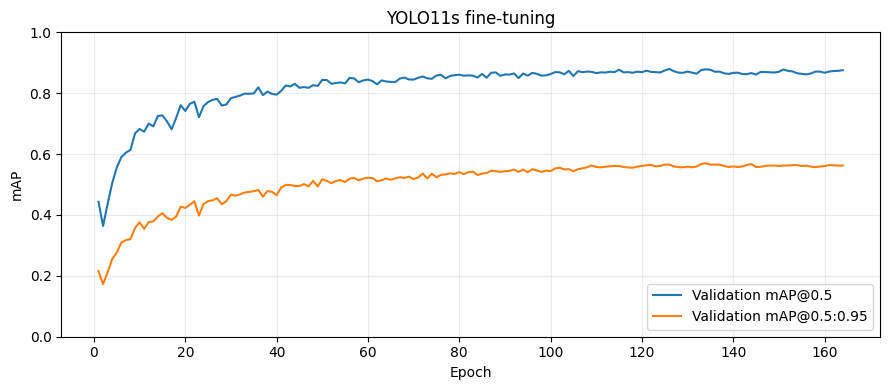

In [ ]:
yolo11s_history = pd.read_csv(YOLO11S_RUN_DIR / "results.csv")
yolo11s_history.columns = yolo11s_history.columns.str.strip()

print(f"Completed epochs: {int(yolo11s_history['epoch'].max())}")
print(f"Selected checkpoint: {YOLO11S_CHECKPOINT}")
print(f"Checkpoint SHA-256: {file_sha256(YOLO11S_CHECKPOINT)}")

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    yolo11s_history["epoch"],
    yolo11s_history["metrics/mAP50(B)"],
    label="Validation mAP@0.5",
)

ax.plot(
    yolo11s_history["epoch"],
    yolo11s_history["metrics/mAP50-95(B)"],
    label="Validation mAP@0.5:0.95",
)

ax.set(
    xlabel="Epoch",
    ylabel="mAP",
    title="YOLO11s fine-tuning",
    ylim=(0, 1),
)

ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

fig.savefig(
    YOLO11S_RUN_DIR / "validation_learning_curves.png",
    dpi=300,
)
fig.savefig(
    YOLO11S_RUN_DIR / "validation_learning_curves.pdf",
)

plt.show()

### 3.5 YOLO11l Training Configuration
Apply the shared YOLO training recipe to YOLO11l, using the same seed, image size, epoch budget and early-stopping settings.

In [ ]:
YOLO11L_TRAIN_ARGS = dict(YOLO_TRAIN_ARGS)

print(json.dumps(YOLO11L_TRAIN_ARGS, indent=2))

{
  "epochs": 500,
  "patience": 30,
  "imgsz": 640,
  "batch": 8,
  "workers": 2,
  "seed": 42,
  "deterministic": true,
  "optimizer": "AdamW",
  "lr0": 0.001,
  "lrf": 0.01,
  "weight_decay": 0.0005,
  "warmup_epochs": 3.0,
  "warmup_bias_lr": 0.0,
  "cos_lr": false,
  "amp": true,
  "rect": false,
  "cache": false,
  "mosaic": 1.0,
  "close_mosaic": 10,
  "mixup": 0.0,
  "fliplr": 0.5,
  "val": true,
  "split": "val",
  "save": true,
  "plots": true
}


### 3.6 YOLO11l Fine-Tuning
Train YOLO11l from COCO weights, resume an interrupted run, or load its completed checkpoint.

In [ ]:
yolo11l_model, YOLO11L_RUN_DIR = load_or_train_model(
    "yolo11l",
    YOLO11L_TRAIN_ARGS,
)
TRAINING_RUN_DIRS["yolo11l"] = YOLO11L_RUN_DIR
YOLO11L_CHECKPOINT = YOLO11L_RUN_DIR / "weights" / "best.pt"

print(f"{MODEL_LABELS['yolo11l']} checkpoint: {YOLO11L_CHECKPOINT}")
yolo11l_model.to("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading completed training: /content/drive/MyDrive/fire_smoke_robustness/models/yolo11l/5849468923f4dbf7
YOLO11l checkpoint: /content/drive/MyDrive/fire_smoke_robustness/models/yolo11l/5849468923f4dbf7/weights/best.pt


### 3.7 YOLO11l Training Summary
Inspect the validation learning curves and identify the selected checkpoint.

Completed epochs: 217
Selected checkpoint: /content/drive/MyDrive/fire_smoke_robustness/models/yolo11l/5849468923f4dbf7/weights/best.pt
Checkpoint SHA-256: af49a2c61a23ed402749da9fe92df5f9aad9e038e8b3998dd154aaa269751d54


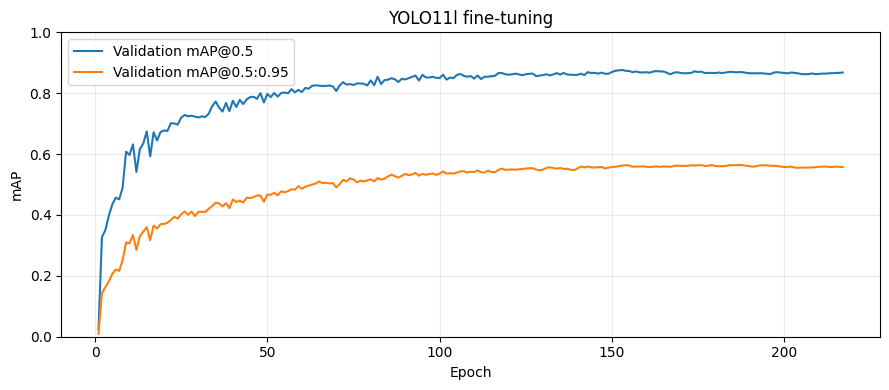

In [ ]:
yolo11l_history = pd.read_csv(YOLO11L_RUN_DIR / "results.csv")
yolo11l_history.columns = yolo11l_history.columns.str.strip()

print(f"Completed epochs: {int(yolo11l_history['epoch'].max())}")
print(f"Selected checkpoint: {YOLO11L_CHECKPOINT}")
print(f"Checkpoint SHA-256: {file_sha256(YOLO11L_CHECKPOINT)}")

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    yolo11l_history["epoch"],
    yolo11l_history["metrics/mAP50(B)"],
    label="Validation mAP@0.5",
)

ax.plot(
    yolo11l_history["epoch"],
    yolo11l_history["metrics/mAP50-95(B)"],
    label="Validation mAP@0.5:0.95",
)

ax.set(
    xlabel="Epoch",
    ylabel="mAP",
    title="YOLO11l fine-tuning",
    ylim=(0, 1),
)

ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

fig.savefig(
    YOLO11L_RUN_DIR / "validation_learning_curves.png",
    dpi=300,
)
fig.savefig(
    YOLO11L_RUN_DIR / "validation_learning_curves.pdf",
)

plt.show()

### 3.8 RT-DETR-L Training Configuration
Configure fine-tuning for up to 500 epochs with patience 30, using FP32 and a fixed training seed.

In [ ]:
RTDETR_L_TRAIN_ARGS = {
    "epochs": 500,
    "patience": 30,
    "imgsz": PROJECT_CONFIG["evaluation"]["imgsz"],
    "batch": 8,
    "workers": 2,

    "seed": PROJECT_CONFIG["seeds"]["training"],
    "deterministic": False,

    "optimizer": "AdamW",
    "lr0": 0.0001,
    "lrf": 0.01,
    "momentum": 0.9,
    "weight_decay": 0.0001,
    "warmup_epochs": 3.0,
    "warmup_bias_lr": 0.0,
    "cos_lr": False,

    "amp": True,
    "rect": False,
    "cache": False,

    "mosaic": 1.0,
    "close_mosaic": 10,
    "mixup": 0.0,
    "fliplr": 0.5,

    "val": True,
    "split": "val",
    "save": True,
    "plots": True,
}

print(json.dumps(RTDETR_L_TRAIN_ARGS, indent=2))

{
  "epochs": 500,
  "patience": 30,
  "imgsz": 640,
  "batch": 8,
  "workers": 2,
  "seed": 42,
  "deterministic": false,
  "optimizer": "AdamW",
  "lr0": 0.0001,
  "lrf": 0.01,
  "momentum": 0.9,
  "weight_decay": 0.0001,
  "warmup_epochs": 3.0,
  "warmup_bias_lr": 0.0,
  "cos_lr": false,
  "amp": true,
  "rect": false,
  "cache": false,
  "mosaic": 1.0,
  "close_mosaic": 10,
  "mixup": 0.0,
  "fliplr": 0.5,
  "val": true,
  "split": "val",
  "save": true,
  "plots": true
}


### 3.9 RT-DETR-L Fine-Tuning
Train RT-DETR-L from COCO weights, resume an interrupted run, or load its completed checkpoint.

In [ ]:
rtdetr_l_model, RTDETR_L_RUN_DIR = load_or_train_model(
    "rtdetr_l",
    RTDETR_L_TRAIN_ARGS,
)
TRAINING_RUN_DIRS["rtdetr_l"] = RTDETR_L_RUN_DIR
RTDETR_L_CHECKPOINT = RTDETR_L_RUN_DIR / "weights" / "best.pt"

print(f"{MODEL_LABELS['rtdetr_l']} checkpoint: {RTDETR_L_CHECKPOINT}")
rtdetr_l_model.to("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Loading completed training: /content/drive/MyDrive/fire_smoke_robustness/models/rtdetr_l/cd904d7995830c66
RT-DETR-L checkpoint: /content/drive/MyDrive/fire_smoke_robustness/models/rtdetr_l/cd904d7995830c66/weights/best.pt


### 3.10 RT-DETR-L Training Summary
Inspect the validation learning curves and identify the selected checkpoint.

Completed epochs: 90
Selected checkpoint: /content/drive/MyDrive/fire_smoke_robustness/models/rtdetr_l/cd904d7995830c66/weights/best.pt
Checkpoint SHA-256: cc9f7075eac01d8ae00000969d7223260c90831eb0a041778bd3116d23e69380


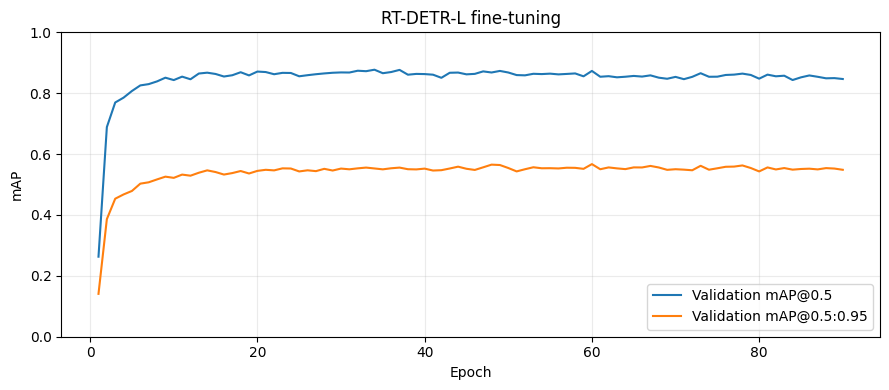

In [ ]:
rtdetr_l_history = pd.read_csv(RTDETR_L_RUN_DIR / "results.csv")
rtdetr_l_history.columns = rtdetr_l_history.columns.str.strip()

print(f"Completed epochs: {int(rtdetr_l_history['epoch'].max())}")
print(f"Selected checkpoint: {RTDETR_L_CHECKPOINT}")
print(f"Checkpoint SHA-256: {file_sha256(RTDETR_L_CHECKPOINT)}")

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    rtdetr_l_history["epoch"],
    rtdetr_l_history["metrics/mAP50(B)"],
    label="Validation mAP@0.5",
)

ax.plot(
    rtdetr_l_history["epoch"],
    rtdetr_l_history["metrics/mAP50-95(B)"],
    label="Validation mAP@0.5:0.95",
)

ax.set(
    xlabel="Epoch",
    ylabel="mAP",
    title="RT-DETR-L fine-tuning",
    ylim=(0, 1),
)

ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

fig.savefig(
    RTDETR_L_RUN_DIR / "validation_learning_curves.png",
    dpi=300,
)
fig.savefig(
    RTDETR_L_RUN_DIR / "validation_learning_curves.pdf",
)

plt.show()

### 3.11 Selected Model Registry
Verify and register both completed checkpoints for subsequent calibration and evaluation.

In [ ]:
missing_models = [key for key in MODEL_KEYS if key not in TRAINING_RUN_DIRS]
if missing_models:
    raise RuntimeError(
        f"Missing model runs: {missing_models}. "
        "Run the training/loading cells 3.3, 3.6 and 3.9 first."
    )

selected_runs = {key: TRAINING_RUN_DIRS[key] for key in MODEL_KEYS}

MODEL_REGISTRY = {
    "schema_version": 1,
    "dataset_fingerprint": DATASET_FINGERPRINT,
    "models": {},
}

training_summary_rows = []

for model_key, run_dir in selected_runs.items():
    run_dir = Path(run_dir)

    protocol_path = run_dir / "protocol.json"
    completion_path = run_dir / "completed.json"
    checkpoint_path = run_dir / "weights" / "best.pt"

    if not completion_path.is_file():
        raise RuntimeError(
            f"Training is not registered as complete: {model_key}"
        )

    protocol = json.loads(protocol_path.read_text(encoding="utf-8"))
    completion = json.loads(
        completion_path.read_text(encoding="utf-8")
    )

    if (
        protocol["model_key"] != model_key
        or protocol["dataset_fingerprint"] != DATASET_FINGERPRINT
        or completion["run_id"] != content_id(protocol)
    ):
        raise RuntimeError(
            f"Training provenance mismatch: {model_key}"
        )

    checkpoint_sha256 = file_sha256(checkpoint_path)

    if checkpoint_sha256 != completion["best_sha256"]:
        raise RuntimeError(
            f"Checkpoint checksum mismatch: {model_key}"
        )

    MODEL_REGISTRY["models"][model_key] = {
        "run_id": completion["run_id"],
        "checkpoint": str(checkpoint_path),
        "checkpoint_sha256": checkpoint_sha256,
        "training_protocol": str(protocol_path),
        "completion_record": str(completion_path),
    }

    settings = protocol["training_args"]

    training_summary_rows.append({
        "model": model_key,
        "max_epochs": settings["epochs"],
        "completed_epochs": completion["epochs_completed"],
        "patience": settings["patience"],
        "batch": settings["batch"],
        "lr0": settings["lr0"],
        "amp": settings["amp"],
        "seed": settings["seed"],
    })

MODEL_REGISTRY_PATH = PATHS["configs"] / "selected_models.json"

update_registry_json(
    MODEL_REGISTRY_PATH,
    MODEL_REGISTRY,
)

training_summary = pd.DataFrame(training_summary_rows)

print(training_summary.to_string(index=False))
print(f"\nSelected model registry: {MODEL_REGISTRY_PATH}")

   model  max_epochs  completed_epochs  patience  batch    lr0  amp  seed
 yolo11s         500               164        30      8 0.0010 True    42
 yolo11l         500               217        30      8 0.0010 True    42
rtdetr_l         500                90        30      8 0.0001 True    42

Selected model registry: /content/drive/MyDrive/fire_smoke_robustness/configs/selected_models.json


## 4. Confidence Threshold Selection
Select one threshold per model by maximizing macro-F2 on the complete validation set.

### 4.1. Models and configuration
Read the checkpoint registry and define the candidate confidence thresholds.

In [ ]:
from ultralytics.cfg import DEFAULT_CFG_DICT
from tqdm.auto import tqdm

MODEL_REGISTRY = json.loads(
    (PATHS["configs"] / "selected_models.json").read_text()
)

assert DATASET_VERIFIED, "Run Sections 1 and 2 first."
assert MODEL_REGISTRY["dataset_fingerprint"] == DATASET_FINGERPRINT

CLASS_NAMES = PROJECT_CONFIG["dataset"]["class_names"]
VALID_ROWS = (
    dataset_manifest.query("split == 'valid'")
    .sort_values("image_path")
    .to_dict("records")
)
assert len(VALID_ROWS) == PROJECT_CONFIG["dataset"]["expected_images"]["valid"], "Use the complete validation split."

THRESHOLDS = np.arange(1, 1001) / 1000
PRECISION_ARGS = (
    {"quantize": 32}
    if "quantize" in DEFAULT_CFG_DICT
    else {"half": False}
)

for entry in MODEL_REGISTRY["models"].values():
    assert file_sha256(entry["checkpoint"]) == entry["checkpoint_sha256"]

THRESHOLD_CONFIG = {
    "implementation": "simple_macro_f2_v1",
    "dataset_fingerprint": DATASET_FINGERPRINT,
    "checkpoints": {
        key: entry["checkpoint_sha256"]
        for key, entry in MODEL_REGISTRY["models"].items()
    },
    "objective": "mean_class_f2",
    "split": "valid",
    "thresholds": THRESHOLDS.tolist(),
    "tie_break": "lowest_threshold",
    "tie_tolerance": 1e-12,
    "matching_iou": 0.5,
    "imgsz": 640,
    "max_det": 300,
    "confidence_floor": 0.0001,
    "nms_iou": 0.7,
    "batch": 8,
    "precision": PRECISION_ARGS,
    "allow_tf32": False,
    "seed": 42,
    "environment": ENVIRONMENT,
}


# Keep the selected calibration stable across unrelated Colab environment changes.
saved_calibrations = []
for path in calibration_protocol_paths():
    saved = json.loads(path.read_text())
    if "environment" in saved and calibration_settings(saved) == calibration_settings(THRESHOLD_CONFIG):
        saved_calibrations.append(path)
registry_path = PATHS["configs"] / "selected_thresholds.json"
active_protocol = Path(json.loads(registry_path.read_text())["protocol"]) if registry_path.is_file() else None
if saved_calibrations:
    saved_protocol = active_protocol if active_protocol in saved_calibrations else max(
        saved_calibrations, key=lambda p: max((f.stat().st_mtime_ns for f in p.parent.glob("*.csv")), default=p.stat().st_mtime_ns)
    )
    THRESHOLD_CONFIG = json.loads(saved_protocol.read_text())
    CALIBRATION_ID = saved_protocol.parent.name
else:
    CALIBRATION_ID = content_id(THRESHOLD_CONFIG)
THRESHOLD_RUN_DIR = (
    PATHS["experiments"] / "threshold_selection" / CALIBRATION_ID
)
THRESHOLD_RUN_DIR.mkdir(parents=True, exist_ok=True)
save_or_check_json(THRESHOLD_RUN_DIR / "protocol.json", THRESHOLD_CONFIG)

print(f"Validation: {len(VALID_ROWS)} images.")
print(f"Candidate thresholds: {len(THRESHOLDS)}.")

Validation: 750 images.
Candidate thresholds: 1000.


### 4.2. Validation predictions and F2 calculation
Run each model once and compute class-level and micro metrics across all candidate thresholds.

In [ ]:
def match_predictions(pred, row):
    """Match boxes by descending confidence, same class and IoU >= 0.50."""
    label_path = DATASET_ROOT / row["label_path"]
    labels = (
        np.loadtxt(label_path, ndmin=2)
        if label_path.read_text().strip()
        else np.empty((0, 5))
    )

    # Convert normalized YOLO annotations to pixel coordinates.
    center = labels[:, 1:3] * [row["width"], row["height"]]
    size = labels[:, 3:5] * [row["width"], row["height"]]
    gt = np.column_stack((center - size / 2, center + size / 2))

    for boxes in (pred, gt):
        boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, row["width"])
        boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, row["height"])

    # Use a fixed ordering when confidence scores are equal.
    order = np.lexsort((
        pred[:, 3], pred[:, 2], pred[:, 1],
        pred[:, 0], pred[:, 5], -pred[:, 4],
    ))
    pred = pred[order]

    # Compute IoU between every prediction and ground-truth box.
    intersection = np.maximum(
        np.minimum(pred[:, None, 2:4], gt[None, :, 2:4])
        - np.maximum(pred[:, None, :2], gt[None, :, :2]),
        0,
    ).prod(axis=2)

    area_pred = np.maximum(
        pred[:, 2:4] - pred[:, :2], 0
    ).prod(axis=1)
    area_gt = np.maximum(
        gt[:, 2:4] - gt[:, :2], 0
    ).prod(axis=1)

    union = area_pred[:, None] + area_gt[None, :] - intersection
    iou = np.divide(
        intersection, union,
        out=np.zeros_like(intersection),
        where=union > 0,
    )

    correct = np.zeros(len(pred), dtype=bool)
    used = np.zeros(len(gt), dtype=bool)

    for i, detection in enumerate(pred):
        candidates = np.flatnonzero(
            (labels[:, 0] == detection[5]) & ~used
        )
        if len(candidates):
            best = candidates[np.argmax(iou[i, candidates])]
            if iou[i, best] >= THRESHOLD_CONFIG["matching_iou"]:
                correct[i] = True
                used[best] = True

    support = np.bincount(labels[:, 0].astype(int), minlength=2)
    return pred, correct, support


set_seed(THRESHOLD_CONFIG["seed"])
torch.backends.cudnn.benchmark = False
torch.backends.fp32_precision = "ieee"
torch.backends.cuda.matmul.fp32_precision = "ieee"
torch.backends.cudnn.fp32_precision = "ieee"
torch.backends.cudnn.conv.fp32_precision = "ieee"

def validate_calibration_curve(curve):
    assert len(curve) == len(THRESHOLDS) and curve["threshold"].is_unique
    assert np.allclose(curve["threshold"], THRESHOLDS, rtol=0, atol=1e-12)
    assert np.isfinite(curve.to_numpy()).all()
    support = dataset_manifest.loc[dataset_manifest["split"] == "valid", CLASS_NAMES].sum()
    for label in [*CLASS_NAMES, "micro"]:
        tp, fp, fn = (curve[f"{label}_{name}"].to_numpy() for name in ["tp", "fp", "fn"])
        assert all((x >= 0).all() and np.equal(x, np.floor(x)).all() for x in [tp, fp, fn])
        expected_support = support.sum() if label == "micro" else support[label]
        assert np.equal(tp + fn, expected_support).all()
        for metric, expected in {
            "precision": tp / np.maximum(tp + fp, 1), "recall": tp / np.maximum(tp + fn, 1),
            "f1": 2 * tp / np.maximum(2 * tp + fp + fn, 1),
            "f2": 5 * tp / np.maximum(5 * tp + fp + 4 * fn, 1),
        }.items():
            assert np.allclose(curve[f"{label}_{metric}"], expected, rtol=0, atol=1e-12)
    for metric in ["tp", "fp", "fn"]:
        assert np.array_equal(curve[f"micro_{metric}"], curve[[f"{c}_{metric}" for c in CLASS_NAMES]].sum(axis=1))
    assert np.allclose(curve["macro_f2"], curve[[f"{c}_f2" for c in CLASS_NAMES]].mean(axis=1), rtol=0, atol=1e-12)

CALIBRATION_CURVES = {}

for model_key in MODEL_KEYS:
    model_class = MODEL_CLASSES[model_key]
    curve = load_saved_csv(
        THRESHOLD_RUN_DIR, [f"{model_key}_threshold_curve.csv"], validate_calibration_curve, model_key=model_key
    )
    if curve is not None:
        CALIBRATION_CURVES[model_key] = curve
        continue

    model = model_class(
        MODEL_REGISTRY["models"][model_key]["checkpoint"]
    )
    assert [model.names[i] for i in range(2)] == CLASS_NAMES

    predictions, flags = [], []
    support = np.zeros(2, dtype=int)

    results = model.predict(
        source=[
            str(DATASET_ROOT / row["image_path"])
            for row in VALID_ROWS
        ],
        stream=True,
        device=DEVICE,
        imgsz=THRESHOLD_CONFIG["imgsz"],
        rect=False,
        conf=THRESHOLD_CONFIG["confidence_floor"],
        iou=THRESHOLD_CONFIG["nms_iou"],
        max_det=THRESHOLD_CONFIG["max_det"],
        batch=THRESHOLD_CONFIG["batch"],
        classes=None,
        agnostic_nms=False,
        augment=False,
        save=False,
        save_txt=False,
        verbose=False,
        **PRECISION_ARGS,
    )

    for row, result in tqdm(
        zip(VALID_ROWS, results),
        total=len(VALID_ROWS),
        desc=model_key,
    ):
        assert Path(result.path).resolve() == (
            DATASET_ROOT / row["image_path"]
        ).resolve()

        pred = result.boxes.data.cpu().numpy().astype(np.float64)
        pred, correct, n_gt = match_predictions(pred, row)

        predictions.append(pred)
        flags.append(correct)
        support += n_gt

    assert len(predictions) == len(VALID_ROWS), "Incomplete validation inference."

    pred = np.concatenate(predictions)
    correct = np.concatenate(flags)
    counts = {}

    # Count retained TP, FP and FN at every threshold.
    for class_id, name in enumerate(CLASS_NAMES):
        mask = pred[:, 5] == class_id
        scores, tp_flags = pred[mask, 4], correct[mask]
        order = np.argsort(-scores, kind="stable")

        kept = np.searchsorted(
            -scores[order], -THRESHOLDS, side="right"
        )
        tp = np.r_[0, np.cumsum(tp_flags[order])][kept]
        counts[name] = (tp, kept - tp, support[class_id] - tp)

    counts["micro"] = np.sum(list(counts.values()), axis=0)
    curve = pd.DataFrame({"threshold": THRESHOLDS})

    for name, (tp, fp, fn) in counts.items():
        values = {
            "tp": tp,
            "fp": fp,
            "fn": fn,
            "precision": tp / np.maximum(tp + fp, 1),
            "recall": tp / np.maximum(tp + fn, 1),
            "f1": 2 * tp / np.maximum(2 * tp + fp + fn, 1),
            "f2": 5 * tp / np.maximum(5 * tp + fp + 4 * fn, 1),
        }
        for metric, value in values.items():
            curve[f"{name}_{metric}"] = value

    curve["macro_f2"] = curve[
        [f"{name}_f2" for name in CLASS_NAMES]
    ].mean(axis=1)

    validate_calibration_curve(curve)
    curve.to_csv(THRESHOLD_RUN_DIR / f"{model_key}_threshold_curve.csv", index=False)
    CALIBRATION_CURVES[model_key] = curve

    model.to("cpu")
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/threshold_selection/7fdc19dbd80363d7/yolo11s_threshold_curve.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/threshold_selection/7fdc19dbd80363d7/yolo11l_threshold_curve.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/threshold_selection/7fdc19dbd80363d7/rtdetr_l_threshold_curve.csv


### 4.3. Selected thresholds and results
Save the threshold with the highest macro-F2 for each model and plot the validation curves.

yolo11s: confidence=0.240, macro-F2=0.8420
yolo11l: confidence=0.223, macro-F2=0.8393
rtdetr_l: confidence=0.379, macro-F2=0.8508
   model  confidence class  tp  fp  fn  precision  recall     f1     f2
 yolo11s      0.2400  Fire 480 161  67     0.7488  0.8775 0.8081 0.8484
 yolo11s      0.2400 Smoke 424 129  72     0.7667  0.8548 0.8084 0.8356
 yolo11s      0.2400 micro 904 290 139     0.7571  0.8667 0.8082 0.8423
 yolo11l      0.2230  Fire 480 147  67     0.7656  0.8775 0.8177 0.8526
 yolo11l      0.2230 Smoke 417 123  79     0.7722  0.8407 0.8050 0.8261
 yolo11l      0.2230 micro 897 270 146     0.7686  0.8600 0.8118 0.8400
rtdetr_l      0.3790  Fire 486 128  61     0.7915  0.8885 0.8372 0.8672
rtdetr_l      0.3790 Smoke 426 143  70     0.7487  0.8589 0.8000 0.8343
rtdetr_l      0.3790 micro 912 271 131     0.7709  0.8744 0.8194 0.8515
Thresholds saved to: /content/drive/MyDrive/fire_smoke_robustness/configs/selected_thresholds.json


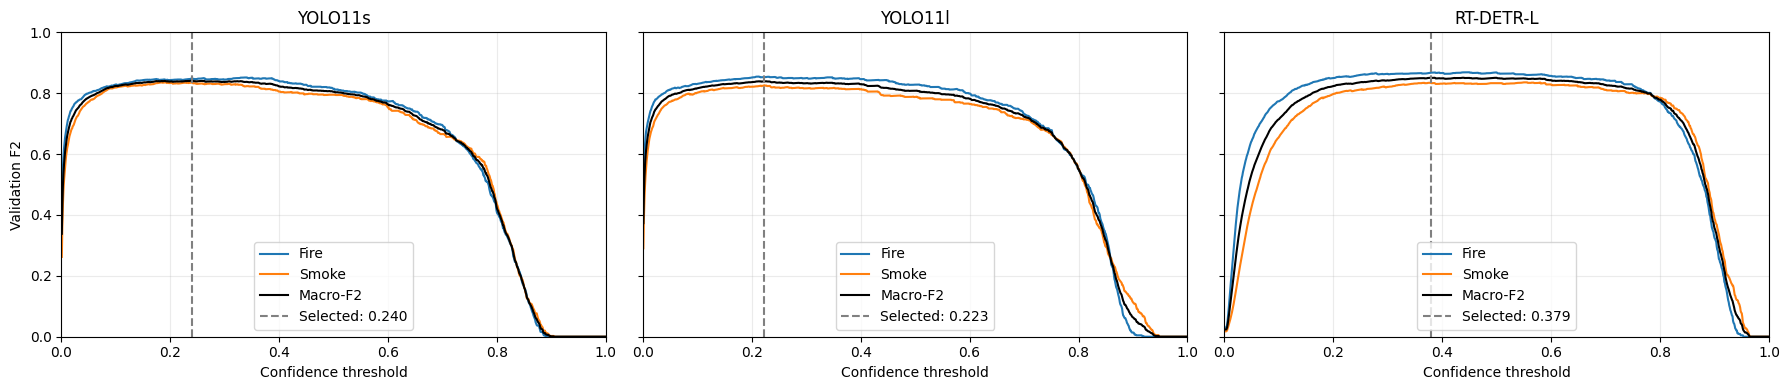

In [ ]:
THRESHOLD_REGISTRY = {
    "schema_version": 2,
    "calibration_id": CALIBRATION_ID,
    "objective": "mean_class_f2",
    "beta": 2,
    "dataset_fingerprint": DATASET_FINGERPRINT,
    "protocol": str(THRESHOLD_RUN_DIR / "protocol.json"),
    "models": {},
}

summary = []
fig, axes = plt.subplots(1, len(CALIBRATION_CURVES), figsize=(6 * len(CALIBRATION_CURVES), 4), sharey=True, squeeze=False)
axes = axes[0]

for ax, (model_key, curve) in zip(axes, CALIBRATION_CURVES.items()):
    # The first tied maximum corresponds to the lowest threshold.
    best = curve.loc[np.isclose(
        curve["macro_f2"],
        curve["macro_f2"].max(),
        rtol=0,
        atol=1e-12,
    )].iloc[0]

    threshold = float(best["threshold"])
    print(
        f"{model_key}: confidence={threshold:.3f}, "
        f"macro-F2={best['macro_f2']:.4f}"
    )

    curve.to_csv(
        THRESHOLD_RUN_DIR / f"{model_key}_threshold_curve.csv",
        index=False,
    )

    THRESHOLD_REGISTRY["models"][model_key] = {
        "checkpoint_sha256": (
            MODEL_REGISTRY["models"][model_key]["checkpoint_sha256"]
        ),
        "confidence_threshold": threshold,
        "validation_metrics": {
            key: (
                int(value)
                if key.endswith(("_tp", "_fp", "_fn"))
                else float(value)
            )
            for key, value in best.items()
            if key != "threshold"
        },
    }

    for name in [*CLASS_NAMES, "micro"]:
        summary.append({
            "model": model_key,
            "confidence": threshold,
            "class": name,
            **{
                m: int(best[f"{name}_{m}"])
                for m in ("tp", "fp", "fn")
            },
            **{
                m: float(best[f"{name}_{m}"])
                for m in ("precision", "recall", "f1", "f2")
            },
        })

    for name in CLASS_NAMES:
        ax.plot(
            curve["threshold"], curve[f"{name}_f2"], label=name
        )

    ax.plot(
        curve["threshold"], curve["macro_f2"],
        color="black", label="Macro-F2",
    )
    ax.axvline(
        threshold, color="gray", linestyle="--",
        label=f"Selected: {threshold:.3f}",
    )
    ax.set(
        title=MODEL_LABELS[model_key],
        xlabel="Confidence threshold",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.grid(alpha=0.25)
    ax.legend()

save_or_check_json(
    THRESHOLD_RUN_DIR / "protocol.json",
    THRESHOLD_CONFIG,
)
selection_path = THRESHOLD_RUN_DIR / "selected_thresholds.json"
if selection_path.is_file():
    saved_selection = json.loads(selection_path.read_text())
    for model_key, entry in THRESHOLD_REGISTRY["models"].items():
        saved_entry = saved_selection["models"][model_key]
        assert entry["checkpoint_sha256"] == saved_entry["checkpoint_sha256"]
        assert np.isclose(entry["confidence_threshold"], saved_entry["confidence_threshold"], rtol=0, atol=1e-12)
        assert entry["validation_metrics"].keys() == saved_entry["validation_metrics"].keys()
        assert all(np.isclose(value, saved_entry["validation_metrics"][key], rtol=0, atol=1e-12) for key, value in entry["validation_metrics"].items())
    THRESHOLD_REGISTRY = saved_selection

save_or_check_json(
    THRESHOLD_RUN_DIR / "selected_thresholds.json",
    THRESHOLD_REGISTRY,
)

# Preserve the previous selection before updating the active registry.
registry_path = PATHS["configs"] / "selected_thresholds.json"
if registry_path.exists():
    previous = json.loads(registry_path.read_text())
    save_or_check_json(
        PATHS["configs"] / "threshold_history"
        / f"{content_id(previous)}.json",
        previous,
    )

temporary = registry_path.with_suffix(".json.tmp")
temporary.write_text(
    json.dumps(THRESHOLD_REGISTRY, indent=2, allow_nan=False) + "\n"
)
temporary.replace(registry_path)

threshold_summary = pd.DataFrame(summary)
threshold_summary.to_csv(
    THRESHOLD_RUN_DIR / "validation_metrics.csv",
    index=False,
)
print(
    threshold_summary.to_string(
        index=False, float_format=lambda x: f"{x:.4f}"
    )
)
print(f"Thresholds saved to: {registry_path}")

axes[0].set_ylabel("Validation F2")
fig.tight_layout()
fig.savefig(THRESHOLD_RUN_DIR / "confidence_selection.png", dpi=300)
fig.savefig(THRESHOLD_RUN_DIR / "confidence_selection.pdf")
plt.show()

## 5. Evaluation and Attack Protocol
Load the fixed thresholds and define the shared settings for clean and adversarial evaluation.

### 5.1. Load checkpoints and thresholds
Restore the selected model paths and confidence thresholds from Google Drive.

In [ ]:
MODEL_REGISTRY = json.loads(
    (PATHS["configs"] / "selected_models.json").read_text()
)
THRESHOLD_REGISTRY = json.loads(
    (PATHS["configs"] / "selected_thresholds.json").read_text()
)
SELECTION_CONFIG = json.loads(
    Path(THRESHOLD_REGISTRY["protocol"]).read_text()
)

assert DATASET_VERIFIED, "Run Sections 1 and 2 first."
assert MODEL_REGISTRY["dataset_fingerprint"] == DATASET_FINGERPRINT
assert THRESHOLD_REGISTRY["dataset_fingerprint"] == DATASET_FINGERPRINT

MODEL_PATHS, CONFIDENCE_THRESHOLDS = {}, {}

for model_key in MODEL_KEYS:
    model_entry = MODEL_REGISTRY["models"][model_key]
    threshold_entry = THRESHOLD_REGISTRY["models"][model_key]

    assert (
        model_entry["checkpoint_sha256"]
        == threshold_entry["checkpoint_sha256"]
    )
    assert (
        file_sha256(model_entry["checkpoint"])
        == model_entry["checkpoint_sha256"]
    )

    MODEL_PATHS[model_key] = model_entry["checkpoint"]
    CONFIDENCE_THRESHOLDS[model_key] = (
        threshold_entry["confidence_threshold"]
    )

    print(
        f"{model_key}: confidence = "
        f"{CONFIDENCE_THRESHOLDS[model_key]:.3f}"
    )

TEST_ROWS = (
    dataset_manifest.query("split == 'test'")
    .sort_values("image_path")
    .to_dict("records")
)

assert (
    len(TEST_ROWS)
    == PROJECT_CONFIG["dataset"]["expected_images"]["test"]
)

yolo11s: confidence = 0.240
yolo11l: confidence = 0.223
rtdetr_l: confidence = 0.379


### 5.2. Experiment settings
Preserve the calibration settings and define epsilon values, attack seeds and PGD parameters.

In [ ]:
EPSILON_255 = PROJECT_CONFIG["attacks"]["epsilon_255"]
PGD_STEPS = PROJECT_CONFIG["attacks"]["pgd_steps"]
ATTACK_SEEDS = PROJECT_CONFIG["seeds"]["attacks"]

EVALUATION_CONFIG = {
    key: SELECTION_CONFIG[key]
    for key in (
        "imgsz",
        "max_det",
        "matching_iou",
        "confidence_floor",
        "nms_iou",
        "precision",
        "allow_tf32",
    )
}
EVALUATION_CONFIG.update({
    "split": "test",
    "confidence_thresholds": CONFIDENCE_THRESHOLDS,
    "matching": "confidence_order_best_unused_same_class",
    "score_comparison": ">=",
})

EXPERIMENT_PROTOCOL = {
    "schema_version": 1,
    "dataset_fingerprint": DATASET_FINGERPRINT,
    "threshold_calibration_id": THRESHOLD_REGISTRY["calibration_id"],
    "checkpoints": {
        key: MODEL_REGISTRY["models"][key]["checkpoint_sha256"]
        for key in MODEL_PATHS
    },
    "evaluation": EVALUATION_CONFIG,
    "attacks": {
        "norm": "Linf",
        "space": "decoded_rgb_before_spatial_preprocessing",
        "pixel_range": [0.0, 1.0],
        "epsilon_255": EPSILON_255,
        "seeds": ATTACK_SEEDS,
        "random_noise": "random_signs",
        "fgsm_random_start": False,
        "pgd_steps": PGD_STEPS,
        "pgd_alpha_ratio": (
            PROJECT_CONFIG["attacks"]["pgd_alpha_ratio"]
        ),
        "pgd_random_start": "uniform_in_epsilon_ball_then_clip",
        "pgd_output": "last_iterate",
        "objective": "untargeted_maximize_native_detection_loss",
        "seed_rule": "sha256_seed_relative_path_v1",
    },
}

PROTOCOL_ID = content_id(EXPERIMENT_PROTOCOL)
PROTOCOL_PATH = (
    PATHS["configs"] / "protocols" / f"{PROTOCOL_ID}.json"
)

save_or_check_json(PROTOCOL_PATH, EXPERIMENT_PROTOCOL)
print(f"Protocol saved to: {PROTOCOL_PATH}")

Protocol saved to: /content/drive/MyDrive/fire_smoke_robustness/configs/protocols/b3e24edd0c8a10fa.json


### 5.3. Image dimensions and reproducible seeds
Check validation/test image dimensions and define a stable random seed for each image.

In [ ]:
def image_seed(relative_path, base_seed):
    """Pair random initialization by image and seed across PGD step counts."""
    text = f"{base_seed}|{relative_path}".encode("utf-8")
    return (
        int.from_bytes(hashlib.sha256(text).digest()[:8], "big")
        % (2**63 - 1)
    )


geometry = (
    dataset_manifest.query("split in ['valid', 'test']")
    .groupby(["split", "width", "height"])
    .size()
    .reset_index(name="images")
)

print(geometry.head(10).to_string(index=False))

if len(geometry) > 10:
    print(f"Showing 10 of {len(geometry)} dimension groups.")

NATIVE_SIZE_INPUTS = bool(
    (geometry["width"] == EVALUATION_CONFIG["imgsz"]).all()
    and (geometry["height"] == EVALUATION_CONFIG["imgsz"]).all()
)

print(
    "\nAll validation/test images match the model input size: "
    f"{NATIVE_SIZE_INPUTS}"
)
print(f"Test images: {len(TEST_ROWS)}")
print(f"Epsilon values /255: {EPSILON_255}")
print(f"PGD steps: {PGD_STEPS}")
print(f"Attack seeds: {ATTACK_SEEDS}")

positive_epsilons = sum(epsilon > 0 for epsilon in EPSILON_255)

runs_per_model = 1 + positive_epsilons * (
    1 + len(ATTACK_SEEDS) * (1 + len(PGD_STEPS))
)

print(
    f"Planned evaluations per model: {runs_per_model} "
    "(one clean reference included)."
)

split  width  height  images
 test    224     224      37
 test    240     240      12
 test    259     194       1
 test    360     176       7
 test    360     178       9
 test    416     416     145
 test    478     358      18
 test    480     320       5
 test    640     245       1
 test    640     339       1
Showing 10 of 51 dimension groups.

All validation/test images match the model input size: False
Test images: 750
Epsilon values /255: [0, 1, 2, 4, 8, 16]
PGD steps: [5, 10, 20]
Attack seeds: [42, 43, 44]
Planned evaluations per model: 66 (one clean reference included).


### 5.4 Differentiable preprocessing
Preserve each detector's input geometry while allowing gradients to reach the original RGB pixels.

In [ ]:
import cv2
import torch.nn.functional as F
from ultralytics.data.augment import LetterBox


def rgb_tensor(bgr):
    """Convert a decoded BGR image to a float RGB tensor in [0, 1]."""
    rgb = np.ascontiguousarray(bgr[..., ::-1])
    return torch.from_numpy(rgb).permute(2, 0, 1).unsqueeze(0).float() / 255


def differentiable_preprocess_family(x, family):
    """Resize RGB tensors while preserving gradients to original pixels."""
    size = int(EVALUATION_CONFIG["imgsz"])
    height, width = x.shape[-2:]

    if family == "rtdetr":
        return F.interpolate(
            x, size=(size, size), mode="bilinear", align_corners=False
        )

    if family != "yolo":
        raise ValueError(f"Unknown model family: {family}")

    ratio = min(size / height, size / width)
    new_h, new_w = round(height * ratio), round(width * ratio)

    resized = F.interpolate(
        x, size=(new_h, new_w), mode="bilinear", align_corners=False
    )

    dh, dw = (size - new_h) / 2, (size - new_w) / 2
    padding = (
        round(dw - 0.1), round(dw + 0.1),
        round(dh - 0.1), round(dh + 0.1),
    )
    return F.pad(resized, padding, value=114 / 255)

def differentiable_preprocess(x, model_key):
    """Apply the configured detector geometry to a gradient-carrying RGB tensor."""
    return differentiable_preprocess_family(x, MODEL_FAMILIES[model_key])


### 5.5 Preprocessing check
Compare native and differentiable preprocessing on one validation image per resolution, and check preprocessing gradients.

In [ ]:
probe_rows = (
    dataset_manifest.query("split == 'valid'")
    .sort_values("image_path")
    .drop_duplicates(["width", "height"])
    .to_dict("records")
)

check_dir = PATHS["experiments"] / "protocol_checks" / PROTOCOL_ID
check_dir.mkdir(parents=True, exist_ok=True)
check_dir = resume_result_dir(check_dir)

def validate_preprocessing_checks(frame, model_key=None):
    expected = pd.MultiIndex.from_product(
        [[model_key] if model_key else list(MODEL_PATHS), [row["image_path"] for row in probe_rows]],
        names=["model", "image_path"],
    )
    actual = pd.MultiIndex.from_frame(frame[["model", "image_path"]])
    assert actual.is_unique and len(actual) == len(expected)
    assert expected.difference(actual).empty
    assert frame["gradient_ok"].eq(True).all()
    assert np.isfinite(frame["max_difference_255"]).all()
    assert frame["max_difference_255"].ge(0).all()

checks = []
size = int(EVALUATION_CONFIG["imgsz"])
for model_key in MODEL_PATHS:
    saved = load_saved_csv(
        check_dir, ["preprocessing_checks.csv"],
        lambda frame: validate_preprocessing_checks(frame, model_key), {"model": model_key},
    )
    if saved is not None:
        checks.extend(saved.to_dict("records"))
        continue
    native_transform = LetterBox(
        new_shape=(size, size),
        auto=False,
        scale_fill=(MODEL_FAMILIES[model_key] == "rtdetr"),
    )

    for row in probe_rows:
        bgr = cv2.imread(str(DATASET_ROOT / row["image_path"]))
        assert bgr is not None, row["image_path"]
        assert bgr.shape[:2] == (row["height"], row["width"])

        x = rgb_tensor(bgr).requires_grad_(True)
        transformed = differentiable_preprocess(x, model_key)
        reference = rgb_tensor(native_transform(image=bgr))

        assert transformed.shape == reference.shape == (1, 3, size, size)

        gradient = torch.autograd.grad(transformed.mean(), x)[0]

        checks.append({
            "model": model_key,
            "image_path": row["image_path"],
            "max_difference_255": float(
                (transformed.detach() - reference).abs().max() * 255
            ),
            "gradient_ok": bool(
                torch.isfinite(gradient).all()
                and gradient.abs().max() > 0
            ),
        })

preprocessing_checks = pd.DataFrame(checks)
validate_preprocessing_checks(preprocessing_checks)

preprocessing_checks.to_csv(
    check_dir / "preprocessing_checks.csv", index=False
)

print(preprocessing_checks.groupby("model").agg(
    images_checked=("image_path", "size"),
    max_difference_255=("max_difference_255", "max"),
    preprocessing_gradient_ok=("gradient_ok", "all"),
).to_string())

print("Pixel comparison only; prediction equivalence is not established yet.")

[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/protocol_checks/b3e24edd0c8a10fa/preprocessing_checks.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/protocol_checks/b3e24edd0c8a10fa/preprocessing_checks.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/protocol_checks/b3e24edd0c8a10fa/preprocessing_checks.csv
          images_checked  max_difference_255  preprocessing_gradient_ok
model                                                                  
rtdetr_l              26            0.768273                       True
yolo11l               26            0.768273                       True
yolo11s               26            0.768273                       True
Pixel comparison only; prediction equivalence is not established yet.


### 5.6. Validation metrics with differentiable preprocessing
Compare native and differentiable preprocessing at the selected confidence thresholds.

In [ ]:
from ultralytics.models.yolo.detect.predict import DetectionPredictor
from ultralytics.models.rtdetr.predict import RTDETRPredictor


def preprocess_images(images, family, device):
    return torch.cat([
        differentiable_preprocess_family(
            rgb_tensor(image).to(device), family
        )
        for image in images
    ])


class FloatYOLOPredictor(DetectionPredictor):
    def preprocess(self, images):
        return preprocess_images(images, "yolo", self.device)


class FloatRTDETRPredictor(RTDETRPredictor):
    def preprocess(self, images):
        return preprocess_images(images, "rtdetr", self.device)



def saved_counts(frame, model_key, split="test", micro=True):
    labels = [*CLASS_NAMES, "micro"] if micro else CLASS_NAMES
    assert len(frame) == len(labels) and frame["class"].is_unique
    assert set(frame["class"]) == set(labels) and frame["model"].eq(model_key).all()
    columns = ["tp", "fp", "fn", "precision", "recall", "f2"]
    assert np.isfinite(frame[columns].to_numpy()).all()
    if "confidence" in frame:
        assert np.allclose(frame["confidence"], CONFIDENCE_THRESHOLDS[model_key], rtol=0, atol=1e-12)
    counts = frame.set_index("class").loc[CLASS_NAMES, ["tp", "fp", "fn"]].to_numpy()
    assert (counts >= 0).all() and np.equal(counts, np.floor(counts)).all()
    support = dataset_manifest.loc[dataset_manifest["split"] == split, CLASS_NAMES].sum().to_numpy()
    assert np.array_equal(counts[:, 0] + counts[:, 2], support)
    if micro:
        assert np.array_equal(counts.sum(axis=0), frame.set_index("class").loc["micro", ["tp", "fp", "fn"]].to_numpy())
    tp, fp, fn = (frame[key].to_numpy() for key in ["tp", "fp", "fn"])
    for metric, expected in {
        "precision": tp / np.maximum(tp + fp, 1), "recall": tp / np.maximum(tp + fn, 1),
        "f1": 2 * tp / np.maximum(2 * tp + fp + fn, 1), "f2": 5 * tp / np.maximum(5 * tp + fp + 4 * fn, 1),
    }.items():
        if metric in frame:
            assert np.allclose(frame[metric], expected, rtol=0, atol=1e-12)
    return counts.astype(int)


def validate_saved_comparison(frame, model_key):
    assert len(frame) == 2 * len(CLASS_NAMES)
    for method in ["native", "differentiable"]:
        counts = saved_counts(frame[frame["preprocessing"] == method], model_key, "valid", micro=False)
        if method == "native":
            reference = THRESHOLD_REGISTRY["models"][model_key]["validation_metrics"]
            assert np.array_equal(counts, [[reference[f"{name}_{m}"] for m in ["tp", "fp", "fn"]] for name in CLASS_NAMES])


comparison_rows = []
batch_size = int(SELECTION_CONFIG["batch"])

for model_key in MODEL_KEYS:
    model_class = MODEL_CLASSES[model_key]
    predictor_class = predictor_for_model(
        model_key, FloatYOLOPredictor, FloatRTDETRPredictor
    )
    saved = load_saved_csv(
        check_dir, [f"{model_key}_preprocessing_validation.csv", "preprocessing_validation_metrics.csv"],
        lambda frame: validate_saved_comparison(frame, model_key), {"model": model_key},
    )
    if saved is not None:
        comparison_rows.extend(saved.to_dict("records"))
        continue

    model = model_class(MODEL_PATHS[model_key])
    threshold = CONFIDENCE_THRESHOLDS[model_key]

    # Rows: classes. Columns: TP, FP, FN.
    totals = np.zeros((len(CLASS_NAMES), 3), dtype=int)

    for start in tqdm(
        range(0, len(VALID_ROWS), batch_size),
        desc=f"{model_key} — validation",
    ):
        rows = VALID_ROWS[start:start + batch_size]

        results = model.predict(
            source=[
                str(DATASET_ROOT / row["image_path"])
                for row in rows
            ],
            predictor=predictor_class,
            device=DEVICE,
            imgsz=EVALUATION_CONFIG["imgsz"],
            rect=False,
            conf=EVALUATION_CONFIG["confidence_floor"],
            iou=EVALUATION_CONFIG["nms_iou"],
            max_det=EVALUATION_CONFIG["max_det"],
            batch=batch_size,
            classes=None,
            agnostic_nms=False,
            augment=False,
            save=False,
            save_txt=False,
            verbose=False,
            **EVALUATION_CONFIG["precision"],
        )

        assert len(results) == len(rows)

        for row, result in zip(rows, results):
            assert Path(result.path).resolve() == (
                DATASET_ROOT / row["image_path"]
            ).resolve()

            pred = result.boxes.data.cpu().numpy().astype(np.float64)
            pred = pred[pred[:, 4] >= threshold]
            pred, correct, support = match_predictions(pred, row)

            tp = np.bincount(
                pred[correct, 5].astype(int),
                minlength=len(CLASS_NAMES),
            )
            detected = np.bincount(
                pred[:, 5].astype(int),
                minlength=len(CLASS_NAMES),
            )

            totals += np.column_stack((
                tp, detected - tp, support - tp
            ))

    native_metrics = THRESHOLD_REGISTRY["models"][model_key][
        "validation_metrics"
    ]

    for class_id, name in enumerate(CLASS_NAMES):
        native_counts = [
            native_metrics[f"{name}_{metric}"]
            for metric in ("tp", "fp", "fn")
        ]

        for method, counts in (
            ("native", native_counts),
            ("differentiable", totals[class_id]),
        ):
            tp, fp, fn = map(int, counts)

            comparison_rows.append({
                "model": model_key,
                "preprocessing": method,
                "class": name,
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "precision": tp / max(tp + fp, 1),
                "recall": tp / max(tp + fn, 1),
                "f2": 5 * tp / max(5 * tp + fp + 4 * fn, 1),
            })

    pd.DataFrame([r for r in comparison_rows if r["model"] == model_key]).to_csv(
        check_dir / f"{model_key}_preprocessing_validation.csv", index=False
    )
    model.to("cpu")
    model.predictor = None
    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


preprocessing_comparison = pd.DataFrame(comparison_rows)
preprocessing_comparison.to_csv(
    check_dir / "preprocessing_validation_metrics.csv",
    index=False,
)

print(preprocessing_comparison.to_string(
    index=False,
    float_format=lambda value: f"{value:.4f}",
))

print("\nMacro-F2:")
print(preprocessing_comparison.groupby(
    ["model", "preprocessing"]
)["f2"].mean().to_string(float_format=lambda value: f"{value:.4f}"))

[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/protocol_checks/b3e24edd0c8a10fa/preprocessing_validation_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/protocol_checks/b3e24edd0c8a10fa/preprocessing_validation_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/protocol_checks/b3e24edd0c8a10fa/rtdetr_l_preprocessing_validation.csv
   model  preprocessing class  tp  fp  fn  precision  recall     f2
 yolo11s         native  Fire 480 161  67     0.7488  0.8775 0.8484
 yolo11s differentiable  Fire 480 162  67     0.7477  0.8775 0.8481
 yolo11s         native Smoke 424 129  72     0.7667  0.8548 0.8356
 yolo11s differentiable Smoke 423 131  73     0.7635  0.8528 0.8333
 yolo11l         native  Fire 480 147  67     0.7656  0.8775 0.8526
 yolo11l differentiable  Fire 480 145  67     0.7680  0.8775 0.8532
 yolo11l         native Smoke 417 123  79     0.7722  0.8407 0.8261
 yolo11l differentiable Smoke 418 124  78     0.7712 

## 6. Clean Test Baseline
Evaluate both detectors on the complete clean test set using fixed confidence thresholds and differentiable preprocessing.

In [ ]:
EVALUATION_CONFIG.update({
    "preprocessing": "differentiable_rgb_float32_v1",
    "threshold_selection_preprocessing": "native_uint8",
    "threshold_policy": "fixed_from_native_validation",
    "batch": int(SELECTION_CONFIG["batch"]),
})

EXPERIMENT_PROTOCOL["evaluation"] = dict(EVALUATION_CONFIG)

PROTOCOL_ID = content_id(EXPERIMENT_PROTOCOL)
PROTOCOL_PATH = (
    PATHS["configs"] / "protocols" / f"{PROTOCOL_ID}.json"
)
save_or_check_json(PROTOCOL_PATH, EXPERIMENT_PROTOCOL)

BASELINE_DIR = (
    PATHS["experiments"] / "clean_baseline" / PROTOCOL_ID
)
BASELINE_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_DIR = resume_result_dir(BASELINE_DIR)

print(f"Test images: {len(TEST_ROWS)}")
print(f"Fixed thresholds: {CONFIDENCE_THRESHOLDS}")
print(f"Results directory: {BASELINE_DIR}")

Test images: 750
Fixed thresholds: {'yolo11s': 0.24, 'yolo11l': 0.223, 'rtdetr_l': 0.379}
Results directory: /content/drive/MyDrive/fire_smoke_robustness/experiments/clean_baseline/edf11658078a6e4f


### 6.2. Clean test evaluation
Compute TP, FP, FN, precision, recall, F1 and F2 for each class and micro aggregation, plus macro-F2.

In [ ]:
def metrics_from_counts(counts):
    """Compute detection metrics from TP, FP and FN."""
    tp, fp, fn = map(int, counts)
    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "f1": 2 * tp / max(2 * tp + fp + fn, 1),
        "f2": 5 * tp / max(5 * tp + fp + 4 * fn, 1),
    }


baseline_rows, baseline_summary_rows = [], []
batch_size = EVALUATION_CONFIG["batch"]

for model_key in MODEL_KEYS:
    model_class = MODEL_CLASSES[model_key]
    predictor_class = predictor_for_model(
        model_key, FloatYOLOPredictor, FloatRTDETRPredictor
    )
    threshold = CONFIDENCE_THRESHOLDS[model_key]
    saved = load_saved_csv(
        BASELINE_DIR, [f"{model_key}_clean_metrics.csv", "clean_metrics.csv"],
        lambda frame: saved_counts(frame, model_key), {"model": model_key},
    )
    if saved is not None:
        totals = saved_counts(saved, model_key)
    else:
        model = model_class(MODEL_PATHS[model_key])
        totals = np.zeros((len(CLASS_NAMES), 3), dtype=int)

        for start in tqdm(
            range(0, len(TEST_ROWS), batch_size),
            desc=f"{model_key} — clean test",
        ):
            rows = TEST_ROWS[start:start + batch_size]

            results = model.predict(
                source=[
                    str(DATASET_ROOT / row["image_path"])
                    for row in rows
                ],
                predictor=predictor_class,
                device=DEVICE,
                imgsz=EVALUATION_CONFIG["imgsz"],
                rect=False,
                conf=EVALUATION_CONFIG["confidence_floor"],
                iou=EVALUATION_CONFIG["nms_iou"],
                max_det=EVALUATION_CONFIG["max_det"],
                batch=batch_size,
                classes=None,
                agnostic_nms=False,
                augment=False,
                save=False,
                save_txt=False,
                verbose=False,
                **EVALUATION_CONFIG["precision"],
            )

            assert len(results) == len(rows)

            for row, result in zip(rows, results):
                assert Path(result.path).resolve() == (
                    DATASET_ROOT / row["image_path"]
                ).resolve()

                pred = result.boxes.data.cpu().numpy().astype(np.float64)
                pred = pred[pred[:, 4] >= threshold]
                pred, correct, support = match_predictions(pred, row)

                for class_id in range(len(CLASS_NAMES)):
                    mask = pred[:, 5] == class_id
                    tp = int(correct[mask].sum())

                    totals[class_id] += [
                        tp,
                        int(mask.sum()) - tp,
                        int(support[class_id]) - tp,
                    ]

        model.to("cpu")
        model.predictor = None
        del model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    class_metrics = [
        metrics_from_counts(counts) for counts in totals
    ]
    micro_metrics = metrics_from_counts(totals.sum(axis=0))

    for name, metrics in zip(
        [*CLASS_NAMES, "micro"],
        [*class_metrics, micro_metrics],
    ):
        baseline_rows.append({
            "model": model_key,
            "confidence": threshold,
            "class": name,
            **metrics,
        })

    baseline_summary_rows.append({
        "model": model_key,
        "confidence": threshold,
        "macro_f2": np.mean([m["f2"] for m in class_metrics]),
        "micro_f2": micro_metrics["f2"],
        "micro_recall": micro_metrics["recall"],
    })

    pd.DataFrame([r for r in baseline_rows if r["model"] == model_key]).to_csv(
        BASELINE_DIR / f"{model_key}_clean_metrics.csv", index=False
    )


CLEAN_METRICS = pd.DataFrame(baseline_rows)
CLEAN_SUMMARY = pd.DataFrame(baseline_summary_rows)

CLEAN_METRICS.to_csv(
    BASELINE_DIR / "clean_metrics.csv", index=False
)
CLEAN_SUMMARY.to_csv(
    BASELINE_DIR / "clean_summary.csv", index=False
)

print("\nCLEAN TEST — METRICS")
print(CLEAN_METRICS.to_string(
    index=False, float_format=lambda value: f"{value:.4f}"
))

print("\nCLEAN TEST — SUMMARY")
print(CLEAN_SUMMARY.to_string(
    index=False, float_format=lambda value: f"{value:.4f}"
))

[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/clean_baseline/edf11658078a6e4f/clean_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/clean_baseline/edf11658078a6e4f/clean_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/clean_baseline/edf11658078a6e4f/rtdetr_l_clean_metrics.csv

CLEAN TEST — METRICS
   model  confidence class  tp  fp  fn  precision  recall     f1     f2
 yolo11s      0.2400  Fire 474 120  67     0.7980  0.8762 0.8352 0.8593
 yolo11s      0.2400 Smoke 419 138  86     0.7522  0.8297 0.7891 0.8130
 yolo11s      0.2400 micro 893 258 153     0.7758  0.8537 0.8129 0.8369
 yolo11l      0.2230  Fire 483 106  58     0.8200  0.8928 0.8549 0.8772
 yolo11l      0.2230 Smoke 419 146  86     0.7416  0.8297 0.7832 0.8104
 yolo11l      0.2230 micro 902 252 144     0.7816  0.8623 0.8200 0.8449
rtdetr_l      0.3790  Fire 487 114  54     0.8103  0.9002 0.8529 0.8807
rtdetr_l      0.3790 Smoke 419 149  86     0.7377  

## 7. Random Sign Noise
Evaluate both detectors under random ±epsilon perturbations applied to the original RGB pixels, using three seeds and fixed confidence thresholds.

### 7.1. Noise Generation
Apply reproducible random sign perturbations to the original pixels before conversion to floating-point tensors. Use the same configured noise patterns across models.

In [ ]:
NOISE_DIR = PATHS["experiments"] / "random_signs" / PROTOCOL_ID
NOISE_DIR.mkdir(parents=True, exist_ok=True)

assert all(
    float(e).is_integer() and 0 <= e <= 255
    for e in EPSILON_255
)
NOISE_EPSILONS = sorted(int(e) for e in EPSILON_255 if e > 0)

save_or_check_json(NOISE_DIR / "noise_config.json", {
    "protocol_id": PROTOCOL_ID,
    "distribution": "independent_random_signs",
    "generator": "numpy.PCG64",
    "numpy_version": np.__version__,
    "sampling_layout": "RGB_HWC",
    "epsilon_255": NOISE_EPSILONS,
    "seeds": ATTACK_SEEDS,
    "same_signs_across_models_and_epsilons": True,
})
NOISE_DIR = resume_result_dir(NOISE_DIR)


def add_random_sign_noise(bgr, relative_path, epsilon_255, seed):
    """Apply reproducible random signs in the original RGB pixel space."""
    rng = np.random.Generator(
        np.random.PCG64(image_seed(relative_path, seed))
    )

    rgb = bgr[..., ::-1].astype(np.int16)
    signs = 2 * rng.integers(
        0, 2, size=rgb.shape, dtype=np.int16
    ) - 1

    noisy_rgb = np.clip(
        rgb + int(epsilon_255) * signs, 0, 255
    )

    return np.ascontiguousarray(
        noisy_rgb.astype(np.uint8)[..., ::-1]
    )


class RandomNoiseMixin:
    noise_epsilon_255 = 0
    noise_seed = 42

    def preprocess(self, images):
        assert len(images) == len(self.batch[0])
        noisy_images = []

        for image, path in zip(images, self.batch[0]):
            relative_path = (
                Path(path).resolve()
                .relative_to(DATASET_ROOT.resolve())
                .as_posix()
            )
            noisy_images.append(add_random_sign_noise(
                image,
                relative_path,
                self.noise_epsilon_255,
                self.noise_seed,
            ))

        return super().preprocess(noisy_images)


class NoiseYOLOPredictor(RandomNoiseMixin, FloatYOLOPredictor):
    pass


class NoiseRTDETRPredictor(RandomNoiseMixin, FloatRTDETRPredictor):
    pass

### 7.2. Random noise evaluation
Evaluate every positive epsilon and seed on the complete test set, saving class-level and micro metrics after each run.

In [ ]:
noise_rows = []
batch_size = EVALUATION_CONFIG["batch"]

for model_key in MODEL_KEYS:
    model_class = MODEL_CLASSES[model_key]
    predictor_class = predictor_for_model(
        model_key, NoiseYOLOPredictor, NoiseRTDETRPredictor
    )
    model = None
    threshold = CONFIDENCE_THRESHOLDS[model_key]

    for epsilon_255 in NOISE_EPSILONS:
        for seed in ATTACK_SEEDS:
            saved = load_saved_csv(
                NOISE_DIR, [f"{model_key}_eps{epsilon_255}_seed{seed}.csv", "random_metrics.csv"],
                lambda frame: saved_counts(frame, model_key),
                {"model": model_key, "epsilon_255": epsilon_255, "seed": seed},
            )
            if saved is not None:
                noise_rows.extend(saved.to_dict("records"))
                continue
            if model is None:
                model = model_class(MODEL_PATHS[model_key])

            # Configure the predictor for this sequential run.
            predictor_class.noise_epsilon_255 = epsilon_255
            predictor_class.noise_seed = seed

            totals = np.zeros((len(CLASS_NAMES), 3), dtype=int)

            for start in tqdm(
                range(0, len(TEST_ROWS), batch_size),
                desc=f"{model_key} | eps={epsilon_255}/255 | seed={seed}",
                leave=False,
            ):
                rows = TEST_ROWS[start:start + batch_size]

                results = model.predict(
                    source=[
                        str(DATASET_ROOT / row["image_path"])
                        for row in rows
                    ],
                    predictor=predictor_class,
                    device=DEVICE,
                    imgsz=EVALUATION_CONFIG["imgsz"],
                    rect=False,
                    conf=EVALUATION_CONFIG["confidence_floor"],
                    iou=EVALUATION_CONFIG["nms_iou"],
                    max_det=EVALUATION_CONFIG["max_det"],
                    batch=batch_size,
                    classes=None,
                    agnostic_nms=False,
                    augment=False,
                    save=False,
                    save_txt=False,
                    verbose=False,
                    **EVALUATION_CONFIG["precision"],
                )

                assert len(results) == len(rows)

                for row, result in zip(rows, results):
                    assert Path(result.path).resolve() == (
                        DATASET_ROOT / row["image_path"]
                    ).resolve()

                    pred = (
                        result.boxes.data.cpu().numpy()
                        .astype(np.float64)
                    )
                    pred = pred[pred[:, 4] >= threshold]
                    pred, correct, support = match_predictions(pred, row)

                    for class_id in range(len(CLASS_NAMES)):
                        mask = pred[:, 5] == class_id
                        tp = int(correct[mask].sum())

                        totals[class_id] += [
                            tp,
                            int(mask.sum()) - tp,
                            int(support[class_id]) - tp,
                        ]

            run_rows = []
            for name, counts in zip(
                [*CLASS_NAMES, "micro"],
                [*totals, totals.sum(axis=0)],
            ):
                run_rows.append({
                    "model": model_key,
                    "epsilon_255": epsilon_255,
                    "seed": seed,
                    "confidence": threshold,
                    "class": name,
                    **metrics_from_counts(counts),
                })

            run_metrics = pd.DataFrame(run_rows)
            run_metrics.to_csv(
                NOISE_DIR
                / f"{model_key}_eps{epsilon_255}_seed{seed}.csv",
                index=False,
            )
            noise_rows.extend(run_rows)

            macro_f2 = run_metrics.loc[
                run_metrics["class"].isin(CLASS_NAMES), "f2"
            ].mean()

            print(
                f"{model_key} | eps={epsilon_255}/255 | "
                f"seed={seed} | macro-F2={macro_f2:.4f}"
            )

    if model is not None:
        model.to("cpu")
        model.predictor = None
        del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


RANDOM_METRICS = pd.DataFrame(noise_rows)
RANDOM_METRICS.to_csv(
    NOISE_DIR / "random_metrics.csv", index=False
)

[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/random_signs/edf11658078a6e4f/random_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/random_signs/edf11658078a6e4f/random_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/random_signs/edf11658078a6e4f/random_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/random_signs/edf11658078a6e4f/random_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/random_signs/edf11658078a6e4f/random_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/random_signs/edf11658078a6e4f/random_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/random_signs/edf11658078a6e4f/random_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/random_signs/edf11658078a6e4f/random_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/random_signs/edf11658078a6e4f/ra

### 7.3. Mean performance and variability
Plot mean macro-F2 across seeds with ±1 sample standard deviation, including the previously measured clean baseline at epsilon zero.

   model  macro_f2_mean  epsilon_255  macro_f2_std
rtdetr_l         0.8451            0        0.0000
rtdetr_l         0.8421            1        0.0002
rtdetr_l         0.8384            2        0.0043
rtdetr_l         0.8280            4        0.0028
rtdetr_l         0.7913            8        0.0069
rtdetr_l         0.6326           16        0.0049
 yolo11l         0.8438            0        0.0000
 yolo11l         0.8434            1        0.0017
 yolo11l         0.8389            2        0.0019
 yolo11l         0.8321            4        0.0022
 yolo11l         0.7345            8        0.0052
 yolo11l         0.4886           16        0.0005
 yolo11s         0.8361            0        0.0000
 yolo11s         0.8357            1        0.0029
 yolo11s         0.8343            2        0.0034
 yolo11s         0.8198            4        0.0032
 yolo11s         0.7309            8        0.0027
 yolo11s         0.5121           16        0.0048


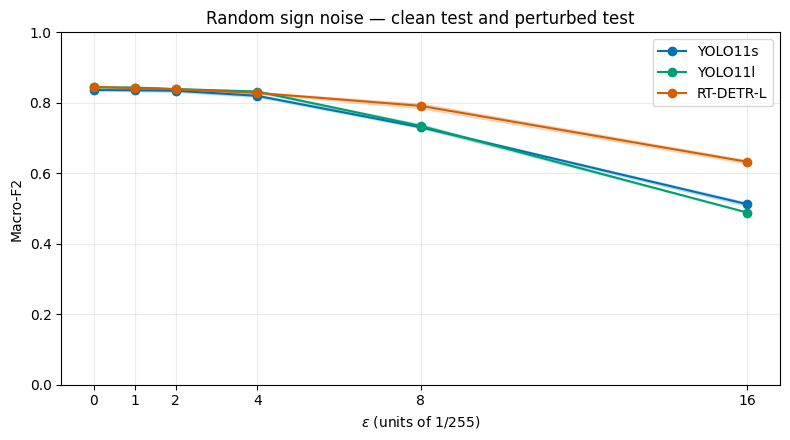

In [ ]:
seed_scores = (
    RANDOM_METRICS[
        RANDOM_METRICS["class"].isin(CLASS_NAMES)
    ]
    .groupby(["model", "epsilon_255", "seed"])["f2"]
    .mean()
    .reset_index(name="macro_f2")
)

RANDOM_CURVE = (
    seed_scores.groupby(["model", "epsilon_255"])["macro_f2"]
    .agg(macro_f2_mean="mean", macro_f2_std="std")
    .reset_index()
)

# Epsilon zero is the existing clean reference, evaluated once.
clean_curve = CLEAN_SUMMARY[["model", "macro_f2"]].rename(
    columns={"macro_f2": "macro_f2_mean"}
)
clean_curve = clean_curve.assign(
    epsilon_255=0,
    macro_f2_std=0.0,
)

RANDOM_CURVE = (
    pd.concat([clean_curve, RANDOM_CURVE], ignore_index=True)
    .sort_values(["model", "epsilon_255"])
    .reset_index(drop=True)
)

RANDOM_CURVE.to_csv(
    NOISE_DIR / "random_macro_f2_curve.csv", index=False
)

print(RANDOM_CURVE.to_string(
    index=False,
    float_format=lambda value: f"{value:.4f}",
))

fig, ax = plt.subplots(figsize=(8, 4.5))

for model_key in MODEL_KEYS:
    label, color = MODEL_LABELS[model_key], MODEL_COLORS[model_key]
    curve = RANDOM_CURVE[RANDOM_CURVE["model"] == model_key]
    x = curve["epsilon_255"].to_numpy()
    mean = curve["macro_f2_mean"].to_numpy()
    std = curve["macro_f2_std"].to_numpy()

    ax.plot(x, mean, marker="o", label=label, color=color)
    ax.fill_between(
        x,
        np.clip(mean - std, 0, 1),
        np.clip(mean + std, 0, 1),
        color=color,
        alpha=0.18,
    )

ax.set(
    title="Random sign noise — clean test and perturbed test",
    xlabel=r"$\epsilon$ (units of 1/255)",
    ylabel="Macro-F2",
    xticks=[0, *NOISE_EPSILONS],
    ylim=(0, 1),
)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

fig.savefig(NOISE_DIR / "random_macro_f2.png", dpi=300)
fig.savefig(NOISE_DIR / "random_macro_f2.pdf")
plt.show()

## 8. FGSM
Implement untargeted white-box FGSM in the original RGB pixel space, maximizing each detector's native loss in evaluation mode.

### 8.1. Attack Model Loading
Load the selected checkpoints with frozen weights and FP32 precision. Use each detector family's native loss to compute input gradients.

In [ ]:
from ultralytics.cfg import get_cfg
from ultralytics.utils.torch_utils import select_device

ATTACK_DEVICE = select_device(DEVICE, verbose=False)

FGSM_DIR = PATHS["experiments"] / "fgsm" / PROTOCOL_ID
FGSM_DIR.mkdir(parents=True, exist_ok=True)

save_or_check_json(FGSM_DIR / "attack_config.json", {
    "protocol_id": PROTOCOL_ID,
    "attack": "FGSM",
    "objective": "maximize_native_detection_loss",
    "model_mode": "eval",
    "precision": "float32",
    "gradient_batch": 1,
    "random_start": False,
    "epsilon_255": EPSILON_255,
    "ultralytics": ultralytics.__version__,
})
FGSM_DIR = resume_result_dir(FGSM_DIR)


def load_attack_model(model_key, checkpoint=None):
    """Load a frozen FP32 detector with its native loss."""
    model_class = MODEL_CLASSES[model_key]

    network = model_class(
        MODEL_PATHS[model_key] if checkpoint is None else str(checkpoint)
    ).model
    network = network.to(ATTACK_DEVICE).float().eval()
    network.fuse(verbose=False)
    network.model[-1].export = False

    if isinstance(network.args, dict):
        network.args = get_cfg(overrides=network.args)

    network.criterion = network.init_criterion()
    network.eval()
    network.requires_grad_(False)

    return network

### 8.2. Ground truth, loss and FGSM
Align annotations with each detector's preprocessing and compute the loss gradient with respect to the original image.

In [ ]:
def attack_targets(row, model_key):
    """Prepare normalized xywh targets in the detector input space."""
    label_path = DATASET_ROOT / row["label_path"]
    labels = (
        np.loadtxt(label_path, ndmin=2)
        if label_path.read_text().strip()
        else np.empty((0, 5))
    )

    # Clip ground-truth boxes to the original image boundaries.
    low = np.clip(labels[:, 1:3] - labels[:, 3:5] / 2, 0, 1)
    high = np.clip(labels[:, 1:3] + labels[:, 3:5] / 2, 0, 1)
    boxes = np.column_stack(((low + high) / 2, high - low))

    if MODEL_FAMILIES[model_key] == "yolo":
        size = int(EVALUATION_CONFIG["imgsz"])
        height, width = row["height"], row["width"]
        ratio = min(size / height, size / width)

        left = round((size - round(width * ratio)) / 2 - 0.1)
        top = round((size - round(height * ratio)) / 2 - 0.1)

        boxes *= (
            np.array([width, height, width, height])
            * ratio / size
        )
        boxes[:, :2] += np.array([left, top]) / size

    elif MODEL_FAMILIES[model_key] != "rtdetr":
        raise ValueError(f"Unknown model: {model_key}")

    return {
        "cls": torch.tensor(
            labels[:, :1], dtype=torch.float32, device=ATTACK_DEVICE
        ),
        "bboxes": torch.tensor(
            boxes, dtype=torch.float32, device=ATTACK_DEVICE
        ),
        "batch_idx": torch.zeros(
            len(labels), dtype=torch.long, device=ATTACK_DEVICE
        ),
    }


def native_attack_loss(network, x, targets, model_key):
    """Compute the native loss after differentiable preprocessing."""
    batch = {
        **targets,
        "img": differentiable_preprocess(x, model_key),
    }
    loss, _ = network.loss(batch)
    return loss.sum()


@torch.inference_mode(False)
@torch.enable_grad()
def fgsm_direction(network, x, targets, model_key):
    """Compute one gradient direction, reusable across epsilon values."""
    image = x.detach().clone().requires_grad_(True)
    loss = native_attack_loss(network, image, targets, model_key)

    assert torch.isfinite(loss), "Non-finite attack loss."

    gradient = torch.autograd.grad(loss, image)[0]

    assert torch.isfinite(gradient).all(), "Non-finite input gradient."
    gradient_max = float(gradient.abs().max())
    assert gradient_max > 0, "The input gradient is zero."

    return (
        gradient.detach().sign(),
        float(loss.detach()),
        gradient_max,
    )


def apply_fgsm(x, direction, epsilon_255):
    """Apply FGSM and keep the original RGB pixels within [0, 1]."""
    return (
        x + (epsilon_255 / 255.0) * direction
    ).clamp(0, 1).detach()

### 8.3. FGSM validation checks
Check finite nonzero gradients, epsilon-zero identity, perturbation bounds and loss changes on three validation images.

In [ ]:
FGSM_CHECKS_PASSED = False

def validate_fgsm_checks(frame, model_key=None):
    expected = pd.MultiIndex.from_product(
        [[model_key] if model_key else list(MODEL_PATHS), [row["image_path"] for row in VALID_ROWS[:3]]],
        names=["model", "image_path"],
    )
    actual = pd.MultiIndex.from_frame(frame[["model", "image_path"]])
    assert actual.is_unique and len(actual) == len(expected)
    assert expected.difference(actual).empty
    numeric = ["loss_clean", "gradient_max"] + [
        column for epsilon in EPSILON_255 for column in [f"loss_eps{epsilon}", f"delta_eps{epsilon}_255"]
    ]
    assert np.isfinite(frame[numeric].to_numpy()).all()
    assert frame["gradient_max"].gt(0).all()
    for epsilon in EPSILON_255:
        assert frame[f"delta_eps{epsilon}_255"].between(0, epsilon + 255.0e-6).all()
    assert frame["delta_eps0_255"].eq(0).all()

fgsm_checks = []
for model_key in MODEL_PATHS:
    saved = load_saved_csv(
        FGSM_DIR, ["validation_checks.csv"],
        lambda frame: validate_fgsm_checks(frame, model_key), {"model": model_key},
    )
    if saved is not None:
        fgsm_checks.extend(saved.to_dict("records"))
        continue
    network = load_attack_model(model_key)
    try:
        for image_index, row in enumerate(VALID_ROWS[:3], start=1):
            bgr = cv2.imread(str(DATASET_ROOT / row["image_path"]))
            assert bgr is not None, row["image_path"]
            assert bgr.shape[:2] == (row["height"], row["width"])

            x = rgb_tensor(bgr).to(ATTACK_DEVICE)
            targets = attack_targets(row, model_key)

            direction, clean_loss, gradient_max = fgsm_direction(
                network, x, targets, model_key
            )

            # Zero perturbation must reproduce the original pixels exactly.
            assert torch.equal(apply_fgsm(x, direction, 0), x)

            record = {
                "model": model_key,
                "image": image_index,
                "image_path": row["image_path"],
                "loss_clean": clean_loss,
                "gradient_max": gradient_max,
            }

            for epsilon_255 in EPSILON_255:
                adversarial = apply_fgsm(x, direction, epsilon_255)

                max_delta = float((adversarial - x).abs().max())
                assert max_delta <= epsilon_255 / 255.0 + 1e-6
                assert adversarial.min() >= 0 and adversarial.max() <= 1

                with torch.no_grad():
                    adversarial_loss = native_attack_loss(
                        network, adversarial, targets, model_key
                    )

                assert torch.isfinite(adversarial_loss)

                record[f"loss_eps{epsilon_255}"] = float(adversarial_loss)
                record[f"delta_eps{epsilon_255}_255"] = max_delta * 255

            fgsm_checks.append(record)

    finally:
        network.cpu()
        del network
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

FGSM_CHECKS = pd.DataFrame(fgsm_checks)
validate_fgsm_checks(FGSM_CHECKS)

FGSM_CHECKS.to_csv(
    FGSM_DIR / "validation_checks.csv", index=False
)
FGSM_CHECKS_PASSED = True

print(FGSM_CHECKS.drop(columns="image_path").to_string(
    index=False,
    float_format=lambda value: f"{value:.6g}",
))

[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/validation_checks.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/validation_checks.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/validation_checks.csv
   model  image  loss_clean  gradient_max  loss_eps0  delta_eps0_255  loss_eps1  delta_eps1_255  loss_eps2  delta_eps2_255  loss_eps4  delta_eps4_255  loss_eps8  delta_eps8_255  loss_eps16  delta_eps16_255
 yolo11s      1     1.78655      0.388709    1.78655               0    6.08493         1.00001    6.21073         2.00001    5.94352         4.00001    10.9621         8.00001     12.9703               16
 yolo11s      2      1.9266      0.413884     1.9266               0    5.54241         1.00001    5.86781         2.00001    5.78488         4.00001    5.95179         8.00001     12.3209               16
 yolo11s      3     1.74219      0.220681    1.74219      

### 8.4. Prediction of prepared adversarial inputs
Pass preprocessed float tensors to each detector while retaining native postprocessing and original-image box coordinates.

In [ ]:
from ultralytics.data.build import load_inference_source


class PreparedInputMixin:
    prepared_batch = None

    def preprocess(self, images):
        assert self.prepared_batch is not None
        assert self.prepared_batch.shape[0] == len(images)
        return self.prepared_batch.to(self.device)


class PreparedYOLOPredictor(PreparedInputMixin, FloatYOLOPredictor):
    pass


class PreparedRTDETRPredictor(PreparedInputMixin, FloatRTDETRPredictor):
    pass


FGSM_PREDICT_ARGS = {
    "device": DEVICE,
    "imgsz": EVALUATION_CONFIG["imgsz"],
    "rect": False,
    "conf": EVALUATION_CONFIG["confidence_floor"],
    "iou": EVALUATION_CONFIG["nms_iou"],
    "max_det": EVALUATION_CONFIG["max_det"],
    "batch": EVALUATION_CONFIG["batch"],
    "classes": None,
    "agnostic_nms": False,
    "augment": False,
    "save": False,
    "save_txt": False,
    "verbose": False,
    **EVALUATION_CONFIG["precision"],
}

### 8.5. Complete FGSM test evaluation
Evaluate every configured epsilon on the full test set. Reuse each image's gradient across epsilon values and verify the clean reference at epsilon zero.

In [ ]:
FGSM_TEST_COMPLETE = False
assert FGSM_CHECKS_PASSED, "Complete the FGSM validation checks first."
assert 0 in EPSILON_255, "Include epsilon zero for the baseline check."

fgsm_rows, fgsm_summary_rows = [], []
batch_size = EVALUATION_CONFIG["batch"]

for model_key in MODEL_KEYS:
    model_class = MODEL_CLASSES[model_key]
    predictor_class = predictor_for_model(
        model_key, PreparedYOLOPredictor, PreparedRTDETRPredictor
    )
    threshold = CONFIDENCE_THRESHOLDS[model_key]
    totals = {}
    missing_epsilons = []
    for epsilon in EPSILON_255:
        saved = load_saved_csv(
            FGSM_DIR, [f"{model_key}_eps{epsilon}_test_metrics.csv", f"{model_key}_test_metrics.csv", "fgsm_metrics.csv"],
            lambda frame: saved_counts(frame, model_key),
            {"model": model_key, "epsilon_255": epsilon},
        )
        if saved is None:
            missing_epsilons.append(epsilon)
            totals[epsilon] = np.zeros((len(CLASS_NAMES), 3), dtype=int)
        else:
            totals[epsilon] = saved_counts(saved, model_key)

    if missing_epsilons:
        attack_network = load_attack_model(model_key)
        evaluation_model = model_class(MODEL_PATHS[model_key])
        try:
            for start in tqdm(
                range(0, len(TEST_ROWS), batch_size),
                desc=f"{model_key} — FGSM, missing epsilon values",
            ):
                rows = TEST_ROWS[start:start + batch_size]
                paths = [
                    str(DATASET_ROOT / row["image_path"])
                    for row in rows
                ]

                source_loader = load_inference_source(
                    source=paths, batch=batch_size
                )
                loaded_paths, images, _ = next(iter(source_loader))

                assert len(images) == len(rows)
                assert [Path(p).resolve() for p in loaded_paths] == [
                    Path(p).resolve() for p in paths
                ]

                prepared = {epsilon: [] for epsilon in missing_epsilons}

                # One gradient per original image.
                for row, bgr in zip(rows, images):
                    assert bgr.shape[:2] == (row["height"], row["width"])

                    x = rgb_tensor(bgr).to(ATTACK_DEVICE)
                    targets = attack_targets(row, model_key)
                    direction, _, _ = fgsm_direction(
                        attack_network, x, targets, model_key
                    )

                    for epsilon in missing_epsilons:
                        adversarial = apply_fgsm(x, direction, epsilon)

                        assert (
                            float((adversarial - x).abs().max())
                            <= epsilon / 255.0 + 1e-6
                        )

                        prepared[epsilon].append(
                            differentiable_preprocess(
                                adversarial, model_key
                            ).detach()
                        )

                # Evaluate the same batch at every epsilon.
                for epsilon in missing_epsilons:
                    predictor_class.prepared_batch = torch.cat(
                        prepared[epsilon]
                    )

                    results = evaluation_model.predict(
                        source=source_loader,
                        predictor=predictor_class,
                        **FGSM_PREDICT_ARGS,
                    )
                    assert len(results) == len(rows)

                    for row, result in zip(rows, results):
                        assert Path(result.path).resolve() == (
                            DATASET_ROOT / row["image_path"]
                        ).resolve()

                        pred = (
                            result.boxes.data.cpu().numpy()
                            .astype(np.float64)
                        )
                        pred = pred[pred[:, 4] >= threshold]
                        pred, correct, support = match_predictions(pred, row)

                        for class_id in range(len(CLASS_NAMES)):
                            mask = pred[:, 5] == class_id
                            tp = int(correct[mask].sum())

                            totals[epsilon][class_id] += [
                                tp,
                                int(mask.sum()) - tp,
                                int(support[class_id]) - tp,
                            ]

                predictor_class.prepared_batch = None
                del prepared

        finally:
            predictor_class.prepared_batch = None
            attack_network.cpu()
            evaluation_model.to("cpu")
            evaluation_model.predictor = None
            del attack_network, evaluation_model

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    # Epsilon zero must reproduce the previous clean TP, FP and FN.
    reference = (
        CLEAN_METRICS[CLEAN_METRICS["model"] == model_key]
        .set_index("class")
        .loc[CLASS_NAMES, ["tp", "fp", "fn"]]
        .to_numpy(dtype=int)
    )
    assert np.array_equal(totals[0], reference), (
        f"{model_key}: epsilon-zero mismatch. "
        f"Expected {reference.tolist()}, obtained {totals[0].tolist()}."
    )
    print(f"{model_key}: epsilon zero matches the clean baseline.")

    model_rows = []

    for epsilon in EPSILON_255:
        class_metrics = [
            metrics_from_counts(counts)
            for counts in totals[epsilon]
        ]
        micro_metrics = metrics_from_counts(
            totals[epsilon].sum(axis=0)
        )

        for name, metrics in zip(
            [*CLASS_NAMES, "micro"],
            [*class_metrics, micro_metrics],
        ):
            model_rows.append({
                "model": model_key,
                "epsilon_255": epsilon,
                "confidence": threshold,
                "class": name,
                **metrics,
            })

        fgsm_summary_rows.append({
            "model": model_key,
            "epsilon_255": epsilon,
            "macro_f2": np.mean([m["f2"] for m in class_metrics]),
            "micro_f2": micro_metrics["f2"],
            "micro_recall": micro_metrics["recall"],
            "fp": micro_metrics["fp"],
            "fn": micro_metrics["fn"],
        })

    pd.DataFrame(model_rows).to_csv(
        FGSM_DIR / f"{model_key}_test_metrics.csv",
        index=False,
    )
    fgsm_rows.extend(model_rows)


FGSM_METRICS = pd.DataFrame(fgsm_rows)
FGSM_SUMMARY = pd.DataFrame(fgsm_summary_rows)

FGSM_METRICS.to_csv(FGSM_DIR / "fgsm_metrics.csv", index=False)
FGSM_SUMMARY.to_csv(FGSM_DIR / "fgsm_summary.csv", index=False)

FGSM_TEST_COMPLETE = True

print("\nFGSM — COMPLETE TEST")
print(FGSM_SUMMARY.to_string(
    index=False,
    float_format=lambda value: f"{value:.4f}",
))

[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/fgsm_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/fgsm_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/fgsm_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/fgsm_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/fgsm_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/fgsm_metrics.csv
yolo11s: epsilon zero matches the clean baseline.
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/fgsm_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/fgsm_metrics.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/fgsm/edf11658078a6e4f/fgsm_metrics.csv
[LOAD] /content/drive/M

### 8.7. Direct model comparison under FGSM
Compare YOLO11s and RT-DETR-L using test macro-F2 across the configured epsilon values.

model        YOLO11s  YOLO11l  RT-DETR-L
epsilon_255                             
0             0.8361   0.8438     0.8451
1             0.6102   0.5950     0.6370
2             0.5663   0.5654     0.6324
4             0.5177   0.5323     0.6299
8             0.3548   0.4017     0.5171
16            0.1909   0.1790     0.2641


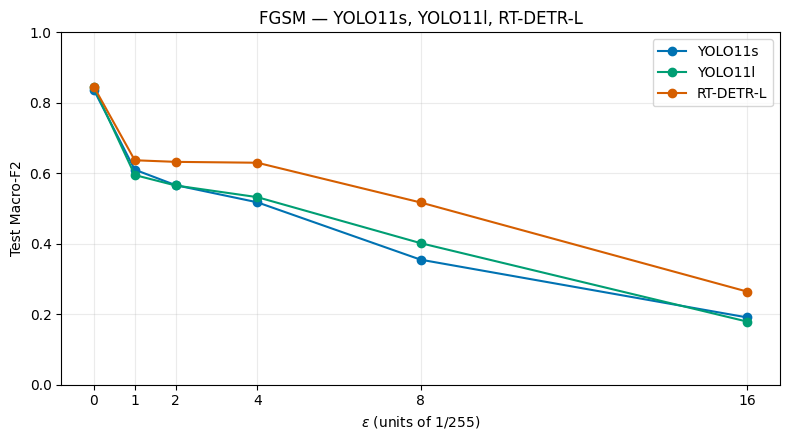

In [ ]:
assert FGSM_TEST_COMPLETE, "Complete the FGSM test evaluation first."

FGSM_COMPARISON = (
    FGSM_SUMMARY.pivot(
        index="epsilon_255",
        columns="model",
        values="macro_f2",
    )
    .reindex(index=EPSILON_255, columns=list(MODEL_PATHS))
    .rename(columns=MODEL_LABELS)
)

print(FGSM_COMPARISON.to_string(
    float_format=lambda value: f"{value:.4f}"
))
FGSM_COMPARISON.to_csv(
    FGSM_DIR / "fgsm_models_comparison.csv"
)

fig, ax = plt.subplots(figsize=(8, 4.5))

FGSM_COMPARISON.plot(
    ax=ax,
    marker="o",
    color=[MODEL_COLORS[key] for key in MODEL_KEYS],
)

ax.set(
    title="FGSM — " + ", ".join(MODEL_LABELS[key] for key in MODEL_KEYS),
    xlabel=r"$\epsilon$ (units of 1/255)",
    ylabel="Test Macro-F2",
    xticks=EPSILON_255,
    ylim=(0, 1),
)
ax.grid(alpha=0.25)
ax.legend(title=None)
fig.tight_layout()

fig.savefig(FGSM_DIR / "fgsm_models_comparison.png", dpi=300)
fig.savefig(FGSM_DIR / "fgsm_models_comparison.pdf")
plt.show()

## 9. Projected Gradient Descent (PGD)
Evaluate model robustness to iterative adversarial perturbations using the configured epsilon values, random seeds, and attack steps.

### 9.1. PGD configuration
Load the configured epsilon values, step counts, seeds, and step-size ratio for the PGD evaluation.

In [ ]:
PGD_CHECKS_PASSED = False
PGD_TEST_COMPLETE = False
PGD_ALPHA_RATIO = float(PROJECT_CONFIG["attacks"]["pgd_alpha_ratio"])

assert PGD_ALPHA_RATIO > 0
assert PGD_STEPS and all(int(s) == s and s > 0 for s in PGD_STEPS)
assert 0 in EPSILON_255 and all(e >= 0 for e in EPSILON_255)
assert ATTACK_SEEDS and len(set(ATTACK_SEEDS)) == len(ATTACK_SEEDS)
assert len(set(PGD_STEPS)) == len(PGD_STEPS)
assert len(set(EPSILON_255)) == len(EPSILON_255)
assert PGD_ALPHA_RATIO == float(EXPERIMENT_PROTOCOL["attacks"]["pgd_alpha_ratio"])
assert list(PGD_STEPS) == EXPERIMENT_PROTOCOL["attacks"]["pgd_steps"]
assert list(EPSILON_255) == EXPERIMENT_PROTOCOL["attacks"]["epsilon_255"]
assert list(ATTACK_SEEDS) == EXPERIMENT_PROTOCOL["attacks"]["seeds"]
assert content_id(EXPERIMENT_PROTOCOL) == PROTOCOL_ID
assert EXPERIMENT_PROTOCOL["evaluation"] == EVALUATION_CONFIG
assert EVALUATION_CONFIG["confidence_thresholds"] == CONFIDENCE_THRESHOLDS

PGD_ROOT = PATHS["experiments"] / "pgd"
PGD_PROTOCOL_ROOT = PATHS["configs"] / "protocols"
PGD_CURRENT_PROTOCOL = json.loads(json.dumps(EXPERIMENT_PROTOCOL))
assert json.loads(
    (PGD_PROTOCOL_ROOT / f"{PROTOCOL_ID}.json").read_text()
) == PGD_CURRENT_PROTOCOL

# Preserve the existing attack definition and software requirements.
PGD_ATTACK_CONFIG = {
    "attack": "PGD",
    "objective": "maximize_native_detection_loss",
    "model_mode": "eval",
    "precision": "float32",
    "gradient_batch": 1,
    "epsilon_255": EPSILON_255,
    "steps": PGD_STEPS,
    "seeds": ATTACK_SEEDS,
    "alpha_ratio": PGD_ALPHA_RATIO,
    "alpha_rule": "epsilon * alpha_ratio",
    "random_start": "uniform_in_epsilon_ball_then_clip",
    "random_generator": "torch_cpu",
    "random_layout": "NCHW",
    "seed_rule": "sha256_seed_relative_path_v1",
    "same_start_across_models_and_step_counts": True,
    "output": "last_iterate",
    "torch": str(torch.__version__),
    "ultralytics": ultralytics.__version__,
}


def pgd_protocol_settings(protocol):
    settings = dict(protocol)
    # The registry ID may change; thresholds and all other settings must match.
    settings.pop("threshold_calibration_id", None)
    return settings


PGD_COMPATIBILITY_ID = content_id({
    "experiment": pgd_protocol_settings(PGD_CURRENT_PROTOCOL),
    "attack": PGD_ATTACK_CONFIG,
})


def pgd_compatible_directories():
    compatible = []
    for directory in sorted(PGD_ROOT.glob("*")):
        if not directory.is_dir():
            continue
        protocol_path = PGD_PROTOCOL_ROOT / f"{directory.name}.json"
        attack_path = directory / "attack_config.json"
        if not protocol_path.is_file() or not attack_path.is_file():
            if any(directory.glob("*_test_metrics.csv")):
                print(f"Skipped directory with missing metadata: {directory.name}")
            continue
        saved_protocol = json.loads(protocol_path.read_text())
        saved_attack = json.loads(attack_path.read_text())
        assert saved_attack.get("protocol_id") == directory.name, (
            f"Directory/configuration ID mismatch: {directory}"
        )
        saved_attack.pop("protocol_id", None)
        if (
            pgd_protocol_settings(saved_protocol)
            == pgd_protocol_settings(PGD_CURRENT_PROTOCOL)
            and saved_attack == PGD_ATTACK_CONFIG
            and result_environment_matches(saved_protocol)
        ):
            compatible.append(directory)
    return compatible


PGD_COMPATIBLE_DIRS = pgd_compatible_directories()
origin_candidates = []
empty_candidates = []

for directory in PGD_COMPATIBLE_DIRS:
    files = list(directory.glob("*_test_metrics.csv"))
    identity_path = directory / "run_identity.json"
    if identity_path.is_file():
        identity = json.loads(identity_path.read_text())
        assert identity["compatibility_id"] == PGD_COMPATIBILITY_ID
        assert identity["run_id"] == directory.name
        origin_time = int(identity["origin_saved_at_ns"])
    elif files:
        origin_time = min(path.stat().st_mtime_ns for path in files)
    else:
        origin_time = (directory / "attack_config.json").stat().st_mtime_ns
    entry = (origin_time, directory.name, directory)
    (origin_candidates if files else empty_candidates).append(entry)

# Continue in the original directory, without a hard-coded run ID.
if origin_candidates or empty_candidates:
    origin_time, _, PGD_DIR = min(origin_candidates or empty_candidates)
else:
    PGD_DIR = PGD_ROOT / PROTOCOL_ID
    origin_time = time.time_ns()
    assert not any(PGD_DIR.glob("*_test_metrics.csv")), (
        "Results exist in the target directory without compatible metadata. "
        "Restore their configuration before resuming."
    )

PGD_RUN_ID = PGD_DIR.name
PGD_DIR.mkdir(parents=True, exist_ok=True)
save_or_check_json(PGD_DIR / "attack_config.json", {
    "protocol_id": PGD_RUN_ID,
    **PGD_ATTACK_CONFIG,
})
save_or_check_json(PGD_DIR / "run_identity.json", {
    "schema_version": 1,
    "run_id": PGD_RUN_ID,
    "compatibility_id": PGD_COMPATIBILITY_ID,
    "origin_saved_at_ns": origin_time,
})
PGD_COMPATIBLE_DIRS = pgd_compatible_directories()


def pgd_archive_csv(path):
    """Keep an earlier CSV before replacing it with different content."""
    if path.is_file():
        history = PGD_DIR / "history"
        history.mkdir(exist_ok=True)
        backup = history / f"{path.stem}.{file_sha256(path)}.csv"
        if not backup.exists():
            shutil.copy2(path, backup)


def pgd_write_csv(frame, path):
    temporary = path.with_name(path.name + ".tmp")
    frame.to_csv(temporary, index=False)
    if path.is_file() and path.name.endswith("_test_metrics.csv"):
        if file_sha256(path) != file_sha256(temporary):
            pgd_archive_csv(path)
    temporary.replace(path)


def pgd_import_csv(source, destination):
    """Consolidate a saved CSV while retaining its original save time."""
    if source == destination:
        return
    if destination.is_file():
        if file_sha256(source) == file_sha256(destination):
            return
        pgd_archive_csv(destination)
    temporary = destination.with_name(destination.name + ".tmp")
    shutil.copy2(source, temporary)
    temporary.replace(destination)


print("PGD run ID:", PGD_RUN_ID)
print("Current experiment protocol:", PROTOCOL_ID)
print("Results directory:", PGD_DIR)
print("Compatible directories:", [path.name for path in PGD_COMPATIBLE_DIRS])
print("PGD steps:", PGD_STEPS)
print("Seeds:", ATTACK_SEEDS)
print(pd.DataFrame({
    "epsilon_255": EPSILON_255,
    "alpha_255": [epsilon * PGD_ALPHA_RATIO for epsilon in EPSILON_255],
}).to_string(index=False))

PGD run ID: edf11658078a6e4f
Current experiment protocol: edf11658078a6e4f
Results directory: /content/drive/MyDrive/fire_smoke_robustness/experiments/pgd/edf11658078a6e4f
Compatible directories: ['edf11658078a6e4f']
PGD steps: [5, 10, 20]
Seeds: [42, 43, 44]
 epsilon_255  alpha_255
           0       0.00
           1       0.25
           2       0.50
           4       1.00
           8       2.00
          16       4.00


### 9.2. PGD attack implementation
Generate PGD examples with a random start, recompute the gradient at every step, and save the configured iteration checkpoints.

In [ ]:
@torch.inference_mode(False)
@torch.enable_grad()
def pgd_checkpoints(
    network, x, targets, model_key, relative_path, epsilon_255, seed
):
    clean = x.detach().clone()
    epsilon = float(epsilon_255) / 255.0
    alpha = epsilon * PGD_ALPHA_RATIO

    if epsilon == 0:
        return {step: clean.clone() for step in PGD_STEPS}

    generator = torch.Generator(device="cpu")
    generator.manual_seed(image_seed(relative_path, seed))

    noise = torch.empty(
        clean.shape, dtype=clean.dtype, device="cpu"
    ).uniform_(-1.0, 1.0, generator=generator)

    adversarial = (
        clean + epsilon * noise.to(clean.device)
    ).clamp(0, 1).detach()

    checkpoints = {}

    for step in range(1, int(max(PGD_STEPS)) + 1):
        adversarial.requires_grad_(True)

        loss = native_attack_loss(
            network, adversarial, targets, model_key
        )
        assert torch.isfinite(loss), "Non-finite PGD loss."

        gradient = torch.autograd.grad(loss, adversarial)[0]
        assert torch.isfinite(gradient).all(), "Non-finite PGD gradient."

        with torch.no_grad():
            candidate = adversarial + alpha * gradient.sign()

            # Project onto the original image's Linf epsilon ball.
            delta = (candidate - clean).clamp(-epsilon, epsilon)

            # Keep valid floating-point RGB values.
            adversarial = (clean + delta).clamp(0, 1).detach()

        if step in PGD_STEPS:
            checkpoints[step] = adversarial.clone()

    return checkpoints

### 9.3. PGD validation checks
Check the PGD perturbations on three validation images across all configured epsilon values, seeds, and step counts.

In [ ]:
PGD_CHECKS_PASSED = False
assert len(VALID_ROWS) >= 3

check_keys = ["model", "image_path", "seed", "epsilon_255", "steps"]
expected_check_index = pd.MultiIndex.from_product(
    [list(MODEL_PATHS), [r["image_path"] for r in VALID_ROWS[:3]],
     ATTACK_SEEDS, EPSILON_255, PGD_STEPS],
    names=check_keys,
)


def pgd_validate_checks(frame, model_key=None):
    expected = expected_check_index if model_key is None else expected_check_index[expected_check_index.get_level_values("model") == model_key]
    actual = pd.MultiIndex.from_frame(frame[check_keys])
    assert actual.is_unique and len(actual) == len(expected)
    assert expected.difference(actual).empty
    columns = ["loss_clean", "gradient_clean_max", "loss_pgd", "max_delta_255"]
    assert np.isfinite(frame[columns].to_numpy()).all()
    assert (frame["gradient_clean_max"] > 0).all()
    assert (frame["max_delta_255"] >= 0).all()
    assert (
        frame["max_delta_255"] <= frame["epsilon_255"] + 255.0e-6
    ).all()
    assert (frame.loc[frame["epsilon_255"] == 0, "max_delta_255"] == 0).all()


pgd_check_rows = []
for model_key in MODEL_PATHS:
    saved = load_saved_csv(
        PGD_DIR, ["validation_checks.csv"],
        lambda frame: pgd_validate_checks(frame, model_key), {"model": model_key},
    )
    if saved is not None:
        pgd_check_rows.extend(saved.to_dict("records"))
        continue
    assert FGSM_CHECKS_PASSED, "Complete the FGSM technical checks first."
    network = load_attack_model(model_key)
    try:
        for image_index, row in enumerate(
            tqdm(VALID_ROWS[:3], desc=f"{model_key} — PGD checks"),
            start=1,
        ):
            source_loader = load_inference_source(
                source=[str(DATASET_ROOT / row["image_path"])],
                batch=1,
            )
            _, images, _ = next(iter(source_loader))
            bgr = images[0]

            assert bgr.shape[:2] == (row["height"], row["width"])

            x = rgb_tensor(bgr).to(ATTACK_DEVICE)
            targets = attack_targets(row, model_key)

            # Reuse the existing clean-gradient diagnostic.
            _, loss_clean, gradient_clean_max = fgsm_direction(
                network, x, targets, model_key
            )

            for seed in ATTACK_SEEDS:
                for epsilon_255 in EPSILON_255:
                    checkpoints = pgd_checkpoints(
                        network=network,
                        x=x,
                        targets=targets,
                        model_key=model_key,
                        relative_path=row["image_path"],
                        epsilon_255=epsilon_255,
                        seed=seed,
                    )

                    for steps in PGD_STEPS:
                        adversarial = checkpoints[steps]

                        assert torch.isfinite(adversarial).all()
                        assert bool(
                            (adversarial >= 0).all()
                            and (adversarial <= 1).all()
                        )

                        max_delta = float(
                            (adversarial - x).abs().max()
                        )
                        assert max_delta <= epsilon_255 / 255.0 + 1e-6

                        if epsilon_255 == 0:
                            assert torch.equal(adversarial, x)

                        with torch.no_grad():
                            loss_pgd = native_attack_loss(
                                network, adversarial, targets, model_key
                            )

                        assert torch.isfinite(loss_pgd)

                        pgd_check_rows.append({
                            "model": model_key,
                            "image": image_index,
                            "image_path": row["image_path"],
                            "seed": seed,
                            "epsilon_255": epsilon_255,
                            "steps": steps,
                            "loss_clean": loss_clean,
                            "gradient_clean_max": gradient_clean_max,
                            "loss_pgd": float(loss_pgd),
                            "max_delta_255": max_delta * 255.0,
                        })

                    del checkpoints

    finally:
        network.cpu()
        del network
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

PGD_CHECKS = pd.DataFrame(pgd_check_rows)
pgd_validate_checks(PGD_CHECKS)
pgd_write_csv(PGD_CHECKS, PGD_DIR / "validation_checks.csv")


PGD_CHECKS_COMPATIBILITY_ID = PGD_COMPATIBILITY_ID
PGD_CHECKS_PASSED = True
print(PGD_CHECKS.groupby(
    ["model", "epsilon_255", "steps"], sort=False
).agg(
    images_checked=("image_path", "nunique"),
    runs_checked=("seed", "size"),
    loss_clean_mean=("loss_clean", "mean"),
    loss_pgd_mean=("loss_pgd", "mean"),
    max_delta_255=("max_delta_255", "max"),
).to_string(float_format=lambda value: f"{value:.5f}"))

print("\nPGD technical checks are valid. Section 9.4 resumes test evaluation.")

[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/pgd/edf11658078a6e4f/validation_checks.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/pgd/edf11658078a6e4f/validation_checks.csv
[LOAD] /content/drive/MyDrive/fire_smoke_robustness/experiments/pgd/edf11658078a6e4f/validation_checks.csv
                            images_checked  runs_checked  loss_clean_mean  loss_pgd_mean  max_delta_255
model    epsilon_255 steps                                                                             
yolo11s  0           5                   3             9          1.81845        1.81845        0.00000
                     10                  3             9          1.81845        1.81845        0.00000
                     20                  3             9          1.81845        1.81845        0.00000
         1           5                   3             9          1.81845       11.14452        1.00001
                     10                  3             

### 9.4. Complete PGD test evaluation
Restore the most recently saved compatible result for each model, epsilon, and seed. Evaluate only missing configurations across all configured step counts, verify the clean reference at epsilon zero, and save the complete metrics and summary.

In [ ]:
PGD_TEST_COMPLETE = False
assert PGD_CHECKS_PASSED, "Run section 9.3 first."
assert PGD_CHECKS_COMPATIBILITY_ID == PGD_COMPATIBILITY_ID
assert PGD_DIR == PGD_ROOT / PGD_RUN_ID
assert 0 in EPSILON_255

PGD_COMPATIBLE_DIRS = pgd_compatible_directories()
assert PGD_DIR in PGD_COMPATIBLE_DIRS, "Run section 9.1 again."
run_keys = [
    (model_key, epsilon, seed)
    for model_key in MODEL_PATHS
    for epsilon in EPSILON_255
    for seed in ATTACK_SEEDS
]
expected_run_index = pd.MultiIndex.from_product(
    [PGD_STEPS, [*CLASS_NAMES, "micro"]], names=["steps", "class"]
)


def pgd_run_name(model_key, epsilon, seed):
    return f"{model_key}_eps{epsilon}_seed{seed}_test_metrics.csv"


# Load the saved clean reference without rerunning inference.
baseline_ids = list(dict.fromkeys(
    [PROTOCOL_ID, PGD_RUN_ID] + [d.name for d in PGD_COMPATIBLE_DIRS]
))
baseline_paths = [
    PATHS["experiments"] / "clean_baseline" / identifier / "clean_metrics.csv"
    for identifier in baseline_ids
]
baseline_path = next((p for p in baseline_paths if p.is_file()), None)
assert baseline_path is not None, "Load or complete the clean test baseline first."
pgd_clean_reference = pd.read_csv(baseline_path)
pgd_clean_counts = {}

for model_key in MODEL_PATHS:
    clean = pgd_clean_reference[
        (pgd_clean_reference["model"] == model_key)
        & pgd_clean_reference["class"].isin(CLASS_NAMES)
    ].set_index("class")
    assert clean.index.is_unique and set(clean.index) == set(CLASS_NAMES)
    assert np.allclose(
        clean["confidence"], CONFIDENCE_THRESHOLDS[model_key], rtol=0, atol=1e-12
    )
    counts = clean.loc[CLASS_NAMES, ["tp", "fp", "fn"]].to_numpy()
    assert np.isfinite(counts).all() and (counts >= 0).all()
    assert np.equal(counts, np.floor(counts)).all()
    pgd_clean_counts[model_key] = counts.astype(np.int64)


def pgd_validate_run(frame, model_key, epsilon, seed):
    for column, value in [
        ("model", model_key), ("epsilon_255", epsilon), ("seed", seed)
    ]:
        assert frame[column].eq(value).all(), f"Invalid {column}"
    assert np.allclose(
        frame["confidence"], CONFIDENCE_THRESHOLDS[model_key], rtol=0, atol=1e-12
    ), "Confidence mismatch"
    actual = pd.MultiIndex.from_frame(frame[["steps", "class"]])
    assert actual.is_unique and len(actual) == len(expected_run_index), (
        "Incomplete or duplicate rows"
    )
    assert expected_run_index.difference(actual).empty, "Missing step/class rows"
    metric_columns = ["tp", "fp", "fn", "precision", "recall", "f1", "f2"]
    assert np.isfinite(frame[metric_columns].to_numpy()).all(), "Non-finite metrics"
    counts = frame[["tp", "fp", "fn"]].to_numpy()
    assert (counts >= 0).all() and np.equal(counts, np.floor(counts)).all()
    for _, row in frame.iterrows():
        expected = metrics_from_counts(row[["tp", "fp", "fn"]].to_numpy())
        assert np.allclose(
            row[metric_columns].to_numpy(dtype=float),
            [expected[column] for column in metric_columns],
            rtol=0, atol=1e-12,
        ), "Metrics/counts mismatch"
    for steps in PGD_STEPS:
        step_frame = frame[frame["steps"] == steps].set_index("class")
        class_counts = step_frame.loc[CLASS_NAMES, ["tp", "fp", "fn"]].to_numpy()
        micro_counts = step_frame.loc["micro", ["tp", "fp", "fn"]].to_numpy()
        assert np.array_equal(class_counts.sum(axis=0), micro_counts)
        reference = pgd_clean_counts[model_key]
        assert np.array_equal(
            class_counts[:, 0] + class_counts[:, 2],
            reference[:, 0] + reference[:, 2],
        ), "Ground-truth support mismatch"
        if epsilon == 0:
            assert np.array_equal(class_counts, reference), "Epsilon-zero mismatch"


# Select and validate all saved results before loading any model.
PGD_RESUME_FILES = {}
pgd_restored_frames = {}
for model_key, epsilon, seed in run_keys:
    name = pgd_run_name(model_key, epsilon, seed)
    candidates = compatible_csv_paths(PGD_DIR, [name], model_key=model_key)
    for path in candidates:
        try:
            frame = pd.read_csv(path)
            pgd_validate_run(frame, model_key, epsilon, seed)
        except (AssertionError, KeyError, ValueError, pd.errors.ParserError) as error:
            print(f"Skipped invalid result: {path} ({error})")
            continue
        PGD_RESUME_FILES[name] = path
        pgd_restored_frames[name] = frame
        break

print("Results directory:", PGD_DIR)
print("Expected configurations:", len(run_keys))
print("Validated configurations to restore:", len(pgd_restored_frames))
print("Configurations to evaluate:", len(run_keys) - len(pgd_restored_frames))

pgd_metric_rows = []
pgd_source_records = {}


def pgd_record_source(name, source, status):
    record = {
        "file": name,
        "source_path": str(source),
        "source_protocol_id": (source.parent.parent.name if source.parent.name == "pgd" else source.parent.name),
        "destination_path": str(PGD_DIR / name),
        "sha256": file_sha256(PGD_DIR / name),
        "status": status,
        "execution_protocol_id": PROTOCOL_ID,
        "recorded_at": datetime.now(timezone.utc).isoformat(),
    }
    pgd_source_records[name] = record
    pgd_write_csv(
        pd.DataFrame(pgd_source_records.values()), PGD_DIR / "resume_sources.csv"
    )
    with (PGD_DIR / "run_events.jsonl").open("a", encoding="utf-8") as stream:
        stream.write(json.dumps(record, sort_keys=True) + "\n")


for model_key, epsilon, seed in run_keys:
    name = pgd_run_name(model_key, epsilon, seed)
    if name not in pgd_restored_frames:
        continue
    source = PGD_RESUME_FILES[name]
    pgd_import_csv(source, PGD_DIR / name)
    pgd_metric_rows.extend(pgd_restored_frames[name].to_dict("records"))
    pgd_record_source(name, source, "restored")
    print(f"Loaded completed run: {name} [source protocol: {source.parent.name}]")


PGD_PREDICT_ARGS = FGSM_PREDICT_ARGS.copy()
batch_size = int(EVALUATION_CONFIG["batch"])
assert batch_size > 0 and TEST_ROWS

for model_key in MODEL_PATHS:
    pending = [
        (epsilon, seed) for model, epsilon, seed in run_keys
        if model == model_key
        and pgd_run_name(model, epsilon, seed) not in pgd_restored_frames
    ]
    if not pending:
        print(f"{model_key}: all configured runs restored; no model loaded.")
        continue

    model_class = MODEL_CLASSES[model_key]
    predictor_class = predictor_for_model(
        model_key, PreparedYOLOPredictor, PreparedRTDETRPredictor
    )
    threshold = CONFIDENCE_THRESHOLDS[model_key]
    clean_counts = pgd_clean_counts[model_key]
    attack_network = None
    evaluation_model = None

    try:
        attack_network = load_attack_model(model_key)
        evaluation_model = model_class(MODEL_PATHS[model_key])

        for epsilon_255, seed in pending:
            run_path = PGD_DIR / pgd_run_name(model_key, epsilon_255, seed)
            totals = {
                steps: np.zeros(
                    (len(CLASS_NAMES), 3), dtype=int
                )
                for steps in PGD_STEPS
            }

            description = (
                f"{model_key} — PGD | "
                f"eps={epsilon_255}/255 | seed={seed}"
            )

            for start in tqdm(
                range(0, len(TEST_ROWS), batch_size),
                desc=description,
            ):
                rows = TEST_ROWS[start:start + batch_size]
                paths = [
                    str(DATASET_ROOT / row["image_path"])
                    for row in rows
                ]

                source_loader = load_inference_source(
                    source=paths,
                    batch=batch_size,
                )
                loaded_paths, images, _ = next(
                    iter(source_loader)
                )

                assert len(images) == len(rows)
                assert [
                    Path(path).resolve() for path in loaded_paths
                ] == [
                    Path(path).resolve() for path in paths
                ]

                prepared = {
                    steps: [] for steps in PGD_STEPS
                }

                for row, bgr in zip(rows, images):
                    assert bgr.shape[:2] == (
                        row["height"], row["width"]
                    )

                    x = rgb_tensor(bgr).to(ATTACK_DEVICE)
                    targets = attack_targets(row, model_key)

                    checkpoints = pgd_checkpoints(
                        network=attack_network,
                        x=x,
                        targets=targets,
                        model_key=model_key,
                        relative_path=row["image_path"],
                        epsilon_255=epsilon_255,
                        seed=seed,
                    )

                    for steps in PGD_STEPS:
                        adversarial = checkpoints[steps]

                        max_delta = float(
                            (adversarial - x).abs().max()
                        )
                        assert (
                            max_delta
                            <= epsilon_255 / 255.0 + 1e-6
                        )

                        if epsilon_255 == 0:
                            assert torch.equal(adversarial, x)

                        prepared[steps].append(
                            differentiable_preprocess(
                                adversarial, model_key
                            ).detach()
                        )

                # Evaluate all configured iteration checkpoints.
                for steps in PGD_STEPS:
                    predictor_class.prepared_batch = torch.cat(
                        prepared[steps]
                    )

                    results = evaluation_model.predict(
                        source=source_loader,
                        predictor=predictor_class,
                        **PGD_PREDICT_ARGS,
                    )
                    assert len(results) == len(rows)

                    for row, result in zip(rows, results):
                        assert Path(result.path).resolve() == (
                            DATASET_ROOT / row["image_path"]
                        ).resolve()

                        pred = (
                            result.boxes.data.cpu()
                            .numpy()
                            .astype(np.float64)
                        )
                        pred = pred[pred[:, 4] >= threshold]

                        pred, correct, support = match_predictions(
                            pred, row
                        )

                        for class_id in range(len(CLASS_NAMES)):
                            mask = pred[:, 5] == class_id
                            tp = int(correct[mask].sum())

                            totals[steps][class_id] += [
                                tp,
                                int(mask.sum()) - tp,
                                int(support[class_id]) - tp,
                            ]

                predictor_class.prepared_batch = None
                del prepared, checkpoints

            run_rows = []

            for steps in PGD_STEPS:
                if epsilon_255 == 0:
                    assert np.array_equal(
                        totals[steps], clean_counts
                    ), (
                        f"{model_key}: epsilon-zero mismatch "
                        f"at PGD-{steps}, seed={seed}."
                    )

                class_metrics = [
                    metrics_from_counts(counts)
                    for counts in totals[steps]
                ]
                micro_metrics = metrics_from_counts(
                    totals[steps].sum(axis=0)
                )

                metadata = {
                    "model": model_key,
                    "epsilon_255": epsilon_255,
                    "steps": steps,
                    "seed": seed,
                    "confidence": threshold,
                }

                for name, metrics in zip(
                    [*CLASS_NAMES, "micro"],
                    [*class_metrics, micro_metrics],
                ):
                    run_rows.append({
                        **metadata,
                        "class": name,
                        **metrics,
                    })

            # Validate and save this completed configuration immediately.
            run_frame = pd.DataFrame(run_rows)
            pgd_validate_run(run_frame, model_key, epsilon_255, seed)
            pgd_write_csv(run_frame, run_path)
            pgd_metric_rows.extend(run_rows)
            pgd_record_source(run_path.name, run_path, "computed")
            print(f"Saved completed run: {run_path.name}")

    finally:
        predictor_class.prepared_batch = None
        if attack_network is not None:
            attack_network.cpu()
        if evaluation_model is not None:
            evaluation_model.to("cpu")
            evaluation_model.predictor = None
        del attack_network, evaluation_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# Rebuild the summary using restored and newly evaluated runs.
PGD_METRICS = pd.DataFrame(pgd_metric_rows).sort_values(
    ["model", "epsilon_255", "steps", "seed", "class"]
).reset_index(drop=True)

summary_keys = [
    "model", "epsilon_255", "steps", "seed", "confidence"
]

macro = (
    PGD_METRICS[PGD_METRICS["class"].isin(CLASS_NAMES)]
    .groupby(summary_keys)["f2"]
    .mean()
    .rename("macro_f2")
)

micro = (
    PGD_METRICS[PGD_METRICS["class"] == "micro"]
    .set_index(summary_keys)[["f2", "recall", "fp", "fn"]]
    .rename(columns={
        "f2": "micro_f2",
        "recall": "micro_recall",
    })
)

PGD_SUMMARY = (
    macro.to_frame()
    .join(micro, validate="one_to_one")
    .reset_index()
)

expected_conditions = (
    len(MODEL_PATHS)
    * len(EPSILON_255)
    * len(PGD_STEPS)
    * len(ATTACK_SEEDS)
)

assert not PGD_SUMMARY.duplicated(
    ["model", "epsilon_255", "steps", "seed"]
).any()

assert len(PGD_SUMMARY) == expected_conditions
assert len(PGD_METRICS) == (
    expected_conditions * (len(CLASS_NAMES) + 1)
)

pgd_write_csv(PGD_METRICS, PGD_DIR / "pgd_metrics.csv")
pgd_write_csv(PGD_SUMMARY, PGD_DIR / "pgd_summary.csv")

PGD_TEST_COMPLETE = True

print("\nPGD test evaluation complete.")
print("All restored and newly evaluated runs are included.")
print("Saved metrics:", len(PGD_METRICS), "rows")
print("Saved summary:", len(PGD_SUMMARY), "rows")
print("Results directory:", PGD_DIR)

Results directory: /content/drive/MyDrive/fire_smoke_robustness/experiments/pgd/edf11658078a6e4f
Expected configurations: 54
Validated configurations to restore: 51
Configurations to evaluate: 3
Loaded completed run: yolo11s_eps0_seed42_test_metrics.csv [source protocol: edf11658078a6e4f]
Loaded completed run: yolo11s_eps0_seed43_test_metrics.csv [source protocol: edf11658078a6e4f]
Loaded completed run: yolo11s_eps0_seed44_test_metrics.csv [source protocol: edf11658078a6e4f]
Loaded completed run: yolo11s_eps1_seed42_test_metrics.csv [source protocol: edf11658078a6e4f]
Loaded completed run: yolo11s_eps1_seed43_test_metrics.csv [source protocol: edf11658078a6e4f]
Loaded completed run: yolo11s_eps1_seed44_test_metrics.csv [source protocol: edf11658078a6e4f]
Loaded completed run: yolo11s_eps2_seed42_test_metrics.csv [source protocol: edf11658078a6e4f]
Loaded completed run: yolo11s_eps2_seed43_test_metrics.csv [source protocol: edf11658078a6e4f]
Loaded completed run: yolo11s_eps2_seed44_tes

rtdetr_l — PGD | eps=16/255 | seed=42:   0%|          | 0/94 [00:00<?, ?it/s]

Saved completed run: rtdetr_l_eps16_seed42_test_metrics.csv


rtdetr_l — PGD | eps=16/255 | seed=43:   0%|          | 0/94 [00:00<?, ?it/s]

Saved completed run: rtdetr_l_eps16_seed43_test_metrics.csv


rtdetr_l — PGD | eps=16/255 | seed=44:   0%|          | 0/94 [00:00<?, ?it/s]

Saved completed run: rtdetr_l_eps16_seed44_test_metrics.csv

PGD test evaluation complete.
All restored and newly evaluated runs are included.
Saved metrics: 486 rows
Saved summary: 162 rows
Results directory: /content/drive/MyDrive/fire_smoke_robustness/experiments/pgd/edf11658078a6e4f


### 9.5. PGD results aggregation
Verify that every configured run is available and calculate the mean and sample standard deviation of test macro-F2 across seeds.

In [ ]:
# Read saved results only; this cell never loads a detector or runs an attack.
summary_path = PGD_DIR / "pgd_summary.csv"
assert summary_path.is_file(), "Complete section 9.4 before aggregating results."
PGD_SUMMARY = pd.read_csv(summary_path)

summary_keys = ["model", "steps", "epsilon_255", "seed"]
expected_summary_index = pd.MultiIndex.from_product(
    [list(MODEL_PATHS), PGD_STEPS, EPSILON_255, ATTACK_SEEDS],
    names=summary_keys,
)
actual = pd.MultiIndex.from_frame(PGD_SUMMARY[summary_keys])
assert actual.is_unique and len(actual) == len(expected_summary_index)
assert expected_summary_index.difference(actual).empty
assert np.isfinite(
    PGD_SUMMARY[["macro_f2", "micro_f2", "micro_recall"]].to_numpy()
).all()
assert PGD_SUMMARY["macro_f2"].between(0, 1).all()

for model_key, threshold in CONFIDENCE_THRESHOLDS.items():
    assert np.allclose(
        PGD_SUMMARY.loc[PGD_SUMMARY["model"] == model_key, "confidence"],
        threshold, rtol=0, atol=1e-12,
    )

assert len(ATTACK_SEEDS) >= 2, "Sample standard deviation requires two or more seeds."
PGD_CURVE = (
    PGD_SUMMARY.groupby(["model", "steps", "epsilon_255"], as_index=False)
    .agg(
        macro_f2_mean=("macro_f2", "mean"),
        macro_f2_std=("macro_f2", "std"),
        seeds_count=("seed", "nunique"),
    )
)
assert PGD_CURVE["seeds_count"].eq(len(ATTACK_SEEDS)).all()
assert np.isfinite(PGD_CURVE[["macro_f2_mean", "macro_f2_std"]].to_numpy()).all()
pgd_write_csv(PGD_CURVE, PGD_DIR / "pgd_macro_f2_curve.csv")

print(PGD_CURVE.to_string(index=False, float_format=lambda value: f"{value:.4f}"))


   model  steps  epsilon_255  macro_f2_mean  macro_f2_std  seeds_count
rtdetr_l      5            0         0.8451        0.0000            3
rtdetr_l      5            1         0.2760        0.0071            3
rtdetr_l      5            2         0.1647        0.0039            3
rtdetr_l      5            4         0.0924        0.0018            3
rtdetr_l      5            8         0.0581        0.0015            3
rtdetr_l      5           16         0.0242        0.0035            3
rtdetr_l     10            0         0.8451        0.0000            3
rtdetr_l     10            1         0.1361        0.0054            3
rtdetr_l     10            2         0.0621        0.0024            3
rtdetr_l     10            4         0.0321        0.0025            3
rtdetr_l     10            8         0.0170        0.0009            3
rtdetr_l     10           16         0.0090        0.0021            3
rtdetr_l     20            0         0.8451        0.0000            3
rtdetr

### 9.6. PGD comparison by step count
Compare both models in separate panels for each configured step count. Show mean test macro-F2 with shaded bands representing one standard deviation across seeds.

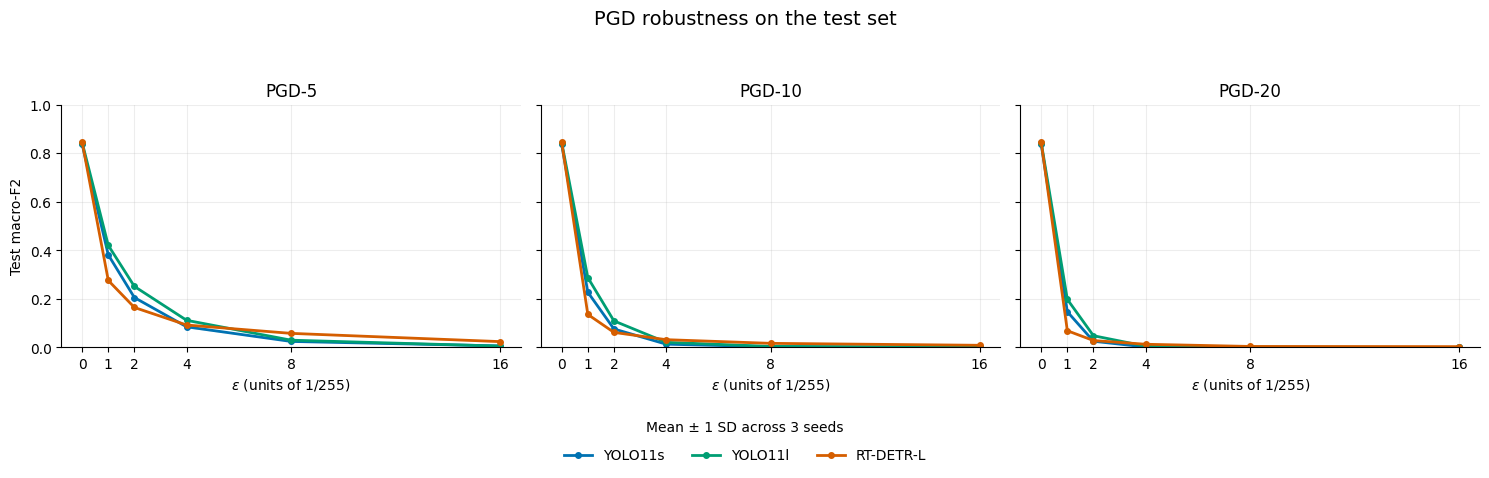

In [ ]:
PGD_MODEL_STYLES = {
    key: {"label": MODEL_LABELS[key], "color": MODEL_COLORS[key]}
    for key in MODEL_KEYS
}

x_values = np.asarray(EPSILON_255)

fig, axes = plt.subplots(
    1,
    len(PGD_STEPS),
    figsize=(5 * len(PGD_STEPS), 4.8),
    sharex=True,
    sharey=True,
    squeeze=False,
)

for ax, steps in zip(axes[0], PGD_STEPS):
    for model_key in MODEL_PATHS:
        style = PGD_MODEL_STYLES[model_key]

        curve = (
            PGD_CURVE[
                (PGD_CURVE["model"] == model_key)
                & (PGD_CURVE["steps"] == steps)
            ]
            .set_index("epsilon_255")
            .reindex(EPSILON_255)
        )

        mean = curve["macro_f2_mean"].to_numpy()
        std = curve["macro_f2_std"].to_numpy()

        ax.plot(
            x_values,
            mean,
            marker="o",
            linewidth=2,
            markersize=4,
            **style,
        )
        ax.fill_between(
            x_values,
            mean - std,
            mean + std,
            color=style["color"],
            alpha=0.16,
            linewidth=0,
        )

    ax.set(
        title=f"PGD-{steps}",
        xlabel=r"$\epsilon$ (units of $1/255$)",
        xticks=EPSILON_255,
        ylim=(0, 1),
        yticks=np.linspace(0, 1, 6),
    )
    ax.grid(alpha=0.22)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0, 0].set_ylabel("Test macro-F2")

fig.suptitle("PGD robustness on the test set", fontsize=14)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=len(MODEL_PATHS),
    frameon=False,
)
fig.text(
    0.5,
    0.10,
    f"Mean ± 1 SD across {len(ATTACK_SEEDS)} seeds",
    ha="center",
    fontsize=10,
)
fig.tight_layout(rect=(0, 0.15, 1, 0.93))

for extension in ("png", "pdf"):
    fig.savefig(
        PGD_DIR / f"pgd_macro_f2_panels.{extension}",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()
plt.close(fig)

### 9.7. PGD summary across models and step counts
Summarize all six PGD curves in one figure. Use model-specific colors and distinct line styles for each step count, showing mean test macro-F2 across seeds.

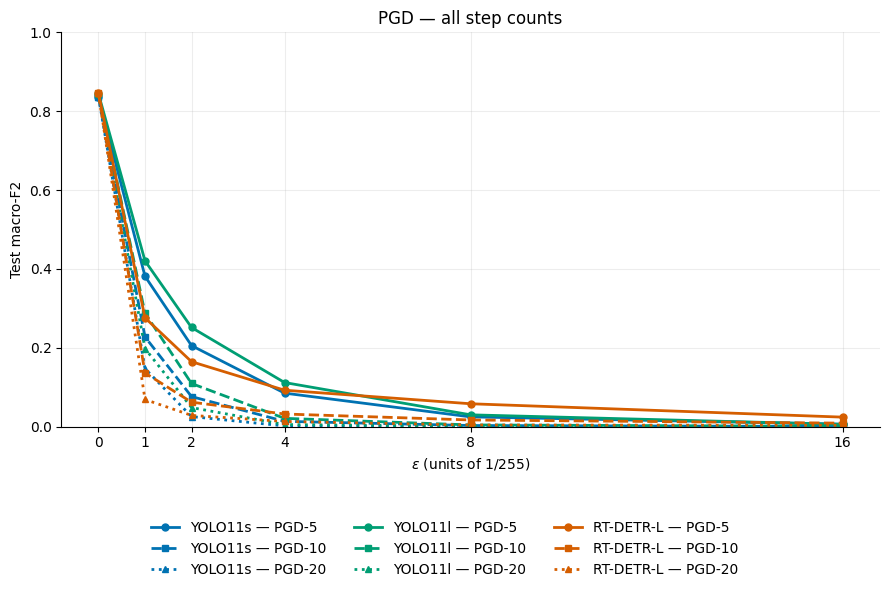

In [ ]:
step_style_options = [("-", "o"), ("--", "s"), (":", "^"), ("-.", "D")]
PGD_STEP_STYLES = {
    steps: step_style_options[index % len(step_style_options)]
    for index, steps in enumerate(PGD_STEPS)
}

fig, ax = plt.subplots(figsize=(9, 6))

for model_key in MODEL_PATHS:
    model_style = PGD_MODEL_STYLES[model_key]

    for steps in PGD_STEPS:
        curve = (
            PGD_CURVE[
                (PGD_CURVE["model"] == model_key)
                & (PGD_CURVE["steps"] == steps)
            ]
            .set_index("epsilon_255")
            .reindex(EPSILON_255)
        )

        linestyle, marker = PGD_STEP_STYLES[steps]

        ax.plot(
            x_values,
            curve["macro_f2_mean"].to_numpy(),
            color=model_style["color"],
            linestyle=linestyle,
            marker=marker,
            linewidth=2,
            markersize=5,
            label=f"{model_style['label']} — PGD-{steps}",
        )

ax.set(
    title="PGD — all step counts",
    xlabel=r"$\epsilon$ (units of $1/255$)",
    ylabel="Test macro-F2",
    xticks=EPSILON_255,
    ylim=(0, 1),
    yticks=np.linspace(0, 1, 6),
)
ax.grid(alpha=0.22)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=len(MODEL_PATHS),
    frameon=False,
)
fig.tight_layout(rect=(0, 0.18, 1, 1))

for extension in ("png", "pdf"):
    fig.savefig(
        PGD_DIR / f"pgd_macro_f2_summary.{extension}",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()
plt.close(fig)

###9.8. Saved results verification
Verify the completed configuration files, aggregated metrics, provenance records, and exported PGD figures in the selected run directory.

In [ ]:
required_files = [
    "attack_config.json", "run_identity.json", "validation_checks.csv",
    "pgd_metrics.csv", "pgd_summary.csv", "pgd_macro_f2_curve.csv",
    "resume_sources.csv", "run_events.jsonl",
    "pgd_macro_f2_panels.png", "pgd_macro_f2_panels.pdf",
    "pgd_macro_f2_summary.png", "pgd_macro_f2_summary.pdf",
]
saved_files = pd.DataFrame([
    {
        "file": name,
        "exists": (PGD_DIR / name).is_file(),
        "bytes": (PGD_DIR / name).stat().st_size if (PGD_DIR / name).is_file() else 0,
    }
    for name in required_files
])
print("Results directory:", PGD_DIR)
print(saved_files.to_string(index=False))
assert saved_files["exists"].all(), "Complete the missing output cells in section 9."
assert saved_files["bytes"].gt(0).all()

PGD_METRICS = pd.read_csv(PGD_DIR / "pgd_metrics.csv")
PGD_SUMMARY = pd.read_csv(PGD_DIR / "pgd_summary.csv")
keys = ["model", "epsilon_255", "steps", "seed"]
expected_summary = pd.MultiIndex.from_product(
    [list(MODEL_PATHS), EPSILON_255, PGD_STEPS, ATTACK_SEEDS], names=keys
)
expected_metrics = pd.MultiIndex.from_product(
    [list(MODEL_PATHS), EPSILON_255, PGD_STEPS, ATTACK_SEEDS, [*CLASS_NAMES, "micro"]],
    names=[*keys, "class"],
)
for frame, columns, expected in [
    (PGD_SUMMARY, keys, expected_summary),
    (PGD_METRICS, [*keys, "class"], expected_metrics),
]:
    actual = pd.MultiIndex.from_frame(frame[columns])
    assert actual.is_unique and len(actual) == len(expected)
    assert expected.difference(actual).empty

expected_run_files = [
    PGD_DIR / f"{model}_eps{epsilon}_seed{seed}_test_metrics.csv"
    for model in MODEL_PATHS for epsilon in EPSILON_255 for seed in ATTACK_SEEDS
]
assert all(path.is_file() for path in expected_run_files)

PGD_TEST_COMPLETE = True
print(f"\nVerified {len(expected_run_files)} completed configuration files.")
print(f"Verified {len(PGD_METRICS)} metric rows and {len(PGD_SUMMARY)} summary rows.")
print("Results can be reloaded without rerunning the attacks.")

Results directory: /content/drive/MyDrive/fire_smoke_robustness/experiments/pgd/edf11658078a6e4f
                    file  exists  bytes
      attack_config.json    True    691
       run_identity.json    True    145
   validation_checks.csv    True  75035
         pgd_metrics.csv    True  55026
         pgd_summary.csv    True  14247
  pgd_macro_f2_curve.csv    True   2948
      resume_sources.csv    True  22214
        run_events.jsonl    True  58734
 pgd_macro_f2_panels.png    True 205001
 pgd_macro_f2_panels.pdf    True  24116
pgd_macro_f2_summary.png    True 257500
pgd_macro_f2_summary.pdf    True  20741

Verified 54 completed configuration files.
Verified 486 metric rows and 162 summary rows.
Results can be reloaded without rerunning the attacks.


### 10. Final Comparisons
Compare YOLO11s, YOLO11l and RT-DETR-L across clean inputs, random sign noise, FGSM and PGD. Reuse completed experiments from Sections 6–9 and export reproducible figures, tables, qualitative examples and runtime measurements.

### 10.1. Configuration and verified result collection
Load completed clean, random-noise, FGSM and PGD test results. Verify configuration coverage, counts and clean references; export one consistent results table without rerunning the full test evaluations.

In [ ]:
# This section consumes completed results. It never reruns Sections 6–9.
from itertools import product
from io import BytesIO
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

PAPER_CONFIG = {
    "schema_version": 1,
    "figure_dpi": 300,
    "example_count": 3,
    "example_seed": int(ATTACK_SEEDS[0]),
    "example_epsilons_255": sorted(set([
        min((e for e in EPSILON_255 if e > 0), key=lambda e: abs(e - max(EPSILON_255) / 2)),
        max(EPSILON_255),
    ])),
    "timing_images": 100,
    "timing_repeats": 3,
    "timing_warmup": 3,
    "timing_batch": 1,
    "timing_seed": int(ATTACK_SEEDS[0]),
}
assert set(MODEL_PATHS) == set(MODEL_KEYS)
assert 0 in EPSILON_255 and max(EPSILON_255) > 0
assert len(ATTACK_SEEDS) >= 2

PAPER_TECHNIQUES = ["random_signs", "fgsm", *[f"pgd_{s}" for s in PGD_STEPS]]
PAPER_LABELS = {"clean": "Clean", "random_signs": "Random sign noise", "fgsm": "FGSM",
                **{f"pgd_{s}": f"PGD-{s}" for s in PGD_STEPS}}
PAPER_STYLE = {
    key: {"color": plt.get_cmap("tab10")(i), "marker": ["o", "s", "^", "D", "v", "P", "X"][i % 7]}
    for i, key in enumerate(PAPER_TECHNIQUES)
}


def paper_csv(frame, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    frame.to_csv(temporary, index=False)
    temporary.replace(path)


def paper_json(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(payload, indent=2, sort_keys=True, allow_nan=False) + "\n")
    temporary.replace(path)


def paper_grid(frame, keys, combinations):
    actual = pd.MultiIndex.from_frame(frame[keys])
    expected = pd.MultiIndex.from_tuples(list(combinations), names=keys)
    assert actual.is_unique, f"Duplicate result keys: {keys}"
    assert len(actual) == len(expected) and expected.difference(actual).empty, (
        f"Incomplete results for {keys}; finish the corresponding evaluation section."
    )


source_definitions = {
    "clean": (BASELINE_DIR, "clean_metrics.csv"),
    "random_signs": (NOISE_DIR, "random_metrics.csv"),
    "fgsm": (FGSM_DIR, "fgsm_metrics.csv"),
    "pgd": (PGD_DIR, "pgd_metrics.csv"),
}
PAPER_SOURCES, source_frames = [], {}
for name, (directory, filename) in source_definitions.items():
    path = directory / filename
    assert path.is_file(), f"Missing {path}; complete or reload Sections 6–9 first."
    protocol_path = PATHS["configs"] / "protocols" / f"{directory.name}.json"
    saved_protocol = json.loads(protocol_path.read_text())
    for key in MODEL_KEYS:
        assert result_protocol_settings(saved_protocol, key) == result_protocol_settings(EXPERIMENT_PROTOCOL, key), (
            f"Incompatible results: {path}, {key}"
        )
    frame = pd.read_csv(path, float_precision="round_trip")
    source_frames[name] = frame
    PAPER_SOURCES.append({"technique": name, "path": str(path), "sha256": file_sha256(path),
                          "protocol_path": str(protocol_path), "rows": len(frame)})

PAPER_ID = content_id({
    "protocol": result_protocol_settings(EXPERIMENT_PROTOCOL),
    "source_hashes": {r["technique"]: r["sha256"] for r in PAPER_SOURCES},
    "config": PAPER_CONFIG,
})
PAPER_DIR = PATHS["paper"] / "results" / PAPER_ID
PAPER_FIGURE_DIR = PAPER_DIR / "figures"
PAPER_TABLE_DIR = PAPER_DIR / "tables"
for directory in (PAPER_DIR, PAPER_FIGURE_DIR, PAPER_TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
save_or_check_json(PAPER_DIR / "analysis_config.json", {
    "paper_id": PAPER_ID, "protocol": result_protocol_settings(EXPERIMENT_PROTOCOL), "config": PAPER_CONFIG,
    "source_hashes": {r["technique"]: r["sha256"] for r in PAPER_SOURCES},
})
paper_json({"protocol_id": PROTOCOL_ID, "sources": PAPER_SOURCES}, PAPER_DIR / "source_provenance.json")
paper_csv(pd.DataFrame(PAPER_SOURCES), PAPER_TABLE_DIR / "source_results.csv")

class_labels = [*CLASS_NAMES, "micro"]
paper_grid(source_frames["clean"], ["model", "class"], product(MODEL_KEYS, class_labels))
paper_grid(source_frames["fgsm"], ["model", "epsilon_255", "class"],
           product(MODEL_KEYS, EPSILON_255, class_labels))
paper_grid(source_frames["random_signs"], ["model", "epsilon_255", "seed", "class"],
           product(MODEL_KEYS, [e for e in EPSILON_255 if e > 0], ATTACK_SEEDS, class_labels))
paper_grid(source_frames["pgd"], ["model", "epsilon_255", "steps", "seed", "class"],
           product(MODEL_KEYS, EPSILON_255, PGD_STEPS, ATTACK_SEEDS, class_labels))

clean_counts, canonical_rows = {}, []
for name, frame in source_frames.items():
    group_keys = [c for c in ["model", "epsilon_255", "steps", "seed"] if c in frame.columns]
    for identity, group in frame.groupby(group_keys, sort=False):
        identity = identity if isinstance(identity, tuple) else (identity,)
        setting = dict(zip(group_keys, identity))
        model_key = setting["model"]
        counts = saved_counts(group, model_key)
        if name == "clean":
            clean_counts[model_key] = counts
        elif int(setting["epsilon_255"]) == 0:
            assert np.array_equal(counts, clean_counts[model_key]), f"Clean mismatch: {setting}"
        technique = f"pgd_{int(setting['steps'])}" if name == "pgd" else name
        for label, count in zip(class_labels, [*counts, counts.sum(axis=0)]):
            canonical_rows.append({
                "model": model_key, "technique": technique,
                "epsilon_255": int(setting.get("epsilon_255", 0)),
                "seed": int(setting.get("seed", -1)),
                "class": label, "confidence": float(CONFIDENCE_THRESHOLDS[model_key]),
                **metrics_from_counts(count),
            })

# Noise epsilon zero reuses the clean reference; these copies are not independent runs.
for record in list(canonical_rows):
    if record["technique"] == "clean":
        for seed in ATTACK_SEEDS:
            canonical_rows.append({**record, "technique": "random_signs", "seed": int(seed)})
PAPER_METRICS = pd.DataFrame(canonical_rows)
run_rows = []
for identity, frame in PAPER_METRICS.groupby(["model", "technique", "epsilon_255", "seed"], sort=False):
    micro = frame.set_index("class").loc["micro"]
    run_rows.append(dict(zip(["model", "technique", "epsilon_255", "seed"], identity)) | {
        "macro_f2": frame.loc[frame["class"].isin(CLASS_NAMES), "f2"].mean(),
        **{f"micro_{m}": micro[m] for m in ["precision", "recall", "f1", "f2"]},
        **{m: int(micro[m]) for m in ["tp", "fp", "fn"]},
    })
PAPER_RUNS = pd.DataFrame(run_rows)
PAPER_CURVES = PAPER_RUNS.groupby(["model", "technique", "epsilon_255"], as_index=False).agg(
    macro_f2_mean=("macro_f2", "mean"), macro_f2_std=("macro_f2", "std"),
    runs=("seed", "size"), micro_recall_mean=("micro_recall", "mean"),
    fp_mean=("fp", "mean"), fn_mean=("fn", "mean"),
)
PAPER_CURVES["macro_f2_std"] = PAPER_CURVES["macro_f2_std"].fillna(0.0)
PAPER_CLEAN = PAPER_RUNS[PAPER_RUNS["technique"] == "clean"].set_index("model")
PAPER_CURVES["clean_macro_f2"] = PAPER_CURVES["model"].map(PAPER_CLEAN["macro_f2"])
assert PAPER_CURVES["clean_macro_f2"].gt(0).all(), "Relative retention requires a nonzero baseline."
PAPER_CURVES["drop_pp"] = 100 * (PAPER_CURVES["clean_macro_f2"] - PAPER_CURVES["macro_f2_mean"])
PAPER_CURVES["retained_percent"] = 100 * PAPER_CURVES["macro_f2_mean"] / PAPER_CURVES["clean_macro_f2"]
for name, frame in [("all_class_metrics", PAPER_METRICS), ("all_run_metrics", PAPER_RUNS), ("all_curves", PAPER_CURVES)]:
    paper_csv(frame, PAPER_TABLE_DIR / f"{name}.csv")

PAPER_FIGURES = []
PAPER_CAPTIONS = {}


def paper_figure(fig, name, caption):
    for extension in ("png", "pdf"):
        path = PAPER_FIGURE_DIR / f"{name}.{extension}"
        buffer = BytesIO()
        fig.savefig(buffer, format=extension, dpi=PAPER_CONFIG["figure_dpi"], bbox_inches="tight", facecolor="white")
        payload = buffer.getvalue()
        assert len(payload) > 100, f"Empty figure export: {name}.{extension}"
        temporary = path.with_name(path.name + ".tmp")
        temporary.write_bytes(payload)
        temporary.replace(path)
        if str(path) not in PAPER_FIGURES:
            PAPER_FIGURES.append(str(path))
    PAPER_CAPTIONS[name] = caption
    paper_json(PAPER_CAPTIONS, PAPER_DIR / "figure_captions.json")
    plt.show()
    plt.close(fig)


def paper_axis(ax, ylabel="Macro-F2", bounded=True):
    ax.set_xlabel(r"Perturbation budget $\epsilon$ ($/255$)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(sorted(EPSILON_255))
    if bounded:
        ax.set_ylim(-0.025, 1.025)
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)


def paper_curve(ax, frame, label, color, marker="o", relative=False):
    frame = frame.sort_values("epsilon_255")
    x = frame["epsilon_255"].to_numpy()
    scale = 100 / frame["clean_macro_f2"].to_numpy() if relative else 1.0
    y = frame["macro_f2_mean"].to_numpy() * scale
    spread = frame["macro_f2_std"].to_numpy() * scale
    ax.plot(x, y, color=color, marker=marker, markersize=4, linewidth=1.6, label=label)
    # Only stochastic techniques have seed bands. The band is not a confidence interval.
    if frame["runs"].max() > 1:
        ax.fill_between(x, y - spread, y + spread, color=color, alpha=0.12)


print(f"Validated completed results for {len(MODEL_KEYS)} models and {len(TEST_ROWS)} test images.")
print("Seed -1 denotes clean/FGSM (no stochastic attack seed). Bands show sample SD across attack seeds.")
print("Paper outputs:", PAPER_DIR)


Validated completed results for 3 models and 750 test images.
Seed -1 denotes clean/FGSM (no stochastic attack seed). Bands show sample SD across attack seeds.
Paper outputs: /content/drive/MyDrive/fire_smoke_robustness/paper/results/c539c100ecfeecfe


### 10.2. Clean performance and model size
Compare clean performance, validation-selected thresholds and parameter counts from the selected checkpoints. Reuse cached model metadata.

,model,parameters_m,confidence,macro_f2,micro_recall,fp,fn
0,yolo11s,9.428566,0.240,0.836140,0.853728,258,153
1,yolo11l,25.312022,0.223,0.843835,0.862333,252,144
2,rtdetr_l,32.810186,0.379,0.845078,0.866157,263,140


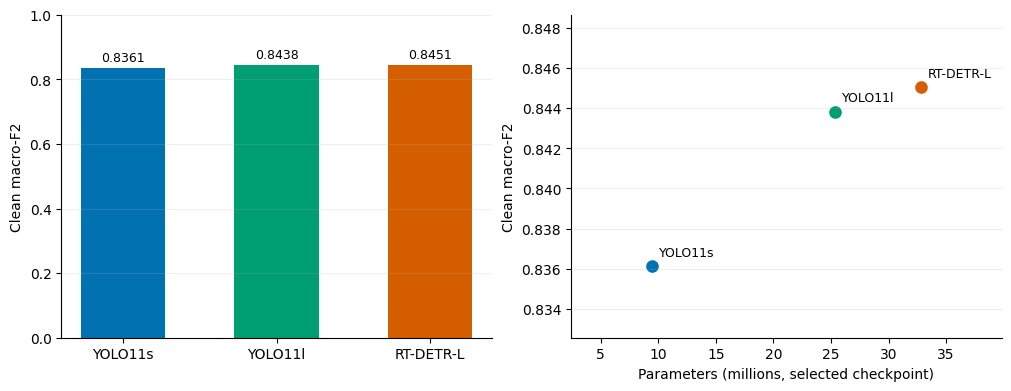

In [ ]:
# Parameter counts come from the selected two-class checkpoints, before fusion.
complexity_rows = []
for model_key in MODEL_KEYS:
    checkpoint_hash = MODEL_REGISTRY["models"][model_key]["checkpoint_sha256"]
    cache_path = PATHS["paper"] / "model_metadata" / f"{model_key}_{checkpoint_hash}.json"
    if cache_path.is_file():
        record = json.loads(cache_path.read_text())
        assert record["checkpoint_sha256"] == checkpoint_hash and record["model"] == model_key
    else:
        detector = MODEL_CLASSES[model_key](MODEL_PATHS[model_key])
        record = {"model": model_key, "checkpoint_sha256": checkpoint_hash,
                  "parameters": sum(p.numel() for p in detector.model.parameters()),
                  "checkpoint_bytes": Path(MODEL_PATHS[model_key]).stat().st_size}
        paper_json(record, cache_path)
        del detector
    complexity_rows.append(record)
PAPER_MODEL_INFO = pd.DataFrame(complexity_rows)
PAPER_CLEAN_TABLE = PAPER_CLEAN.reset_index().merge(PAPER_MODEL_INFO, on="model", validate="one_to_one")
PAPER_CLEAN_TABLE["parameters_m"] = PAPER_CLEAN_TABLE["parameters"] / 1e6
PAPER_CLEAN_TABLE["confidence"] = PAPER_CLEAN_TABLE["model"].map(CONFIDENCE_THRESHOLDS)
paper_csv(PAPER_CLEAN_TABLE, PAPER_TABLE_DIR / "clean_model_comparison.csv")
display(PAPER_CLEAN_TABLE[["model", "parameters_m", "confidence", "macro_f2", "micro_recall", "fp", "fn"]])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
clean = PAPER_CLEAN_TABLE.set_index("model").loc[list(MODEL_KEYS)]
positions = np.arange(len(MODEL_KEYS))
axes[0].bar(positions, clean["macro_f2"], color=[MODEL_COLORS[k] for k in MODEL_KEYS], width=0.55)
axes[0].set_xticks(positions, [MODEL_LABELS[k] for k in MODEL_KEYS])
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Clean macro-F2")
for i, value in enumerate(clean["macro_f2"]):
    axes[0].text(i, value + 0.02, f"{value:.4f}", ha="center", fontsize=9)
for key, row in clean.iterrows():
    axes[1].scatter(row["parameters_m"], row["macro_f2"], color=MODEL_COLORS[key], s=65)
    axes[1].annotate(MODEL_LABELS[key], (row["parameters_m"], row["macro_f2"]),
                     xytext=(5, 7), textcoords="offset points", fontsize=9)
axes[1].set_xlabel("Parameters (millions, selected checkpoint)")
axes[1].set_ylabel("Clean macro-F2")
axes[1].margins(x=0.3, y=0.4)
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
paper_figure(fig, "clean_accuracy_and_size",
             "Clean test performance and parameter counts of the selected two-class checkpoints. "
             "Confidence thresholds were fixed on validation. No statistical significance is implied by small differences.")


### 10.3. Perturbation techniques within each model
Compare random sign noise, FGSM and every configured PGD step count for each model. Plot full-test mean macro-F2 with attack-seed standard deviation bands.

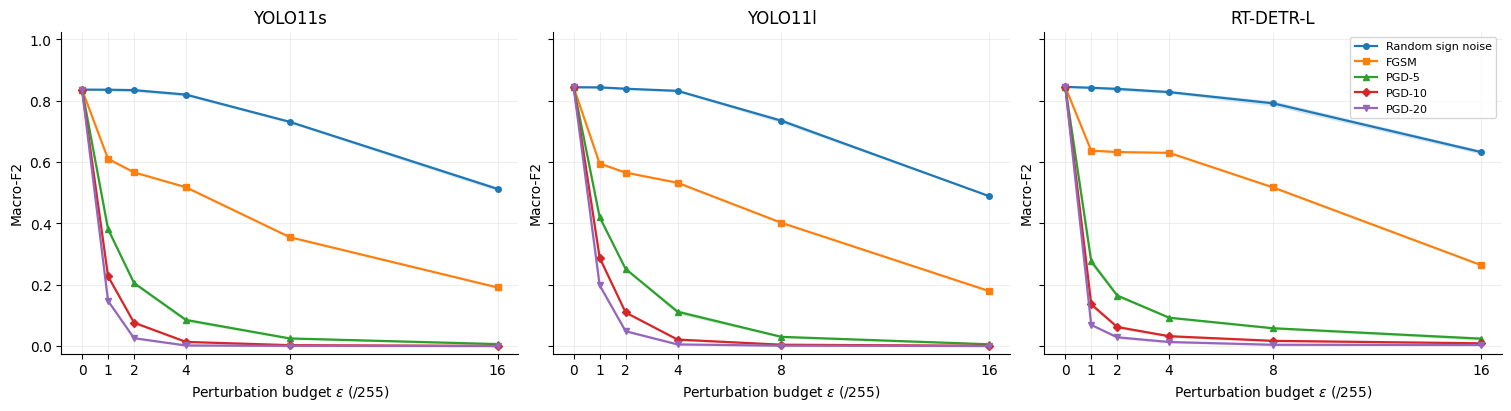

In [ ]:
fig, axes = plt.subplots(1, len(MODEL_KEYS), figsize=(5 * len(MODEL_KEYS), 4),
                         sharey=True, squeeze=False, layout="constrained")
for ax, model_key in zip(axes.flat, MODEL_KEYS):
    for technique in PAPER_TECHNIQUES:
        frame = PAPER_CURVES[(PAPER_CURVES["model"] == model_key) & (PAPER_CURVES["technique"] == technique)]
        paper_curve(ax, frame, PAPER_LABELS[technique], **PAPER_STYLE[technique])
    paper_axis(ax)
    ax.set_title(MODEL_LABELS[model_key])
axes[0, -1].legend(fontsize=8, loc="upper right")
paper_figure(fig, "all_techniques_by_model",
             "Full-test macro-F2 under random sign noise, FGSM and all configured PGD step counts. "
             "Each panel shows one model. Bands are ±1 sample SD across attack seeds; FGSM has no seed band. "
             "Epsilon zero is the shared clean reference. Thresholds remain fixed.")


### 10.4. Class-specific recall under PGD
Compare Fire and Smoke recall across models using the largest configured PGD step count. Reuse the full-test results and show mean recall with standard deviation across attack seeds.

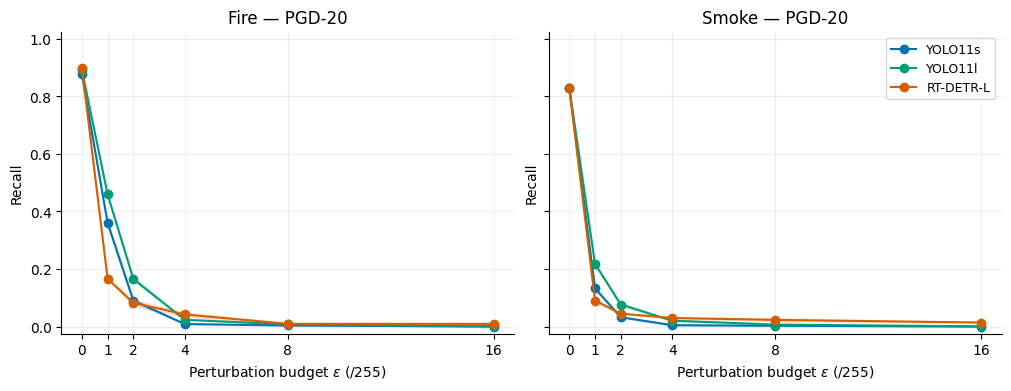

In [ ]:
PAPER_PGD_KEY = f"pgd_{max(PGD_STEPS)}"

PAPER_CLASS_RECALL = (
    PAPER_METRICS[
        PAPER_METRICS["technique"].eq(PAPER_PGD_KEY)
        & PAPER_METRICS["class"].isin(CLASS_NAMES)
    ]
    .groupby(["model", "class", "epsilon_255"], as_index=False)
    .agg(
        recall_mean=("recall", "mean"),
        recall_std=("recall", "std"),
    )
)

paper_csv(
    PAPER_CLASS_RECALL,
    PAPER_TABLE_DIR / "pgd_class_recall.csv",
)

fig, axes = plt.subplots(
    1, len(CLASS_NAMES),
    figsize=(10, 3.8),
    sharey=True,
    squeeze=False,
    layout="constrained",
)

for ax, class_name in zip(axes.flat, CLASS_NAMES):
    for model_key in MODEL_KEYS:
        curve = PAPER_CLASS_RECALL[
            PAPER_CLASS_RECALL["model"].eq(model_key)
            & PAPER_CLASS_RECALL["class"].eq(class_name)
        ].sort_values("epsilon_255")

        x, mean, std = (
            curve[column].to_numpy()
            for column in [
                "epsilon_255", "recall_mean", "recall_std"
            ]
        )

        ax.plot(
            x, mean,
            marker="o",
            color=MODEL_COLORS[model_key],
            label=MODEL_LABELS[model_key],
        )
        ax.fill_between(
            x, mean - std, mean + std,
            color=MODEL_COLORS[model_key],
            alpha=0.12,
        )

    paper_axis(ax, "Recall")
    ax.set_title(
        f"{class_name} — {PAPER_LABELS[PAPER_PGD_KEY]}"
    )

axes.flat[-1].legend(fontsize=9)

paper_figure(
    fig,
    "pgd_class_recall",
    f"Per-class recall under {PAPER_LABELS[PAPER_PGD_KEY]} "
    "on the full test set. Bands show ±1 sample SD across "
    "attack seeds, not confidence intervals. Confidence "
    "thresholds remain fixed from validation.",
)

### 10.5. Qualitative comparison on a shared test image
Compare clean, random-noise, FGSM and PGD predictions on the same test image and perturbation budget. Select the image reproducibly from ground-truth class presence, independently of attack outcomes. Reuse saved floating-point examples and predictions.

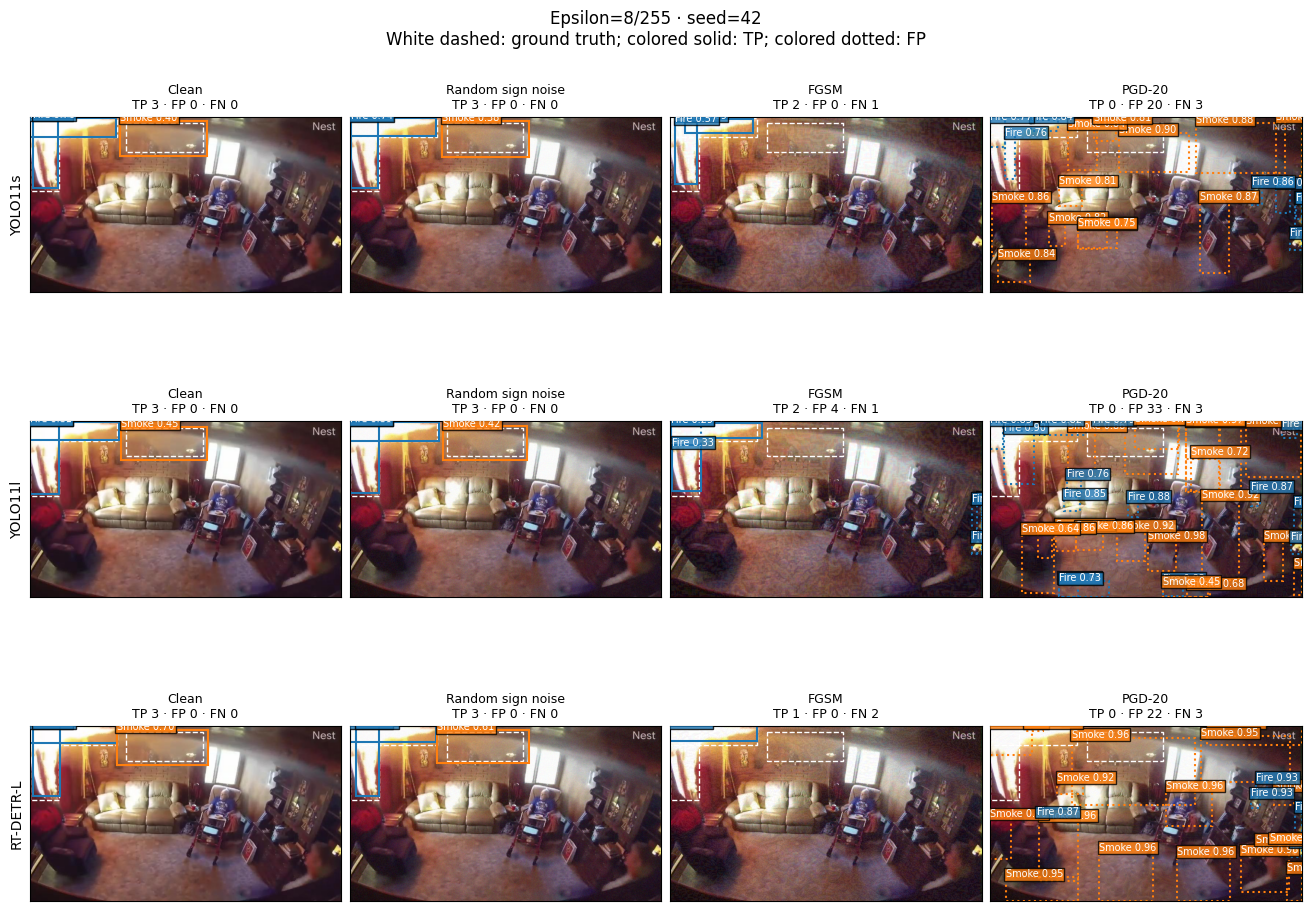

In [ ]:
PAPER_FOCUS_EPSILON = int(
    min(PAPER_CONFIG["example_epsilons_255"])
)
assert (
    PAPER_FOCUS_EPSILON in EPSILON_255
    and PAPER_FOCUS_EPSILON > 0
)

example_seed = int(PAPER_CONFIG["example_seed"])

# Prefer an image containing both classes.
# Selection does not depend on model predictions.
candidates = [
    row for row in TEST_ROWS
    if all(row[name] > 0 for name in CLASS_NAMES)
]
example_row = min(
    candidates or TEST_ROWS,
    key=lambda row: (
        image_seed(row["image_path"], example_seed),
        row["image_path"],
    ),
)

example_methods = [
    "clean", "random_signs", "fgsm", PAPER_PGD_KEY
]

example_config = {
    "implementation": "compact_qualitative_v1",
    "protocol": result_protocol_settings(EXPERIMENT_PROTOCOL),
    "software": numerical_environment(ENVIRONMENT),
    "image_path": example_row["image_path"],
    "epsilon_255": PAPER_FOCUS_EPSILON,
    "seed": example_seed,
    "methods": example_methods,
}

example_dir = (
    PATHS["paper"] / "qualitative" / content_id(example_config)
)
example_dir.mkdir(parents=True, exist_ok=True)
save_or_check_json(
    example_dir / "config.json", example_config
)


def paper_load_original(row):
    loader = load_inference_source(
        source=[str(DATASET_ROOT / row["image_path"])],
        batch=1,
    )
    loaded_paths, images, _ = next(iter(loader))

    assert Path(loaded_paths[0]).resolve() == (
        DATASET_ROOT / row["image_path"]
    ).resolve()
    assert images[0].shape[:2] == (
        row["height"], row["width"]
    )
    return images[0]


bgr = paper_load_original(example_row)

label_path = DATASET_ROOT / example_row["label_path"]
labels = (
    np.loadtxt(label_path, ndmin=2)
    if label_path.read_text().strip()
    else np.empty((0, 5))
)

center = labels[:, 1:3] * [
    example_row["width"], example_row["height"]
]
size = labels[:, 3:5] * [
    example_row["width"], example_row["height"]
]
gt_boxes = np.column_stack([
    center - size / 2,
    center + size / 2,
])
gt_boxes[:, [0, 2]] = gt_boxes[:, [0, 2]].clip(
    0, example_row["width"]
)
gt_boxes[:, [1, 3]] = gt_boxes[:, [1, 3]].clip(
    0, example_row["height"]
)

fig, axes = plt.subplots(
    len(MODEL_KEYS), len(example_methods),
    figsize=(13, 3.2 * len(MODEL_KEYS)),
    squeeze=False,
    layout="constrained",
)

example_counts = []

for i, model_key in enumerate(MODEL_KEYS):
    cache = example_dir / f"{model_key}.npz"
    marker = cache.with_suffix(".json")
    arrays = None

    if cache.is_file() and marker.is_file():
        try:
            assert (
                json.loads(marker.read_text())["sha256"]
                == file_sha256(cache)
            )

            with np.load(cache, allow_pickle=False) as saved:
                arrays = {
                    key: saved[key] for key in saved.files
                }

            for method in example_methods:
                assert arrays[f"rgb_{method}"].shape == (
                    *bgr.shape[:2], 3
                )
                assert arrays[f"pred_{method}"].shape[1] == 6

        except (
            AssertionError, KeyError, ValueError,
            OSError, zipfile.BadZipFile,
        ):
            arrays = None

    if arrays is None:
        network = load_attack_model(model_key)
        detector = MODEL_CLASSES[model_key](
            MODEL_PATHS[model_key]
        )
        predictor = predictor_for_model(
            model_key,
            PreparedYOLOPredictor,
            PreparedRTDETRPredictor,
        )

        try:
            x = rgb_tensor(bgr).to(ATTACK_DEVICE)
            targets = attack_targets(example_row, model_key)

            direction, _, _ = fgsm_direction(
                network, x, targets, model_key
            )
            checkpoints = pgd_checkpoints(
                network, x, targets, model_key,
                example_row["image_path"],
                PAPER_FOCUS_EPSILON,
                example_seed,
            )
            noisy = add_random_sign_noise(
                bgr,
                example_row["image_path"],
                PAPER_FOCUS_EPSILON,
                example_seed,
            )

            variants = {
                "clean": x,
                "random_signs": rgb_tensor(noisy).to(
                    ATTACK_DEVICE
                ),
                "fgsm": apply_fgsm(
                    x, direction, PAPER_FOCUS_EPSILON
                ),
                PAPER_PGD_KEY: checkpoints[max(PGD_STEPS)],
            }

            arrays = {}

            for method, adversarial in variants.items():
                assert bool(torch.isfinite(adversarial).all())
                assert (
                    float((adversarial - x).abs().max())
                    <= PAPER_FOCUS_EPSILON / 255 + 1e-6
                )

                with torch.no_grad():
                    predictor.prepared_batch = (
                        differentiable_preprocess(
                            adversarial, model_key
                        ).detach()
                    )

                result = detector.predict(
                    source=[bgr],
                    predictor=predictor,
                    **{**FGSM_PREDICT_ARGS, "batch": 1},
                )[0]

                pred = (
                    result.boxes.data.cpu().numpy()
                    .astype(np.float64)
                )
                arrays[f"pred_{method}"] = pred[
                    pred[:, 4]
                    >= CONFIDENCE_THRESHOLDS[model_key]
                ]
                arrays[f"rgb_{method}"] = (
                    adversarial.detach().cpu().numpy()[0]
                    .transpose(1, 2, 0)
                )

            temporary = cache.with_suffix(".tmp")
            with temporary.open("wb") as stream:
                np.savez_compressed(stream, **arrays)
            temporary.replace(cache)

            paper_json(
                {"sha256": file_sha256(cache)},
                marker,
            )

        finally:
            predictor.prepared_batch = None
            network.cpu()
            detector.to("cpu")
            detector.predictor = None
            del network, detector

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    else:
        print(f"[LOAD] {model_key}: qualitative example")

    for j, method in enumerate(example_methods):
        ax = axes[i, j]

        pred, correct, support = match_predictions(
            arrays[f"pred_{method}"].copy(),
            example_row,
        )

        tp = int(correct.sum())
        fp = int((~correct).sum())
        fn = int(support.sum() - correct.sum())

        example_counts.append({
            "model": model_key,
            "method": method,
            "tp": tp,
            "fp": fp,
            "fn": fn,
        })

        ax.imshow(arrays[f"rgb_{method}"])

        for box in gt_boxes:
            ax.add_patch(Rectangle(
                box[:2],
                box[2] - box[0],
                box[3] - box[1],
                fill=False,
                edgecolor="white",
                linestyle="--",
                linewidth=1,
            ))

        for box, matched in zip(pred, correct):
            color = plt.get_cmap("tab10")(int(box[5]))

            ax.add_patch(Rectangle(
                box[:2],
                box[2] - box[0],
                box[3] - box[1],
                fill=False,
                edgecolor=color,
                linestyle="-" if matched else ":",
                linewidth=1.5,
            ))
            ax.text(
                box[0], box[1],
                f"{CLASS_NAMES[int(box[5])]} {box[4]:.2f}",
                color="white",
                fontsize=7,
                clip_on=True,
                bbox={
                    "facecolor": color,
                    "alpha": 0.8,
                    "pad": 1,
                },
            )

        ax.set_title(
            f"{PAPER_LABELS[method]}\n"
            f"TP {tp} · FP {fp} · FN {fn}",
            fontsize=9,
        )
        if j == 0:
            ax.set_ylabel(MODEL_LABELS[model_key])

        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle(
    f"Epsilon={PAPER_FOCUS_EPSILON}/255 · seed={example_seed}\n"
    "White dashed: ground truth; colored solid: TP; "
    "colored dotted: FP"
)

paper_csv(
    pd.DataFrame(example_counts),
    PAPER_TABLE_DIR / "qualitative_example_counts.csv",
)
paper_json(
    example_config,
    PAPER_DIR / "qualitative_example_config.json",
)

paper_figure(
    fig,
    "qualitative_comparison",
    f"Same image ({example_row['image_path']}) across models "
    f"and perturbations at epsilon={PAPER_FOCUS_EPSILON}/255, "
    f"seed={example_seed}. Each gradient attack targets its own "
    "model. Selection uses ground-truth class presence and seeded "
    "ordering, independently of prediction outcomes. Predictions "
    "use floating-point perturbations; displayed images are illustrative.",
)

### 10.6. Attack-generation runtime
Measure random-noise, FGSM and PGD generation time at the selected perturbation budget on a fixed test subset. Reuse the existing implementations, warm up execution and synchronize GPU operations. Save completed measurements per image and summarize runtime in one table. Exclude data loading, final inference and metric computation.

In [ ]:
import subprocess

timing_rows = sorted(
    TEST_ROWS,
    key=lambda row: (
        image_seed(
            row["image_path"], PAPER_CONFIG["timing_seed"]
        ),
        row["image_path"],
    ),
)[:PAPER_CONFIG["timing_images"]]

cpu_model = platform.processor()
if Path("/proc/cpuinfo").is_file():
    cpu_model = next(
        (
            line.split(":", 1)[1].strip()
            for line in Path("/proc/cpuinfo").read_text().splitlines()
            if line.startswith("model name")
        ),
        cpu_model,
    )

driver = None
if torch.cuda.is_available():
    try:
        driver = subprocess.check_output(
            [
                "nvidia-smi",
                "--query-gpu=driver_version",
                "--format=csv,noheader",
            ],
            text=True,
        ).strip()
    except (OSError, subprocess.CalledProcessError):
        pass

timing_config = {
    "implementation": "compact_attack_timing_v1",
    "protocol": result_protocol_settings(EXPERIMENT_PROTOCOL),
    "software": numerical_environment(ENVIRONMENT),
    "python": platform.python_version(),
    "gpu": (
        torch.cuda.get_device_name(ATTACK_DEVICE)
        if torch.cuda.is_available()
        else None
    ),
    "driver": driver,
    "cpu": cpu_model,
    "threads": torch.get_num_threads(),
    "interop_threads": torch.get_num_interop_threads(),
    "precision": str(torch.backends.fp32_precision),
    "matmul_precision": str(
        torch.backends.cuda.matmul.fp32_precision
    ),
    "cudnn_precision": str(
        torch.backends.cudnn.fp32_precision
    ),
    "cudnn_benchmark": torch.backends.cudnn.benchmark,
    "epsilon_255": PAPER_FOCUS_EPSILON,
    "pgd_checkpoints": list(PGD_STEPS),
    "seed": PAPER_CONFIG["timing_seed"],
    "repeats": PAPER_CONFIG["timing_repeats"],
    "warmup": PAPER_CONFIG["timing_warmup"],
    "batch": 1,
    "images": [row["image_path"] for row in timing_rows],
    "scope": (
        "Native generation from preloaded inputs; gradient attacks "
        "include preprocessing and loss. Noise uses CPU BGR uint8; "
        "gradient attacks use device-resident FP32 RGB/targets. "
        "PGD includes intermediate checkpoint copies. Excludes "
        "loading, final inference and metric matching."
    ),
}

timing_id = content_id(timing_config)
timing_dir = PATHS["paper"] / "timing" / timing_id
timing_dir.mkdir(parents=True, exist_ok=True)

save_or_check_json(
    timing_dir / "config.json", timing_config
)
paper_json(
    timing_config,
    PAPER_DIR / "attack_timing_config.json",
)


def timing_file(model_key, row):
    return timing_dir / (
        f"{model_key}_{content_id(row['image_path'])}.csv"
    )


def read_timing(model_key, row):
    path = timing_file(model_key, row)
    if not path.is_file():
        return None

    try:
        frame = pd.read_csv(path)
        methods = (
            ["random_signs"]
            if model_key == "shared_noise"
            else ["fgsm", PAPER_PGD_KEY]
        )

        paper_grid(
            frame,
            ["method", "repeat"],
            product(methods, range(timing_config["repeats"])),
        )

        assert frame["timing_id"].eq(timing_id).all()
        assert frame["model"].eq(model_key).all()
        assert frame["image_path"].eq(row["image_path"]).all()
        assert (
            np.isfinite(frame["ms"]).all()
            and frame["ms"].gt(0).all()
        )
        return frame

    except (
        AssertionError, KeyError, ValueError,
        pd.errors.ParserError,
    ):
        return None


def measure_generation(function):
    if torch.cuda.is_available():
        torch.cuda.synchronize(ATTACK_DEVICE)

    start = time.perf_counter()
    result = function()

    if torch.cuda.is_available():
        torch.cuda.synchronize(ATTACK_DEVICE)

    elapsed = 1000 * (time.perf_counter() - start)
    del result
    return elapsed


print(
    f"Timing: {len(timing_rows)} images, "
    f"epsilon={PAPER_FOCUS_EPSILON}/255, "
    f"{timing_config['repeats']} repeats; "
    "measuring missing images only."
)

for model_key in ["shared_noise", *MODEL_KEYS]:
    missing = [
        row for row in timing_rows
        if read_timing(model_key, row) is None
    ]

    if not missing:
        print(f"[LOAD] {model_key}: timings")
        continue

    network = (
        None
        if model_key == "shared_noise"
        else load_attack_model(model_key)
    )

    try:
        for image_index, row in enumerate(
            tqdm(missing, desc=f"{model_key} — timing")
        ):
            bgr = paper_load_original(row)

            if model_key == "shared_noise":
                functions = {
                    "random_signs": lambda: add_random_sign_noise(
                        bgr,
                        row["image_path"],
                        PAPER_FOCUS_EPSILON,
                        timing_config["seed"],
                    )
                }

            else:
                x = rgb_tensor(bgr).to(ATTACK_DEVICE)
                targets = attack_targets(row, model_key)

                def complete_fgsm():
                    direction, _, _ = fgsm_direction(
                        network, x, targets, model_key
                    )
                    return apply_fgsm(
                        x, direction, PAPER_FOCUS_EPSILON
                    )

                functions = {
                    "fgsm": complete_fgsm,
                    PAPER_PGD_KEY: lambda: pgd_checkpoints(
                        network,
                        x,
                        targets,
                        model_key,
                        row["image_path"],
                        PAPER_FOCUS_EPSILON,
                        timing_config["seed"],
                    ),
                }

            records = []

            for method, function in functions.items():
                if image_index == 0:
                    for _ in range(timing_config["warmup"]):
                        function()

                for repeat in range(timing_config["repeats"]):
                    records.append({
                        "timing_id": timing_id,
                        "model": model_key,
                        "image_path": row["image_path"],
                        "method": method,
                        "repeat": repeat,
                        "ms": measure_generation(function),
                        "session": SETUP_ID,
                    })

            paper_csv(
                pd.DataFrame(records),
                timing_file(model_key, row),
            )

    finally:
        if network is not None:
            network.cpu()
            del network

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

frames = [
    read_timing(model_key, row)
    for model_key in ["shared_noise", *MODEL_KEYS]
    for row in timing_rows
]
assert all(frame is not None for frame in frames)

PAPER_TIMINGS = pd.concat(frames, ignore_index=True)

# First take the median of repeats for each image.
image_times = (
    PAPER_TIMINGS
    .groupby(
        ["model", "method", "image_path"], as_index=False
    )["ms"]
    .median()
)

# Then summarize the distribution across images.
PAPER_TIMING_TABLE = (
    image_times
    .groupby(["model", "method"], as_index=False)
    .agg(
        median_ms=("ms", "median"),
        p95_ms=("ms", lambda values: values.quantile(0.95)),
        images=("image_path", "nunique"),
    )
)
assert PAPER_TIMING_TABLE["images"].eq(len(timing_rows)).all()

paper_csv(
    PAPER_TIMINGS,
    PAPER_TABLE_DIR / "attack_timing_measurements.csv",
)
paper_csv(
    PAPER_TIMING_TABLE,
    PAPER_TABLE_DIR / "attack_timing_table.csv",
)

display(
    PAPER_TIMING_TABLE.assign(
        model=PAPER_TIMING_TABLE["model"].map({
            **MODEL_LABELS,
            "shared_noise": "Shared noise (CPU)",
        }),
        method=PAPER_TIMING_TABLE["method"].map(PAPER_LABELS),
    ).round(3)
)

print(
    "Milliseconds per image: median of repeats per image, "
    "then median/P95 across images."
)
print(
    "Single configured seed for timing; these repetitions "
    "are not extra robustness trials."
)

Timing: 100 images, epsilon=8/255, 3 repeats; measuring missing images only.


shared_noise — timing:   0%|          | 0/100 [00:00<?, ?it/s]

yolo11s — timing:   0%|          | 0/100 [00:00<?, ?it/s]

yolo11l — timing:   0%|          | 0/100 [00:00<?, ?it/s]

rtdetr_l — timing:   0%|          | 0/100 [00:00<?, ?it/s]

### 10.7. Visual illustration of perturbation techniques
Show the original image alongside random-noise, FGSM and PGD inputs. Display amplified signed perturbations below each image using a common scale. Reuse the saved examples without rerunning attacks.

In [ ]:
PAPER_ILLUSTRATION_MODEL = MODEL_KEYS[0]

illustration_methods = [
    "clean", "random_signs", "fgsm", PAPER_PGD_KEY
]

cache = example_dir / f"{PAPER_ILLUSTRATION_MODEL}.npz"
marker = cache.with_suffix(".json")

assert cache.is_file() and marker.is_file(), (
    "Run Section 10.5 first."
)
assert (
    json.loads(marker.read_text())["sha256"]
    == file_sha256(cache)
)

with np.load(cache, allow_pickle=False) as saved:
    illustration_images = {
        method: saved[f"rgb_{method}"].copy()
        for method in illustration_methods
    }

original = illustration_images["clean"]
epsilon = float(example_config["epsilon_255"]) / 255.0

# One common amplification factor for all perturbations.
# Zero change is represented by neutral gray.
gain = 1.0 / (2.0 * epsilon)

fig, axes = plt.subplots(
    2, len(illustration_methods),
    figsize=(13, 6.4),
    squeeze=False,
    layout="constrained",
)

for column, method in enumerate(illustration_methods):
    rgb = illustration_images[method]
    delta = rgb - original

    assert rgb.shape == original.shape
    assert np.isfinite(rgb).all()
    assert float(np.abs(delta).max()) <= epsilon + 1e-6

    # Actual image: no artificial amplification.
    axes[0, column].imshow(
        rgb, interpolation="nearest"
    )
    axes[0, column].set_title(
        PAPER_LABELS[method], fontsize=11
    )

    # Visualization only: signed RGB perturbation.
    amplified_delta = np.clip(
        0.5 + gain * delta, 0.0, 1.0
    )
    axes[1, column].imshow(
        amplified_delta, interpolation="nearest"
    )
    axes[1, column].set_title(
        "Zero perturbation"
        if method == "clean"
        else f"Signed perturbation ×{gain:.1f}",
        fontsize=10,
    )

    for row in range(2):
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])

axes[0, 0].set_ylabel(
    "Image supplied to preprocessing", fontsize=10
)
axes[1, 0].set_ylabel(
    "Perturbation visualization", fontsize=10
)

fig.suptitle(
    f"{MODEL_LABELS[PAPER_ILLUSTRATION_MODEL]} · "
    f"epsilon={example_config['epsilon_255']}/255 · "
    f"seed={example_config['seed']}",
    fontsize=12,
)

paper_json(
    {
        "model": PAPER_ILLUSTRATION_MODEL,
        "image_path": example_config["image_path"],
        "epsilon_255": example_config["epsilon_255"],
        "seed": example_config["seed"],
        "methods": illustration_methods,
        "display_gain": gain,
        "perturbation_display": (
            "clip(0.5 + gain * "
            "(x_perturbed - x_clean), 0, 1)"
        ),
        "cached_examples_sha256": file_sha256(cache),
    },
    PAPER_DIR / "technique_illustration_config.json",
)

paper_figure(
    fig,
    "perturbation_techniques_example",
    "Illustration of random sign noise, FGSM and "
    f"{PAPER_LABELS[PAPER_PGD_KEY]} at "
    f"epsilon={example_config['epsilon_255']}/255. "
    "Gradient attacks target "
    f"{MODEL_LABELS[PAPER_ILLUSTRATION_MODEL]}. "
    "The top row shows the original and perturbed RGB inputs "
    "without detection boxes. The bottom row shows signed RGB "
    f"differences magnified by {gain:.2f} around neutral gray. "
    "Gray denotes zero change; brighter/darker values indicate "
    "positive/negative changes in each color channel. "
    "This amplification is for visualization only and is not "
    "applied to model inputs. Raster display may conceal "
    "small perturbations.",
)